# Classificação binária da condição periodontal a partir do microbioma oral utilizando aprendizado de máquina

**Objetivo:** avaliar se a composição do microbioma oral contém informação útil para distinguir participantes com e sem periodontite e verificar se a inclusão de variáveis demográficas, comportamentais e clínicas do NHANES acrescenta informação preditiva aos táxons.

**Hipótese:** os perfis microbianos contêm informação preditiva sobre a condição periodontal. A inclusão de características do participante pode complementar essa informação, sem substituir o foco bioinformático nos táxons.

Serão comparadas duas configurações para o mesmo desfecho binário: **Modelo A — apenas táxons** (referência) e **Modelo B — táxons + covariáveis selecionadas**. Não será treinado um modelo contendo exclusivamente variáveis clínicas nem classificadores multiclasse. As quatro categorias periodontais poderão permanecer em visualizações exploratórias e descritivas, mas não serão utilizadas como desfecho dos modelos de aprendizado de máquina. O fluxograma resume a sequência do trabalho.

## 0. Preparação do ambiente

**Rode esta célula antes de qualquer outra.** Ela funciona tanto no Google Colab quanto no computador:

- **No Colab:** baixa o código do projeto do repositório e instala as bibliotecas nas versões exatas usadas no trabalho. Na primeira vez, a sessão **reinicia sozinha** depois da instalação (aparece um aviso de que a sessão travou, é esperado): quando reconectar, rode esta mesma célula de novo.
- **No computador:** não instala nada (o ambiente já foi criado com `uv sync`, veja o README).

Nos dois casos, ela baixa os dados do NHANES direto do site do CDC para a pasta `datasets/`. Os arquivos que já estiverem lá e íntegros não são baixados de novo.

In [1]:
import os
import sys

# Endereço do repositório do projeto (usado só no Colab).
URL_REPOSITORIO = "https://github.com/dpontejs/periodontite-microbioma-ml.git"

if "google.colab" in sys.modules:
    # 1) Baixa o código do projeto (só na primeira vez).
    if not os.path.exists("baixar_dados.py"):
        if not os.path.exists("periodontite-microbioma-ml"):
            if not URL_REPOSITORIO:
                raise RuntimeError("Preencha URL_REPOSITORIO no início desta célula.")
            !git clone -q {URL_REPOSITORIO} periodontite-microbioma-ml
        %cd periodontite-microbioma-ml

    # 2) Instala as bibliotecas nas versões do projeto e reinicia a sessão
    #    (só na primeira vez; na segunda execução esta parte é pulada).
    if not os.path.exists(".ambiente_instalado"):
        !command -v uv > /dev/null || pip install -q uv
        !uv pip install -q --system -r requirements.txt
        open(".ambiente_instalado", "w").close()
        print("Bibliotecas instaladas. A sessão vai reiniciar agora.")
        print("Quando o Colab reconectar, rode ESTA MESMA CÉLULA de novo.")
        os.kill(os.getpid(), 9)

# 3) Baixa os dados do NHANES para a pasta datasets/.
from baixar_dados import baixar

baixar()

ok       ALQ_F.xpt
ok       ALQ_G.xpt
ok       BPQ_F.xpt
ok       BPQ_G.xpt
ok       DEMO_F.xpt
ok       DEMO_G.xpt
ok       DIQ_F.xpt
ok       DIQ_G.xpt
ok       MCQ_F.xpt
ok       MCQ_G.xpt
ok       OHXPER_F.xpt
ok       OHXPER_G.xpt
ok       PAQ_F.xpt
ok       PAQ_G.xpt
ok       dada2rsv-genus-count.txt


ok       dada2rsv-genus-relative.txt
ok       dada2rsv-taxonomy-annotate.txt
Pronto: 17 arquivos em /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


[]

In [2]:
# Importação de todas as bibliotecas

# Bibliotecas padrão do Python
from itertools import combinations
from pathlib import Path
import re
import warnings

# Manipulação e visualização de dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

# Estatística e distâncias
from scipy import stats
from scipy.stats import mannwhitneyu, kruskal, rankdata, norm
from scipy.spatial.distance import pdist, squareform

# Pré-processamento, redução de dimensionalidade e validação
from sklearn.preprocessing import (
    Normalizer,
    StandardScaler,
    LabelEncoder,
    OneHotEncoder,
    label_binarize
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest

# Algoritmos de classificação
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier

# Métricas e avaliação dos modelos
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)
from sklearn.calibration import calibration_curve

# XGBoost é necessário para a comparação dos seis algoritmos.
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "O pacote xgboost não está instalado. Execute `%pip install xgboost` "
        "e reinicie o kernel."
    ) from exc

# adjustText é opcional: a PCA possui alternativa quando a biblioteca não está instalada.
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None


## 1. Obtenção e carregamento inicial dos dados

O *National Health and Nutrition Examination Survey* (NHANES) é um programa norte-americano que reúne informações de entrevistas, exames físicos e análises laboratoriais. Neste projeto, são utilizadas as tabelas de microbioma oral e os exames periodontais dos ciclos de 2009–2010 e 2011–2012.

As amostras de enxágue bucal foram processadas por sequenciamento do gene 16S rRNA, região V4. Em linhas gerais, o fluxo laboratorial e bioinformático incluiu extração de DNA, amplificação por PCR, sequenciamento, processamento das sequências com DADA2 e atribuição taxonômica com o banco SILVA. O resultado é uma matriz de contagens microbianas por participante, acompanhada de tabelas de abundância relativa e anotação taxonômica.

A imagem resume esse fluxo experimental e computacional.

![fluxograma_rna_seq](images/fluxograma_rna_seq.jpeg)


### 1.1 Conceitos necessários para compreender os dados

**Gene 16S rRNA.** É um marcador molecular utilizado para caracterizar comunidades bacterianas e arqueanas. As regiões conservadas permitem a amplificação por primers, enquanto as regiões variáveis fornecem informação para diferenciar grupos taxonômicos. O sequenciamento de uma região do gene permite descrever parte da composição microbiana, mas não representa necessariamente a resolução de espécie para todos os táxons.

**DADA2 e ASVs.** O DADA2 modela erros de sequenciamento e infere *Amplicon Sequence Variants* (ASVs), isto é, sequências distintas após a correção dos erros. As ASVs são posteriormente associadas a classificações taxonômicas por comparação com um banco de referência, neste conjunto, SILVA.

**Tabela RSV.** A tabela utilizada no projeto não contém a sequência SV1032, descrita na documentação de origem como um táxon não bacteriano associado a padrões anômalos nas análises de diversidade beta.

**Diversidade alfa e beta.** A diversidade alfa resume características da comunidade dentro de cada participante, por exemplo, riqueza e distribuição das abundâncias. A diversidade beta compara a composição entre participantes e é representada por uma matriz de distâncias entre amostras.

A primeira tabela carregada contém as contagens brutas dos táxons para os ciclos de 2009–2012. A normalização e a integração com os dados periodontais são realizadas nas etapas seguintes.


In [3]:
# Localiza os arquivos tanto na pasta "datasets" quanto no diretório de trabalho
# ou em /mnt/data, conforme a estrutura do ambiente de execução.
_candidatos_dados = [Path("datasets"), Path("."), Path("/mnt/data")]
DATA_DIR = next(
    (p for p in _candidatos_dados if (p / "dada2rsv-genus-count.txt").exists()),
    Path("datasets")
)
print("Diretório de dados utilizado:", DATA_DIR.resolve())

df_microbiome = pd.read_csv(
    DATA_DIR / "dada2rsv-genus-count.txt",
    sep="\t"
)
df_microbiome.columns = df_microbiome.columns.str.strip()

print("Dimensões:", df_microbiome.shape)
display(df_microbiome.head())
print("\nTipos de dados:")
print(df_microbiome.dtypes.value_counts())


Diretório de dados utilizado: /home/diegoponte/mlbioinfo/periodontite-microbioma-ml/datasets


Dimensões: (9848, 1350)


,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,57816.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,59605.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,56372.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,55484.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,55685.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0



Tipos de dados:
int64      1349
float64       1
Name: count, dtype: int64


In [4]:
df_microbiome.describe()

,SEQN,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
count,9847.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,...,9848.000000,9848.0,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.000000,9848.0,9848.000000
mean,61919.993297,0.001219,0.136271,0.000305,0.005788,0.001320,0.005077,0.006093,0.003452,0.066714,...,0.052396,0.0,0.024878,0.006702,6.458367,0.014115,0.248477,0.057778,0.0,0.077579
std,5866.344665,0.102762,13.372855,0.030231,0.400146,0.095061,0.503844,0.575174,0.235880,5.854635,...,5.199669,0.0,2.282276,0.665074,127.110438,0.930893,8.340846,2.989745,0.0,7.658529
min,51624.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
25%,56828.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
50%,62076.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
75%,66994.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
max,71916.000000,10.000000,1327.000000,3.000000,38.000000,8.000000,50.000000,57.000000,20.000000,579.000000,...,516.000000,0.0,226.000000,66.000000,8922.000000,69.000000,449.000000,233.000000,0.0,760.000000


## 2. Exploração, controle de qualidade e anotação taxonômica da matriz de contagens

Antes da integração com os exames periodontais, a tabela microbiana passa por verificações estruturais: validade de `SEQN`, conversão das contagens para formato numérico, identificação de valores ausentes/negativos, duplicatas e amostras sem contagens utilizáveis.

Após remover amostras cuja soma de contagens é zero, será aplicada uma filtragem taxonômica inspirada no estudo de Zhuang et al. (2026): serão removidos os táxons que atendam **simultaneamente** aos dois critérios: (1) abundância relativa média inferior a **0,02%** e (2) detecção em menos de **20%** das amostras. Para operacionalizar o primeiro critério, a média será calculada sobre as abundâncias relativas provisórias de cada táxon em todos os participantes com contagens utilizáveis. A prevalência será a proporção de participantes com contagem maior que zero.

Embora os critérios sejam calculados por meio de uma matriz relativa provisória, a filtragem será aplicada à matriz de contagens; a normalização L1 definitiva ocorrerá somente depois. A matriz de contagens sem filtragem será preservada para uma análise de sensibilidade. Se algum participante ficar sem nenhum táxon retido, será removido das duas matrizes e os critérios serão recalculados até que todos os perfis mantidos tenham ao menos um atributo microbiano. A filtragem não utiliza os rótulos periodontais.

**Atenção metodológica:** como a elegibilidade dos táxons é estimada na matriz completa antes da divisão treino/teste, essa etapa é uma triagem não supervisionada que utiliza a distribuição de todos os participantes. A análise de sensibilidade com a matriz não filtrada permitirá verificar a dependência dos resultados em relação a esse critério; a validação externa continua sendo necessária para uma estimativa independente de generalização.


In [5]:
if "SEQN" not in df_microbiome.columns:
    raise ValueError(
        "A coluna SEQN não foi encontrada. "
        "Confira os nomes exibidos na célula anterior."
    )

# Transformar ID de float64 em Int64
df_microbiome["SEQN"] = pd.to_numeric(
    df_microbiome["SEQN"],
    errors="coerce" # transforma em NaN no caso de valores ausentes
).astype("Int64")

# Contabilizar IDs ausentes/inválidos antes da limpeza.
ids_invalidos = int(df_microbiome["SEQN"].isna().sum())
print("SEQN ausentes ou inválidos antes da limpeza:", ids_invalidos)

# Remover registros sem identificador, pois não podem ser integrados por SEQN.
df_microbiome = df_microbiome.dropna(subset=["SEQN"]).copy()

print("\nRegistros removidos por SEQN ausente/inválido:", ids_invalidos)
print("SEQN ausentes após a limpeza:", df_microbiome["SEQN"].isna().sum())
print("SEQN duplicados:", df_microbiome["SEQN"].duplicated().sum())

# Separa as colunas microbianas do identificador
microbial_cols = [
    col for col in df_microbiome.columns
    if col != "SEQN"
]

# criamos uma nova matriz contendo exclusivamente as contagens microbianas
X_counts = df_microbiome[microbial_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nNúmero de variáveis microbianas:", len(microbial_cols))
print("Valores ausentes na matriz:", X_counts.isna().sum().sum()) # 1sum coluna, 2sum total de células
print("Valores negativos:", (X_counts < 0).sum().sum())

display(X_counts)


SEQN ausentes ou inválidos antes da limpeza: 1

Registros removidos por SEQN ausente/inválido: 1
SEQN ausentes após a limpeza: 0
SEQN duplicados: 0



Número de variáveis microbianas: 1349
Valores ausentes na matriz: 0
Valores negativos: 0


,RSV_genus1,RSV_genus2,RSV_genus3,RSV_genus4,RSV_genus5,RSV_genus6,RSV_genus7,RSV_genus8,RSV_genus9,RSV_genus10,...,RSV_genus1340,RSV_genus1341,RSV_genus1342,RSV_genus1343,RSV_genus1344,RSV_genus1345,RSV_genus1346,RSV_genus1347,RSV_genus1348,RSV_genus1349
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,24,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9843,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9844,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9845,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9846,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 2.1 Filtragem taxonômica por abundância relativa e prevalência

Com a matriz de contagens estruturada e validada na célula anterior, esta etapa aplicará a triagem taxonômica antes da normalização definitiva. Primeiro, serão removidas amostras sem qualquer contagem utilizável. Em seguida, a matriz original será preservada (`X_counts_sem_filtro`) para permitir uma análise de sensibilidade.

Para cada táxon, será calculada uma abundância relativa provisória por participante e, a partir dela, a média entre participantes. Também será calculada a prevalência de detecção, isto é, a proporção de participantes com contagem maior que zero. Um táxon será excluído somente quando **ambos** os critérios forem atendidos: abundância relativa média <0,02% e prevalência <20%.

A filtragem será aplicada às contagens, não à matriz relativa provisória. Se algum participante ficar sem nenhum táxon após a filtragem, ele será retirado tanto da matriz filtrada quanto da matriz sem filtragem, mantendo os mesmos participantes nas duas representações. Os critérios serão então recalculados até que todos os participantes restantes tenham ao menos um táxon retido. A normalização L1 definitiva será realizada posteriormente, na seção 4.

In [6]:
# --------------------------------------------------
# 1. Verificar a soma das contagens em cada participante
# --------------------------------------------------
row_totals = X_counts.sum(axis=1)
print("Participantes com soma zero antes da filtragem:", int(row_totals.eq(0).sum()))

# Exclui amostras sem nenhuma contagem utilizável.
valid_rows = row_totals > 0
df_microbiome = df_microbiome.loc[valid_rows].reset_index(drop=True)
X_counts = X_counts.loc[valid_rows].reset_index(drop=True)

if X_counts.isna().any().any():
    raise ValueError("A matriz de contagens contém valores ausentes após a conversão numérica.")
if (X_counts < 0).any().any():
    raise ValueError("A matriz de contagens contém valores negativos.")

# --------------------------------------------------
# 2. Preservar a matriz completa para análise de sensibilidade
# --------------------------------------------------
X_counts_sem_filtro = X_counts.copy()
microbial_cols_sem_filtro = X_counts.columns.tolist()

# --------------------------------------------------
# 3. Filtragem iterativa por abundância relativa e prevalência
# --------------------------------------------------
LIMIAR_ABUNDANCIA_RELATIVA = 0.0002  # 0,02% como proporção
LIMIAR_PREVALENCIA = 0.20            # 20% dos participantes

# A triagem é recalculada caso algum participante fique sem táxons retidos.
# Isso mantém a prevalência/abundância estimadas na amostra que será analisada.
linhas_ativas = pd.Series(True, index=X_counts_sem_filtro.index)
seqn_sem_taxon_retido = []
iteracao_filtro = 0

while True:
    iteracao_filtro += 1
    if iteracao_filtro > 20:
        raise RuntimeError("A filtragem não convergiu após 20 iterações.")

    contagens_ativas = X_counts_sem_filtro.loc[linhas_ativas]
    totais_ativos = contagens_ativas.sum(axis=1)
    abundancia_relativa_provisoria = contagens_ativas.div(
        totais_ativos,
        axis=0
    )

    abundancia_media_taxon = abundancia_relativa_provisoria.mean(axis=0)
    prevalencia_taxon = (contagens_ativas > 0).mean(axis=0)

    mascara_remover = (
        (abundancia_media_taxon < LIMIAR_ABUNDANCIA_RELATIVA)
        & (prevalencia_taxon < LIMIAR_PREVALENCIA)
    )
    microbial_cols_removidos = mascara_remover.index[mascara_remover].tolist()
    microbial_cols = mascara_remover.index[~mascara_remover].tolist()

    if not microbial_cols:
        raise ValueError("A filtragem removeu todos os táxons. Revise os limiares.")

    matriz_candidata_filtrada = contagens_ativas.loc[:, microbial_cols]
    linhas_sem_taxon = matriz_candidata_filtrada.sum(axis=1).eq(0)

    print(
        f"Iteração {iteracao_filtro}: {len(microbial_cols)} táxons mantidos; "
        f"{int(linhas_sem_taxon.sum())} participante(s) sem táxon retido."
    )

    if not linhas_sem_taxon.any():
        break

    indices_remover = linhas_sem_taxon.index[linhas_sem_taxon]
    seqn_sem_taxon_retido.extend(
        df_microbiome.loc[indices_remover, "SEQN"].astype("Int64").tolist()
    )
    linhas_ativas.loc[indices_remover] = False

# Atualizar ambas as matrizes para o mesmo conjunto de participantes.
# A matriz sem filtro mantém todos os atributos originais.
X_counts_sem_filtro = X_counts_sem_filtro.loc[linhas_ativas].reset_index(drop=True)
df_microbiome = df_microbiome.loc[linhas_ativas].reset_index(drop=True)
X_counts = X_counts_sem_filtro.loc[:, microbial_cols].copy()

# Resumo final dos critérios, calculados sobre a amostra analítica retida.
resumo_filtro_taxons = pd.DataFrame({
    "Código": X_counts_sem_filtro.columns,
    "Abundância relativa média (%)": abundancia_media_taxon.reindex(
        X_counts_sem_filtro.columns
    ).to_numpy() * 100,
    "Prevalência de detecção (%)": prevalencia_taxon.reindex(
        X_counts_sem_filtro.columns
    ).to_numpy() * 100
})
resumo_filtro_taxons["Removido"] = resumo_filtro_taxons["Código"].isin(
    microbial_cols_removidos
)

# --------------------------------------------------
# 4. Resumir o efeito da filtragem
# --------------------------------------------------
print("\nCritérios aplicados simultaneamente:")
print(f"Abundância relativa média < {LIMIAR_ABUNDANCIA_RELATIVA * 100:.02f}%")
print(f"Prevalência de detecção < {LIMIAR_PREVALENCIA * 100:.0f}%")
print("Os dois critérios precisam ser atendidos para remover um táxon.")

print("\nNúmero de táxons antes da filtragem:", len(microbial_cols_sem_filtro))
print("Táxons removidos:", len(microbial_cols_removidos))
print("Táxons mantidos:", len(microbial_cols))
print("Proporção removida:", f"{len(microbial_cols_removidos) / len(microbial_cols_sem_filtro):.1%}")
print("Participantes removidos por ficarem sem táxon retido:", len(seqn_sem_taxon_retido))
if seqn_sem_taxon_retido:
    print("SEQN removido(s):", seqn_sem_taxon_retido)

print("\nResumo dos táxons removidos (15 primeiras linhas):")
display(
    resumo_filtro_taxons.loc[resumo_filtro_taxons["Removido"]]
    .sort_values(
        ["Prevalência de detecção (%)", "Abundância relativa média (%)"]
    )
    .head(15)
    .round(5)
)

print("\nDimensões da matriz filtrada:", X_counts.shape)
print("Dimensões da matriz sem filtro (mesmos participantes):", X_counts_sem_filtro.shape)
print("Participantes com soma zero após a filtragem:", int(X_counts.sum(axis=1).eq(0).sum()))
X_counts.info()

Participantes com soma zero antes da filtragem: 17


Iteração 1: 107 táxons mantidos; 1 participante(s) sem táxon retido.


Iteração 2: 107 táxons mantidos; 0 participante(s) sem táxon retido.

Critérios aplicados simultaneamente:
Abundância relativa média < 0.02%
Prevalência de detecção < 20%
Os dois critérios precisam ser atendidos para remover um táxon.

Número de táxons antes da filtragem: 1349
Táxons removidos: 1242
Táxons mantidos: 107
Proporção removida: 92.1%
Participantes removidos por ficarem sem táxon retido: 1
SEQN removido(s): [54732]

Resumo dos táxons removidos (15 primeiras linhas):


,Código,Abundância relativa média (%),Prevalência de detecção (%),Removido
24,RSV_genus25,0.0,0.0,True
25,RSV_genus26,0.0,0.0,True
77,RSV_genus78,0.0,0.0,True
103,RSV_genus104,0.0,0.0,True
106,RSV_genus107,0.0,0.0,True
111,RSV_genus112,0.0,0.0,True
121,RSV_genus122,0.0,0.0,True
139,RSV_genus140,0.0,0.0,True
140,RSV_genus141,0.0,0.0,True
201,RSV_genus202,0.0,0.0,True



Dimensões da matriz filtrada: (9829, 107)
Dimensões da matriz sem filtro (mesmos participantes): (9829, 1349)
Participantes com soma zero após a filtragem: 0
<class 'pandas.DataFrame'>
RangeIndex: 9829 entries, 0 to 9828
Columns: 107 entries, RSV_genus35 to RSV_genus1322
dtypes: int64(107)
memory usage: 8.0 MB


### 2.2 Anotação taxonômica: associação entre os códigos RSV e a classificação SILVA v123

Após a filtragem, os atributos mantidos ainda são identificados na matriz por códigos como `RSV_genus1`, `RSV_genus2` e assim por diante. Nesta etapa, esses códigos são associados às classificações disponíveis no arquivo de anotação do NHANES, baseado na versão SILVA v123.

A função `rotular_taxons()` recupera o nível taxonômico mais específico que estiver disponível entre domínio, filo, classe, ordem, família e gênero. Portanto, nem todo código será necessariamente apresentado como gênero. Quando houver classificações repetidas ou ausência de anotação, o código RSV será mantido no rótulo para evitar ambiguidades.

Os nomes taxonômicos são utilizados nas tabelas e figuras destinadas à interpretação. Os nomes originais das colunas (`RSV_genus...`) são preservados nas matrizes e nos modelos, garantindo rastreabilidade e compatibilidade com as etapas computacionais seguintes. A tabela abaixo documenta uma única vez a correspondência dos táxons efetivamente mantidos após a filtragem.


In [7]:
# --------------------------------------------------
# 1. Carregar o arquivo de anotação taxonômica do NHANES
# --------------------------------------------------

taxonomia = pd.read_csv(
    DATA_DIR / "dada2rsv-taxonomy-annotate.txt",
    sep="\t",
    dtype=str,
    encoding="utf-8-sig"
)
taxonomia.columns = taxonomia.columns.str.strip()

colunas_taxonomia_necessarias = {"Name", "Taxonomy in SILVA v123"}
colunas_ausentes = colunas_taxonomia_necessarias - set(taxonomia.columns)

if colunas_ausentes:
    raise ValueError(
        "O arquivo de anotação taxonômica não contém as colunas esperadas: "
        f"{sorted(colunas_ausentes)}"
    )

# O arquivo identifica os códigos de gênero pelo prefixo RSV_genus.
taxonomia_generos = taxonomia[
    taxonomia["Name"].astype("string").str.startswith("RSV_genus", na=False)
].copy()

taxonomia_generos["Name"] = taxonomia_generos["Name"].str.strip()
taxonomia_generos["Taxonomy in SILVA v123"] = (
    taxonomia_generos["Taxonomy in SILVA v123"].str.strip()
)

# Em caso de códigos duplicados no arquivo de referência, manter a primeira
# ocorrência e informar a quantidade para fins de rastreabilidade.
n_codigos_duplicados_taxonomia = int(
    taxonomia_generos["Name"].duplicated(keep="first").sum()
)
taxonomia_generos = taxonomia_generos.drop_duplicates(
    subset="Name",
    keep="first"
)

mapa_taxonomia = dict(
    zip(
        taxonomia_generos["Name"],
        taxonomia_generos["Taxonomy in SILVA v123"]
    )
)

# --------------------------------------------------
# 2. Converter a classificação SILVA em rótulos legíveis
# --------------------------------------------------

NOMES_NIVEIS_TAXONOMICOS = [
    "domínio", "filo", "classe", "ordem", "família", "gênero"
]
TERMOS_DESCONHECIDOS = {
    "", "NA", "NAN", "N/A", "UNKNOWN", "UNCLASSIFIED", "UNCULTURED"
}


def rotular_taxons(colunas):
    """
    Retorna o nível taxonômico mais específico disponível para cada código.
    Mantém o código RSV quando não há anotação ou quando os rótulos se repetem.
    """
    rotulos = []

    for codigo in colunas:
        classificacao = mapa_taxonomia.get(str(codigo))

        if not isinstance(classificacao, str) or not classificacao.strip():
            rotulos.append(str(codigo))
            continue

        niveis = [nivel.strip() for nivel in classificacao.split(";")]
        nivel_conhecido = None

        for posicao in range(
            min(len(niveis), len(NOMES_NIVEIS_TAXONOMICOS)) - 1,
            -1,
            -1
        ):
            if niveis[posicao].upper() not in TERMOS_DESCONHECIDOS:
                nivel_conhecido = posicao
                break

        if nivel_conhecido is None:
            rotulo = f"Táxon não classificado [{codigo}]"
        else:
            nome = re.sub(
                r"^(?:D_\d+__|[dkpcofgs]__)",
                "",
                niveis[nivel_conhecido],
                flags=re.IGNORECASE
            )
            nome = nome.replace("_", " ").strip()
            categoria = NOMES_NIVEIS_TAXONOMICOS[nivel_conhecido]
            rotulo = (
                nome
                if categoria == "gênero"
                else f"{nome} ({categoria})"
            )

        rotulos.append(rotulo)

    # Acrescentar o código RSV aos rótulos repetidos.
    contagem_rotulos = pd.Series(rotulos).value_counts()
    return [
        (
            f"{rotulo} [{codigo}]"
            if contagem_rotulos[rotulo] > 1
            or "não classificado" in rotulo.lower()
            else rotulo
        )
        for codigo, rotulo in zip(colunas, rotulos)
    ]


# --------------------------------------------------
# 3. Criar uma tabela única para os táxons retidos
# --------------------------------------------------

rotulos_taxons_retidos = rotular_taxons(microbial_cols)
mapa_rotulo_taxonomico = dict(zip(microbial_cols, rotulos_taxons_retidos))

tabela_anotacao_taxonomica = pd.DataFrame({
    "Código na matriz": microbial_cols,
    "Classificação original — SILVA v123": [
        mapa_taxonomia.get(codigo, "Não encontrado no arquivo de anotação")
        for codigo in microbial_cols
    ],
    "Rótulo utilizado nas tabelas e figuras": rotulos_taxons_retidos
})

n_codigos_com_anotacao = sum(
    codigo in mapa_taxonomia
    and isinstance(mapa_taxonomia[codigo], str)
    and bool(mapa_taxonomia[codigo].strip())
    for codigo in microbial_cols
)

print("Táxons retidos na matriz:", len(microbial_cols))
print("Códigos com anotação SILVA disponível:", n_codigos_com_anotacao)
print("Códigos sem anotação disponível:", len(microbial_cols) - n_codigos_com_anotacao)
print("Códigos duplicados no arquivo taxonômico (ocorrências excedentes):",
      n_codigos_duplicados_taxonomia)

display(tabela_anotacao_taxonomica)


Táxons retidos na matriz: 107
Códigos com anotação SILVA disponível: 107
Códigos sem anotação disponível: 0
Códigos duplicados no arquivo taxonômico (ocorrências excedentes): 0


,Código na matriz,Classificação original — SILVA v123,Rótulo utilizado nas tabelas e figuras
0,RSV_genus35,Bacteria;Actinobacteria;Actinobacteria;Actinom...,Actinomyces
1,RSV_genus39,Bacteria;Actinobacteria;Actinobacteria;Actinom...,Actinomycetaceae (família)
2,RSV_genus44,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Alloscardovia
3,RSV_genus45,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Bifidobacterium
4,RSV_genus49,Bacteria;Actinobacteria;Actinobacteria;Bifidob...,Parascardovia
...,...,...,...
102,RSV_genus1307,Bacteria;Spirochaetae;Spirochaetes;Spirochaeta...,Treponema 2
103,RSV_genus1309,Bacteria;Synergistetes;Synergistia;Synergistal...,Fretibacterium
104,RSV_genus1314,Bacteria;Tenericutes;Mollicutes;Acholeplasmata...,Acholeplasma
105,RSV_genus1320,Bacteria;Tenericutes;Mollicutes;Mollicutes_RF9...,Mollicutes RF9 (ordem)


## 3. Preparação dos dados periodontais e definição dos desfechos

Os exames periodontais dos ciclos NHANES 2009–2010 (`OHXPER_F`) e 2011–2012 (`OHXPER_G`) são carregados e examinados separadamente. Primeiro, são verificadas as estruturas e as variáveis disponíveis; em seguida, os ciclos são reunidos em uma única tabela, preservando uma coluna que identifica sua origem.

A classificação periodontal será construída somente para participantes com exame completo e sem exclusão médica do exame.


In [8]:
df_perio_f = pd.read_sas(
    DATA_DIR / "OHXPER_F.xpt",
    format="xport"
)

df_perio_g = pd.read_sas(
    DATA_DIR / "OHXPER_G.xpt",
    format="xport"
)

df_perio_f.columns = df_perio_f.columns.str.strip().str.upper()
df_perio_g.columns = df_perio_g.columns.str.strip().str.upper()

print("Dimensões do ciclo F:", df_perio_f.shape)
print("Dimensões do ciclo G:", df_perio_g.shape)

print("Colunas exclusivas do ciclo F:",
      sorted(set(df_perio_f.columns) - set(df_perio_g.columns)))

print("Colunas exclusivas do ciclo G:",
      sorted(set(df_perio_g.columns) - set(df_perio_f.columns)))


Dimensões do ciclo F: (5037, 508)
Dimensões do ciclo G: (4365, 508)
Colunas exclusivas do ciclo F: []
Colunas exclusivas do ciclo G: []


In [9]:
df_perio_f["NHANES_CYCLE"] = "2009-2010"
df_perio_g["NHANES_CYCLE"] = "2011-2012"

df_perio_total = pd.concat(
    [df_perio_f, df_perio_g],
    ignore_index=True
)

df_perio_total["SEQN"] = pd.to_numeric(
    df_perio_total["SEQN"],
    errors="coerce"
).astype("Int64")

print("Dimensões combinadas:", df_perio_total.shape)
print("IDs ausentes:", df_perio_total["SEQN"].isna().sum())
print("IDs duplicados:", df_perio_total["SEQN"].duplicated().sum())

display(
    df_perio_total[
        ["SEQN", "OHDPDSTS", "OHDEXCLU", "NHANES_CYCLE"]
    ].sample(5)
)


Dimensões combinadas: (9402, 509)
IDs ausentes: 0
IDs duplicados: 0


,SEQN,OHDPDSTS,OHDEXCLU,NHANES_CYCLE
3638,59214,3.0,2.0,2009-2010
1801,55497,1.0,2.0,2009-2010
5955,64168,1.0,2.0,2011-2012
1629,55108,1.0,2.0,2009-2010
31,51692,1.0,2.0,2009-2010


As variáveis de controle determinam se o exame periodontal pode ser utilizado:

- `OHDPDSTS`: código 1 indica exame periodontal completo; 2, exame parcial; 3, exame não realizado.
- `OHDEXCLU`: código 1 indica exclusão médica do exame; código 2 indica ausência dessa exclusão.

Os códigos e suas descrições podem ser conferidos nos [codebooks oficiais do ciclo 2009–2010](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2009/DataFiles/OHXPER_F.htm) e do [ciclo 2011–2012](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/OHXPER_G.htm).


### 3.1 Seleção dos exames periodontais válidos

A classificação depende de medidas clínicas registradas nos exames periodontais. Por isso, são mantidos os participantes com exame completo (`OHDPDSTS == 1`) e sem exclusão médica (`OHDEXCLU == 2`). Essa restrição evita interpretar medidas ausentes por exame incompleto como evidência de ausência de periodontite.


In [10]:
df_perio_total["OHDPDSTS"] = pd.to_numeric(
    df_perio_total["OHDPDSTS"],
    errors="coerce"
)

df_perio_total["OHDEXCLU"] = pd.to_numeric(
    df_perio_total["OHDEXCLU"],
    errors="coerce"
)

df_perio_complete = df_perio_total.loc[
    (df_perio_total["OHDPDSTS"] == 1) & # o exame periodontal foi completo
    (df_perio_total["OHDEXCLU"] == 2)   # o participante não foi excluído do exame por razões médicas
].copy()

print("Participantes com exame periodontal completo:",
      df_perio_complete.shape[0])

display(df_perio_complete.round(1))


Participantes com exame periodontal completo: 7770


,SEQN,OHDEXSTS,OHDPDSTS,OHDEXCLU,OHX02CJD,OHX02CJM,OHX02CJS,OHX02CJP,OHX02CJL,OHX02CJA,...,OHX31PCP,OHX31PCL,OHX31PCA,OHX31LAD,OHX31LAM,OHX31LAS,OHX31LAP,OHX31LAL,OHX31LAA,NHANES_CYCLE
0,51624,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,2009-2010
1,51628,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
2,51630,1.0,1.0,2.0,1.0,0.0,1.0,1.0,0.0,1.0,...,2.0,2.0,4.0,1.0,2.0,3.0,1.0,2.0,3.0,2009-2010
3,51633,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
4,51635,1.0,1.0,2.0,99.0,99.0,99.0,99.0,99.0,99.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2009-2010
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9397,71904,1.0,1.0,2.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,2011-2012
9398,71907,1.0,1.0,2.0,-4.0,-4.0,-2.0,0.0,0.0,0.0,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,2011-2012
9399,71908,1.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2011-2012
9400,71912,1.0,1.0,2.0,99.0,-2.0,-1.0,-2.0,-4.0,-4.0,...,2.0,4.0,4.0,2.0,2.0,2.0,3.0,6.0,5.0,2011-2012


### 3.2 Critérios para a classificação periodontal

A classificação adotada é a definição epidemiológica CDC/AAP (*Centers for Disease Control and Prevention* / *American Academy of Periodontology*) para vigilância da periodontite. Ela utiliza perda de inserção clínica (*clinical attachment loss*, CAL) e profundidade de sondagem (*periodontal probing depth*, PPD) em sítios interproximais. O resultado distingue quatro categorias: sem periodontite, leve, moderada e grave.

Fonte metodológica: [artigo disponível no PubMed Central](https://pmc.ncbi.nlm.nih.gov/articles/PMC6005373/).

**Distinção importante:** a definição CDC/AAP é voltada à vigilância epidemiológica populacional e não equivale ao estadiamento clínico individual proposto pela classificação periodontal de 2017 ([AAP](https://www.perio.org/press-release/american-academy-of-periodontology-releases-proceedings-from-the-2017-world-workshop-on-the-classification-of-periodontal-and-peri-implant-diseases-and-conditions/)). A categoria “sem periodontite” indica que os critérios epidemiológicos não foram atingidos; não significa, por si só, ausência de qualquer condição gengival ou periodontal.

Para consulta complementar sobre o sistema clínico de 2017, está disponível o [resumo da classificação de estágio clínico periodontal e peri-implantar](https://www.ict.unesp.br/Home/ensino/pos-graduacao/biopatologiabucal/versionenespaol/resumo-do-novo-esquema-de-classificacao-para-doencas-e-condicoes-periodontais-e-peri-implantes--world-workshop-2017.pdf).

Nos arquivos NHANES, `OHXnnPC...` representa a profundidade de sondagem, `OHXnnLA...` representa a perda de inserção clínica calculada e `OHXnnCJ...` representa a distância entre a margem gengival e a junção cemento-esmalte. Para os critérios utilizados, são selecionadas as medidas `PC` e `LA`.

A definição de vigilância considera os quatro sítios interproximais por dente. Na nomenclatura adotada nos arquivos, são utilizados os sufixos D, S, P e A; os sítios médios vestibulares e linguais não entram nesses critérios. A figura identifica os sítios examinados.

![alt text](images/probing_sites.jpeg)

**Por que utilizar sítios interproximais?** A definição privilegia sítios interproximais para aumentar a especificidade da classificação populacional. A perda de inserção em sítios médios pode ocorrer por motivos não necessariamente relacionados à periodontite, como recessão associada à escovação traumática ou abrasão. A exclusão desses sítios reduz classificações falso-positivas e favorece a comparabilidade entre levantamentos epidemiológicos. Trata-se de uma escolha operacional para vigilância, não de uma afirmação de que os sítios médios sejam clinicamente irrelevantes.

#### Esquema quantitativo dos critérios CDC/AAP

A classificação é baseada em CAL e PPD nos sítios interproximais. Para os critérios que exigem dois dentes, devem ser contabilizados dentes distintos; basta que pelo menos um sítio elegível daquele dente atinja o limiar. As categorias são atribuídas por prioridade: grave, moderada, leve e, quando nenhum critério é satisfeito, sem periodontite.

| Categoria | Regra quantitativa |
|---|---|
| **Grave** | CAL ≥ 6 mm em pelo menos 2 dentes distintos **e** PPD ≥ 5 mm em pelo menos 1 sítio interproximal |
| **Moderada** | CAL ≥ 4 mm em pelo menos 2 dentes distintos **ou** PPD ≥ 5 mm em pelo menos 2 dentes distintos |
| **Leve** | CAL ≥ 3 mm em pelo menos 2 dentes distintos **e** PPD ≥ 4 mm em pelo menos 2 dentes distintos; **ou** PPD ≥ 5 mm em pelo menos 1 sítio interproximal |
| **Sem periodontite** | Nenhum dos critérios anteriores é satisfeito |

A regra operacional implementada nas células seguintes transforma as medidas por sítio em contagens de dentes que atingem cada limiar e, depois, atribui a categoria de cada participante.


### 3.3 Seleção e limpeza das medidas periodontais

Os códigos das variáveis são utilizados para selecionar as medidas de CAL (`LA`) e PPD (`PC`) dos quatro sítios interproximais. Em seguida, os valores são convertidos para formato numérico e os códigos especiais de ausência (`99`) são substituídos por `NaN`, para que não sejam tratados como medidas clínicas válidas.

Essa etapa prepara as colunas que serão utilizadas na contagem de dentes por limiar.


In [11]:
# Seleciona medidas de perda de inserção clínica (LA) apenas nos sítios D, S, P, A.
cal_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}LA[DSPA]", c)
]

# Seleciona medidas de profundidade de sondagem (PC) apenas nos sítios D, S, P, A.
ppd_cols = [
    c for c in df_perio_complete.columns
    if re.fullmatch(r"OHX\d{2}PC[DSPA]", c)
]

print("Colunas interproximais de CAL:", len(cal_cols))
print("Colunas interproximais de PPD:", len(ppd_cols))

print("Exemplos de CAL:", cal_cols[:8])
print("Exemplos de PPD:", ppd_cols[:8])


Colunas interproximais de CAL: 112
Colunas interproximais de PPD: 112
Exemplos de CAL: ['OHX02LAD', 'OHX02LAS', 'OHX02LAP', 'OHX02LAA', 'OHX03LAD', 'OHX03LAS', 'OHX03LAP', 'OHX03LAA']
Exemplos de PPD: ['OHX02PCD', 'OHX02PCS', 'OHX02PCP', 'OHX02PCA', 'OHX03PCD', 'OHX03PCS', 'OHX03PCP', 'OHX03PCA']


In [12]:
if not cal_cols or not ppd_cols:
    raise ValueError(
        "Não foram encontradas as colunas esperadas de CAL ou PPD."
    )

# Converter as medidas em bloco, substituir o código 99 por ausente e consolidar
# a tabela para evitar fragmentação causada por centenas de atribuições individuais.
medidas_periodontais = cal_cols + ppd_cols
medidas_limpas = (
    df_perio_complete[medidas_periodontais]
    .apply(pd.to_numeric, errors="coerce")
    .replace(99, np.nan)
)
df_perio_complete[medidas_periodontais] = medidas_limpas
df_perio_complete = df_perio_complete.copy()

print("Valores ausentes nas medidas CAL:",
      df_perio_complete[cal_cols].isna().sum().sum())

print("Valores ausentes nas medidas PPD:",
      df_perio_complete[ppd_cols].isna().sum().sum())


Valores ausentes nas medidas CAL: 239431
Valores ausentes nas medidas PPD: 239431


### 3.4 Cálculo dos critérios por participante

Os critérios CDC/AAP exigem identificar quantos dentes distintos apresentam pelo menos um sítio com CAL ou PPD acima de determinados limiares. A função seguinte percorre as medidas de um participante, identifica o número de cada dente e conta cada dente uma única vez, mesmo que mais de um sítio desse dente ultrapasse o limiar.


A função recebe uma linha do DataFrame, as colunas que devem ser examinadas (CAL ou PPD) e o limiar clínico. Para cada coluna, verifica se a medida não está ausente e se atinge o limiar. O número do dente é extraído do nome da variável; os dentes são armazenados em um conjunto (`set`), que impede a contagem duplicada.


In [13]:
def count_teeth_at_threshold(row, columns, threshold):
    teeth = set()

    for col in columns:
        value = row[col]

        if pd.notna(value) and value >= threshold: # verifica se o valor não está ausente (NaN) E atendem a um limitar
            tooth_number = col[3:5] # seleciona apenas o número do dente dentro da string OHX02LAD. OHX02LAD -> número do dente = "02"
            teeth.add(tooth_number)

    return len(teeth)


**Tratamento dos valores ausentes.** Medidas `NaN` são ignoradas na contagem. Portanto, um sítio não avaliado não é interpretado como se estivesse abaixo do limiar clínico. Essa distinção é importante para não reduzir artificialmente o número de dentes que atendem aos critérios.


**Contagens de CAL.** As variáveis calculadas representam o número de dentes distintos com pelo menos um sítio interproximal que apresenta CAL ≥ 3 mm, ≥ 4 mm ou ≥ 6 mm. Esses totais serão utilizados nas regras de classificação leve, moderada e grave.


In [14]:
# Número de dentes com CAL acima de cada limiar
df_perio_complete["CAL_ge_3_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 3),
    axis=1 # linha a linha. 7770 linhas válidas
)

df_perio_complete["CAL_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 4),
    axis=1
)

df_perio_complete["CAL_ge_6_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, cal_cols, 6),
    axis=1
)

**Contagens de PPD.** As variáveis calculadas representam o número de dentes distintos com pelo menos um sítio interproximal que apresenta PPD ≥ 4 mm ou ≥ 5 mm. Essas contagens complementam as medidas de CAL na aplicação dos critérios CDC/AAP.


In [15]:
# Número de dentes com PPD acima de cada limiar
df_perio_complete["PPD_ge_4_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 4),
    axis=1
)

df_perio_complete["PPD_ge_5_teeth"] = df_perio_complete.apply(
    lambda row: count_teeth_at_threshold(row, ppd_cols, 5),
    axis=1
)

display(
    df_perio_complete[
        [
            "SEQN",
            "CAL_ge_3_teeth",
            "CAL_ge_4_teeth",
            "CAL_ge_6_teeth",
            "PPD_ge_4_teeth",
            "PPD_ge_5_teeth"
        ]
    ].head()
)

,SEQN,CAL_ge_3_teeth,CAL_ge_4_teeth,CAL_ge_6_teeth,PPD_ge_4_teeth,PPD_ge_5_teeth
0,51624,1,0,0,0,0
1,51628,7,6,0,1,0
2,51630,9,0,0,8,0
3,51633,2,2,0,2,2
4,51635,0,0,0,0,0


**Verificação individual.** A tabela abaixo permite conferir, para um participante de exemplo, como as medidas clínicas foram resumidas em contagens de dentes que atingem cada limiar. A contagem por dente evita que vários sítios alterados no mesmo dente sejam interpretados como dentes diferentes.


In [16]:
# Quantos pacientes "perfeitos" com soma 0 na PPD e CAL
display(
    (df_perio_complete[
        [
            "CAL_ge_3_teeth",
            "CAL_ge_4_teeth",
            "CAL_ge_6_teeth",
            "PPD_ge_4_teeth",
            "PPD_ge_5_teeth"
        ]].sum(axis=1) == 0).sum()
)


np.int64(1875)

### 3.5 Criação dos rótulos periodontais

Com as contagens de CAL e PPD calculadas, são aplicadas as regras quantitativas CDC/AAP. As condições são avaliadas em ordem de prioridade — grave, moderada e leve —; participantes que não satisfazem nenhuma delas recebem a categoria “Sem periodontite”.

O desfecho binário é derivado dessas quatro categorias: “Sem periodontite” permanece como grupo sem doença, enquanto leve, moderada e grave são reunidas em “Com periodontite”. Assim, as duas classificações representam perguntas diferentes sobre os mesmos participantes.


In [17]:
# Critérios CDC/AAP de vigilância
grave = (
    (df_perio_complete["CAL_ge_6_teeth"] >= 2) & (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

moderada = (
    (df_perio_complete["CAL_ge_4_teeth"] >= 2) | (df_perio_complete["PPD_ge_5_teeth"] >= 2)
)

# Definição publicada de doença leve:
# (2+ dentes com CAL >= 3 e 2+ dentes com PPD >= 4)
# OU pelo menos um sítio interproximal com PPD >= 5
leve = (
    (
        (df_perio_complete["CAL_ge_3_teeth"] >= 2) & (df_perio_complete["PPD_ge_4_teeth"] >= 2)
    ) |
    (df_perio_complete["PPD_ge_5_teeth"] >= 1)
)

df_perio_complete["periodontite_classe"] = np.select(
    [grave, moderada, leve], # lista de condições nesta ordem de importância
    ["Grave", "Moderada", "Leve"], # valores que serão atribuídos quando cada condição for satisfeita
    default="Sem periodontite" # valor default
)

# Desfecho binário derivado das quatro categorias clínicas
mapa_binario = {
    "Sem periodontite": "Sem periodontite",
    "Leve": "Com periodontite",
    "Moderada": "Com periodontite",
    "Grave": "Com periodontite"
}
df_perio_complete["periodontite_binaria"] = (
    df_perio_complete["periodontite_classe"].map(mapa_binario)
)

print("Distribuição das quatro categorias:")
print(df_perio_complete["periodontite_classe"].value_counts(dropna=False))

print("\nDistribuição do desfecho binário:")
print(df_perio_complete["periodontite_binaria"].value_counts(dropna=False))

display(
    df_perio_complete[
        ["SEQN", "periodontite_classe", "periodontite_binaria"]
    ].head()
)


Distribuição das quatro categorias:
periodontite_classe
Sem periodontite    3881
Moderada            2551
Grave                879
Leve                 459
Name: count, dtype: int64

Distribuição do desfecho binário:
periodontite_binaria
Com periodontite    3889
Sem periodontite    3881
Name: count, dtype: int64


,SEQN,periodontite_classe,periodontite_binaria
0,51624,Sem periodontite,Sem periodontite
1,51628,Moderada,Com periodontite
2,51630,Leve,Com periodontite
3,51633,Moderada,Com periodontite
4,51635,Sem periodontite,Sem periodontite


## 4. Integração e preparação das matrizes microbiológicas, periodontais e das covariáveis

Nesta etapa, as contagens microbianas são convertidas em abundâncias relativas por participante e integradas aos rótulos periodontais. A integração é feita pelo identificador `SEQN`, mantendo apenas participantes com informação microbiana e periodontal disponível.

A matriz final será utilizada nas análises exploratórias e nos modelos. Como cada participante deve contribuir com uma única observação, a junção inclui uma validação de correspondência um-para-um.


### 4.1 Normalização L1 das contagens microbianas

A normalização L1 divide a contagem de cada táxon pelo total de contagens da mesma amostra. Assim, a soma das abundâncias relativas de cada participante passa a ser 1 (ou 100%). Isso permite comparar a composição proporcional das amostras, reduzindo o efeito de diferenças no total de leituras.

O Z-score tem outro objetivo: centraliza e escala cada variável em relação à média e ao desvio-padrão observados entre participantes. Não é equivalente à normalização L1 e, por isso, não é utilizado como substituto da abundância relativa nesta etapa.


In [18]:
# --------------------------------------------------
# 1. Normalização L1 da matriz filtrada (análise principal)
# --------------------------------------------------
transformer = Normalizer(norm="l1")
X_relative_array = transformer.fit_transform(X_counts)

X_relative = pd.DataFrame(
    X_relative_array,
    columns=microbial_cols
)

df_microbiome_relative = pd.concat(
    [df_microbiome[["SEQN"]].reset_index(drop=True), X_relative],
    axis=1
)

# --------------------------------------------------
# 2. Normalização L1 da matriz original sem filtragem
#    (somente para a análise de sensibilidade)
# --------------------------------------------------
X_relative_sem_filtro_array = transformer.fit_transform(X_counts_sem_filtro)
X_relative_sem_filtro = pd.DataFrame(
    X_relative_sem_filtro_array,
    columns=microbial_cols_sem_filtro
)

df_microbiome_relative_sem_filtro = pd.concat(
    [df_microbiome[["SEQN"]].reset_index(drop=True), X_relative_sem_filtro],
    axis=1
)

# --------------------------------------------------
# 3. Verificações
# --------------------------------------------------
print("Soma das abundâncias relativas por participante — matriz filtrada:")
print(X_relative.sum(axis=1).describe())

print("\nSoma das abundâncias relativas por participante — matriz sem filtro:")
print(X_relative_sem_filtro.sum(axis=1).describe())

print("\nDimensão filtrada:", X_relative.shape)
print("Dimensão sem filtragem:", X_relative_sem_filtro.shape)

display(df_microbiome_relative.head())

Soma das abundâncias relativas por participante — matriz filtrada:
count    9.829000e+03
mean     1.000000e+00
std      2.297889e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Soma das abundâncias relativas por participante — matriz sem filtro:
count    9.829000e+03
mean     1.000000e+00
std      2.530890e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

Dimensão filtrada: (9829, 107)
Dimensão sem filtragem: (9829, 1349)


,SEQN,RSV_genus35,RSV_genus39,RSV_genus44,RSV_genus45,RSV_genus49,RSV_genus51,RSV_genus52,RSV_genus135,RSV_genus193,...,RSV_genus1241,RSV_genus1248,RSV_genus1282,RSV_genus1298,RSV_genus1299,RSV_genus1307,RSV_genus1309,RSV_genus1314,RSV_genus1320,RSV_genus1322
0,57816,0.022626,0.001296,0.000030,0.002562,0.000000,0.004335,0.004092,0.088477,0.004082,...,0.000476,0.0,0.0,0.000172,0.000000,0.001934,0.000192,0.0,0.000081,0.000385
1,59605,0.035967,0.000000,0.000126,0.000741,0.000242,0.000000,0.005341,0.147480,0.003668,...,0.000000,0.0,0.0,0.000660,0.000106,0.000257,0.000000,0.0,0.000000,0.000000
2,56372,0.093766,0.000096,0.000000,0.004270,0.000287,0.001088,0.003600,0.029389,0.016064,...,0.000000,0.0,0.0,0.000777,0.000000,0.002572,0.000419,0.0,0.000000,0.001507
3,55484,0.030098,0.000312,0.000000,0.000000,0.000000,0.000115,0.001478,0.108405,0.007652,...,0.000000,0.0,0.0,0.001117,0.000131,0.001511,0.000000,0.0,0.000082,0.000049
4,55685,0.019241,0.000590,0.000460,0.000130,0.000000,0.000000,0.001162,0.044570,0.005263,...,0.000061,0.0,0.0,0.000286,0.000130,0.000373,0.000000,0.0,0.000043,0.000000


### 4.2 Integração dos dados e prevenção de vazamento de informações

A matriz microbiana normalizada é unida aos rótulos periodontais por `SEQN`. A seleção de atributos para os modelos será realizada posteriormente dentro dos dados de treinamento de cada partição da validação cruzada. Dessa forma, as informações dos folds de validação e do conjunto de teste não participam da escolha dos preditores.


#### 4.2.1 Integração final das tabelas NHANES e derivação das covariáveis

Além dos rótulos periodontais, serão integradas variáveis demográficas, comportamentais e clínicas dos ciclos 2009–2010 (sufixo `_F`) e 2011–2012 (sufixo `_G`). Os arquivos são unidos por `SEQN`, preservando a amostra microbiológica-periodontal original. A junção das covariáveis será do tipo *left join*: a ausência de uma resposta não excluirá o participante, pois os valores ausentes serão imputados **dentro dos pipelines de modelagem e em cada fold de treinamento**.

| Característica derivada | Variáveis NHANES | Operacionalização |
|---|---|---|
| Idade | `RIDAGEYR` | Idade em anos; variável numérica. |
| Sexo registrado | `RIAGENDR` | Masculino/Feminino, conforme codificação NHANES. |
| Raça/etnia | `RIDRETH1` | Cinco categorias harmonizadas entre os ciclos. |
| Escolaridade | `DMDEDUC2` | Categorias de escolaridade para adultos. |
| Estado civil | `DMDMARTL` | Categorias válidas de estado civil. |
| Razão renda/pobreza | `INDFMPIR` | Variável numérica contínua. |
| Consumo de álcool | `ALQ101`, `ALQ110`, `ALQ120Q`, `ALQ120U`, `ALQ130` e `RIAGENDR` | Categoria harmonizada: nunca, ex-consumidor, baixo, moderado ou elevado. Distingue consumo ao longo da vida, consumo nos últimos 12 meses e média diária aproximada; os limiares de consumo moderado/elevado são específicos por sexo e inspirados no artigo de referência. |
| Atividade física | `PAQ605`, `PAQ620`, `PAQ635`, `PAQ650`, `PAQ665` e respectivas variáveis de dias/minutos | Minutos semanais equivalentes: minutos vigorosos multiplicados por 2, somados aos minutos moderados e de caminhada/transporte. Categorias: inativo (<10), insuficientemente ativo (10–149) e ativo (≥150 min/semana). |
| Hipertensão | `BPQ020` | Diagnóstico autorreferido por profissional de saúde. |
| Diabetes | `DIQ010` | Sim, não ou limítrofe. |
| Doença cardiovascular | `MCQ160B`–`MCQ160F` | Indicador composto: insuficiência cardíaca, doença coronariana, angina, infarto ou AVC. Sim se qualquer condição for positiva; não somente se todas forem negativas. |
| Histórico de câncer | `MCQ220` | Relato de diagnóstico de câncer/malignidade. |

Para o álcool, `ALQ120Q` registra o número de dias de consumo em uma unidade de tempo definida por `ALQ120U`; `ALQ130` registra o número médio de bebidas nos dias em que houve consumo. A frequência foi convertida para dias/ano e multiplicada pela média de bebidas por dia de consumo para estimar uma média diária ao longo do ano. A variável foi categorizada em nunca (menos de 12 bebidas ao longo da vida), ex-consumidor (12 ou mais bebidas ao longo da vida, sem consumo nos últimos 12 meses), baixo (<0,5 bebida/dia), moderado (0,5–1,5 para mulheres; 0,5–2,5 para homens) e elevado (acima desses limites). Essa é uma operacionalização aproximada e explicitamente documentada, não uma medida clínica de consumo.

O Modelo A continuará contendo somente táxons. O Modelo B acrescentará as covariáveis acima aos táxons; não será construído um modelo contendo apenas variáveis clínicas. As variáveis clínicas participarão da seleção de atributos e da previsão, mas a interpretação diferencial de microrganismos continuará concentrada no Modelo A.


In [19]:
# --------------------------------------------------
# 1. Carregar e harmonizar arquivos NHANES dos dois ciclos
# --------------------------------------------------
def ler_xpt_nhanes_dois_ciclos(nome_base):
    """Lê os arquivos _F e _G, padroniza SEQN e concatena os ciclos."""
    partes = []
    for ciclo in ["F", "G"]:
        caminho = DATA_DIR / f"{nome_base}_{ciclo}.xpt"
        if not caminho.exists():
            raise FileNotFoundError(
                f"Arquivo não encontrado: {caminho}. "
                "Mantenha os arquivos NHANES no diretório apontado pela variável DATA_DIR."
            )
        tabela = pd.read_sas(caminho, format="xport")
        tabela.columns = tabela.columns.astype(str).str.strip().str.upper()
        if "SEQN" not in tabela.columns:
            raise ValueError(f"A coluna SEQN não foi encontrada em {caminho.name}.")
        tabela["SEQN"] = pd.to_numeric(tabela["SEQN"], errors="coerce")
        tabela = tabela.dropna(subset=["SEQN"]).copy()
        tabela["SEQN"] = tabela["SEQN"].astype("int64")
        partes.append(tabela)

    resultado = pd.concat(partes, ignore_index=True, sort=False)
    if resultado["SEQN"].duplicated().any():
        raise ValueError(f"Foram encontrados SEQN duplicados em {nome_base}_F/G.")
    return resultado


df_demo_nhanes = ler_xpt_nhanes_dois_ciclos("DEMO")
df_alq_nhanes = ler_xpt_nhanes_dois_ciclos("ALQ")
df_paq_nhanes = ler_xpt_nhanes_dois_ciclos("PAQ")
df_bpq_nhanes = ler_xpt_nhanes_dois_ciclos("BPQ")
df_diq_nhanes = ler_xpt_nhanes_dois_ciclos("DIQ")
df_mcq_nhanes = ler_xpt_nhanes_dois_ciclos("MCQ")

print("Participantes carregados por tabela NHANES:")
for nome, tabela in [
    ("DEMO (Idade e sexo)", df_demo_nhanes), ("ALQ (Consumo de álcool)", df_alq_nhanes),
    ("PAQ (Atividade física)", df_paq_nhanes), ("BPQ (Hipertensão)", df_bpq_nhanes),
    ("DIQ (Diabetes)", df_diq_nhanes), ("MCQ (Câncer e doenças cardiovasculares)", df_mcq_nhanes)
]:
    print(f"{nome}: {len(tabela):,}")

# --------------------------------------------------
# 2. Variáveis demográficas (DEMO)
# --------------------------------------------------
df_demo_cov = df_demo_nhanes[[
    "SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH1",
    "DMDEDUC2", "DMDMARTL", "INDFMPIR"
]].copy()

df_demo_cov = df_demo_cov.rename(columns={
    "RIDAGEYR": "idade_anos",
    "RIAGENDR": "sexo",
    "RIDRETH1": "raca_etnia",
    "DMDEDUC2": "escolaridade",
    "DMDMARTL": "estado_civil",
    "INDFMPIR": "razao_renda_pobreza"
})

df_demo_cov["idade_anos"] = pd.to_numeric(df_demo_cov["idade_anos"], errors="coerce")
df_demo_cov["razao_renda_pobreza"] = pd.to_numeric(
    df_demo_cov["razao_renda_pobreza"], errors="coerce"
)
df_demo_cov["sexo"] = pd.to_numeric(df_demo_cov["sexo"], errors="coerce").map({
    1: "Masculino", 2: "Feminino"
})
df_demo_cov["raca_etnia"] = pd.to_numeric(
    df_demo_cov["raca_etnia"], errors="coerce"
).map({
    1: "Mexicano-americano",
    2: "Outro hispânico",
    3: "Branco não hispânico",
    4: "Negro não hispânico",
    5: "Outra raça/múltiplas raças"
})
df_demo_cov["escolaridade"] = pd.to_numeric(
    df_demo_cov["escolaridade"], errors="coerce"
).map({
    1: "Menos que 9º ano",
    2: "9º–11º ano",
    3: "Ensino médio/GED",
    4: "Alguma faculdade/AA",
    5: "Graduação ou superior"
})
df_demo_cov["estado_civil"] = pd.to_numeric(
    df_demo_cov["estado_civil"], errors="coerce"
).map({
    1: "Casado", 2: "Viúvo", 3: "Divorciado",
    4: "Separado", 5: "Nunca casou", 6: "Mora com parceiro"
})

# --------------------------------------------------
# 3. Consumo de álcool (ALQ)
# --------------------------------------------------
# ALQ101 identifica >=12 bebidas em algum ano; ALQ110 identifica >=12
# bebidas ao longo da vida. A frequência nos últimos 12 meses é ALQ120Q/U,
# e a quantidade média nos dias de consumo é ALQ130.
# As categorias são inspiradas no artigo
# de referência, mas a média diária foi operacionalizada a partir dos
# dias de consumo informados no NHANES.
colunas_alcool = [
    "SEQN", "ALQ101", "ALQ110", "ALQ120Q", "ALQ120U", "ALQ130"
]
df_alq_cov = df_alq_nhanes[colunas_alcool].merge(
    df_demo_cov[["SEQN", "sexo"]],
    on="SEQN",
    how="left",
    validate="one_to_one"
)
for coluna in colunas_alcool[1:]:
    df_alq_cov[coluna] = pd.to_numeric(
        df_alq_cov[coluna], errors="coerce"
    )

# O formato XPORT pode representar o zero numérico por um valor subnormal
# próximo de zero; normaliza essa representação antes da recodificação.
frequencia_alcool = df_alq_cov["ALQ120Q"].copy()
frequencia_alcool = frequencia_alcool.mask(
    frequencia_alcool.abs() < 1e-10, 0.0
)
frequencia_alcool = frequencia_alcool.where(
    frequencia_alcool.between(0, 366)
)

unidade_alcool = df_alq_cov["ALQ120U"].where(
    df_alq_cov["ALQ120U"].isin([1, 2, 3])
)
fator_anualizacao = unidade_alcool.map({
    1: 52,   # dias por semana -> estimativa por ano
    2: 12,   # dias por mês -> estimativa por ano
    3: 1     # dias por ano
})

# Quando a frequência é zero, os dias/ano também são zero, mesmo sem unidade.
dias_consumo_ano = frequencia_alcool * fator_anualizacao
dias_consumo_ano = dias_consumo_ano.mask(
    frequencia_alcool.eq(0), 0.0
)

# 777/999 e outros códigos especiais ficam ausentes; valores válidos do
# número médio de bebidas por dia de consumo são preservados.
media_bebidas_dia_consumo = df_alq_cov["ALQ130"].where(
    df_alq_cov["ALQ130"].between(1, 95)
)
media_bebidas_dia_calendario = (
    media_bebidas_dia_consumo * dias_consumo_ano / 365.25
)

# O sexo já foi integrado antes do cálculo para manter os índices alinhados.

# ALQ101 = pelo menos 12 bebidas em algum ano; ALQ110 = pelo menos
# 12 bebidas ao longo da vida. Para classificar o histórico, considera-se
# que a resposta positiva em qualquer item indica >=12 bebidas; a categoria
# "nunca" exige respostas negativas nos dois itens.
consumo_12_ano_ou_vida = (
    df_alq_cov["ALQ101"].eq(1)
    | df_alq_cov["ALQ110"].eq(1)
)
menos_12_vida = (
    df_alq_cov["ALQ101"].eq(2)
    & df_alq_cov["ALQ110"].eq(2)
)
sem_consumo_12_meses = frequencia_alcool.eq(0)

categoria_alcool = pd.Series(
    np.nan, index=df_alq_cov.index, dtype=object
)
categoria_alcool.loc[menos_12_vida] = "Nunca (<12 bebidas ao longo da vida)"
categoria_alcool.loc[
    consumo_12_ano_ou_vida & sem_consumo_12_meses
] = "Ex-consumidor (sem consumo nos últimos 12 meses)"

consumo_atual_com_dados = (
    consumo_12_ano_ou_vida
    & frequencia_alcool.gt(0)
    & media_bebidas_dia_calendario.notna()
    & df_alq_cov["sexo"].notna()
)
baixo_consumo = (
    consumo_atual_com_dados
    & media_bebidas_dia_calendario.lt(0.5)
)
consumo_moderado = consumo_atual_com_dados & (
    (
        df_alq_cov["sexo"].eq("Feminino")
        & media_bebidas_dia_calendario.ge(0.5)
        & media_bebidas_dia_calendario.le(1.5)
    )
    | (
        df_alq_cov["sexo"].eq("Masculino")
        & media_bebidas_dia_calendario.ge(0.5)
        & media_bebidas_dia_calendario.le(2.5)
    )
)
consumo_elevado = consumo_atual_com_dados & (
    (
        df_alq_cov["sexo"].eq("Feminino")
        & media_bebidas_dia_calendario.gt(1.5)
    )
    | (
        df_alq_cov["sexo"].eq("Masculino")
        & media_bebidas_dia_calendario.gt(2.5)
    )
)

categoria_alcool.loc[baixo_consumo] = "Baixo consumo (<0,5 bebida/dia)"
categoria_alcool.loc[consumo_moderado] = "Consumo moderado"
categoria_alcool.loc[consumo_elevado] = "Consumo elevado"

df_alq_cov["consumo_alcool_categoria"] = categoria_alcool
df_alq_cov = df_alq_cov[["SEQN", "consumo_alcool_categoria"]]

# --------------------------------------------------
# 4. Atividade física moderada-equivalente (PAQ)
# --------------------------------------------------
# Componentes comuns aos dois ciclos:
# vigorosa no trabalho; moderada no trabalho; caminhada/bicicleta
# para transporte; vigorosa no lazer; moderada no lazer.
def calcular_minutos_equivalentes_paq(
    tabela, coluna_sim_nao, coluna_dias, coluna_minutos, fator_intensidade
):
    status = pd.to_numeric(tabela[coluna_sim_nao], errors="coerce")
    dias = pd.to_numeric(tabela[coluna_dias], errors="coerce")
    minutos = pd.to_numeric(tabela[coluna_minutos], errors="coerce")

    # Os dias devem estar entre 1 e 7 e os minutos em faixa plausível.
    dias = dias.where(dias.between(1, 7))
    minutos = minutos.where(minutos.between(0, 1440))

    contribuicao = pd.Series(np.nan, index=tabela.index, dtype=float)
    contribuicao.loc[status == 2] = 0.0  # Não pratica esta atividade.

    pratica_com_dados = (
        (status == 1) & dias.notna() & minutos.notna()
    )
    contribuicao.loc[pratica_com_dados] = (
        dias.loc[pratica_com_dados]
        * minutos.loc[pratica_com_dados]
        * fator_intensidade
    )
    return contribuicao


componentes_atividade = pd.DataFrame(index=df_paq_nhanes.index)
componentes_atividade["vigorosa_trabalho"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ605", "PAQ610", "PAD615", 2
)
componentes_atividade["moderada_trabalho"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ620", "PAQ625", "PAD630", 1
)
componentes_atividade["caminhada_transporte"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ635", "PAQ640", "PAD645", 1
)
componentes_atividade["vigorosa_lazer"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ650", "PAQ655", "PAD660", 2
)
componentes_atividade["moderada_lazer"] = calcular_minutos_equivalentes_paq(
    df_paq_nhanes, "PAQ665", "PAQ670", "PAD675", 1
)

# A soma exige informação válida nos cinco domínios; respostas "Não"
# contribuem com zero. Minutos vigorosos são convertidos em moderados
# equivalentes pelo fator 2.
atividade_minutos_eq = componentes_atividade.sum(axis=1, min_count=5)

def categorizar_atividade_fisica(valor):
    if pd.isna(valor):
        return np.nan
    if valor < 10:
        return "Inativo (<10 min/semana)"
    if valor < 150:
        return "Insuficientemente ativo (10–149 min/semana)"
    return "Ativo (≥150 min/semana)"


df_paq_cov = df_paq_nhanes[["SEQN"]].copy()
df_paq_cov["atividade_fisica_minutos_equivalentes_semana"] = atividade_minutos_eq
# A categoria é utilizada no modelo; a variável contínua é preservada
# para descrição e rastreabilidade da construção.
df_paq_cov["atividade_fisica_categoria"] = atividade_minutos_eq.map(
    categorizar_atividade_fisica
)
df_paq_cov = df_paq_cov[[
    "SEQN", "atividade_fisica_minutos_equivalentes_semana",
    "atividade_fisica_categoria"
]]

# --------------------------------------------------
# 5. Hipertensão, diabetes, doença cardiovascular e câncer
# --------------------------------------------------
df_bpq_cov = df_bpq_nhanes[["SEQN", "BPQ020"]].copy()
df_bpq_cov["hipertensao"] = pd.to_numeric(
    df_bpq_cov["BPQ020"], errors="coerce"
).map({1: "Sim", 2: "Não"})
df_bpq_cov = df_bpq_cov[["SEQN", "hipertensao"]]

df_diq_cov = df_diq_nhanes[["SEQN", "DIQ010"]].copy()
df_diq_cov["diabetes"] = pd.to_numeric(
    df_diq_cov["DIQ010"], errors="coerce"
).map({1: "Sim", 2: "Não", 3: "Limítrofe"})
df_diq_cov = df_diq_cov[["SEQN", "diabetes"]]

colunas_cvd = ["MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F"]
cvd_respostas = df_mcq_nhanes[colunas_cvd].apply(
    pd.to_numeric, errors="coerce"
)
cvd_composto = pd.Series(np.nan, index=df_mcq_nhanes.index, dtype=object)
cvd_composto.loc[cvd_respostas.eq(1).any(axis=1)] = "Sim"
cvd_composto.loc[cvd_respostas.eq(2).all(axis=1)] = "Não"

df_mcq_cov = df_mcq_nhanes[["SEQN", "MCQ220"]].copy()
df_mcq_cov["doenca_cardiovascular"] = cvd_composto
# MCQ220: 1 = Sim; 2 = Não; códigos de recusa/desconhecimento viram ausentes.
df_mcq_cov["historico_cancer"] = pd.to_numeric(
    df_mcq_cov["MCQ220"], errors="coerce"
).map({1: "Sim", 2: "Não"})
df_mcq_cov = df_mcq_cov[[
    "SEQN", "doenca_cardiovascular", "historico_cancer"
]]

# --------------------------------------------------
# 6. Integrar covariáveis por SEQN sem excluir participantes
# --------------------------------------------------
df_covariaveis = df_demo_cov.copy()
for tabela_cov in [df_alq_cov, df_paq_cov, df_bpq_cov, df_diq_cov, df_mcq_cov]:
    df_covariaveis = df_covariaveis.merge(
        tabela_cov,
        on="SEQN",
        how="outer",
        validate="one_to_one"
    )

if df_covariaveis["SEQN"].duplicated().any():
    raise ValueError("A integração das covariáveis produziu SEQN duplicados.")

# Tabela-alvo com os dois desfechos.
df_target = df_perio_complete[[
    "SEQN", "periodontite_classe", "periodontite_binaria"
]].copy()

if df_microbiome_relative["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados no microbioma filtrado.")
if df_target["SEQN"].duplicated().any():
    raise ValueError("Existem SEQN duplicados nos rótulos periodontais.")

# Modelo principal: microbioma filtrado + desfechos + covariáveis.
df_model = pd.merge(
    df_microbiome_relative,
    df_target,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)
n_participantes_sem_cov = len(df_model)
df_model = df_model.merge(
    df_covariaveis,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

# Amostra de sensibilidade: mesmo conjunto de participantes, matriz sem filtro.
df_model_sem_filtro = pd.merge(
    df_microbiome_relative_sem_filtro,
    df_target,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

if len(df_model) != n_participantes_sem_cov:
    raise ValueError("A integração das covariáveis alterou o número de participantes.")
if not df_model["SEQN"].reset_index(drop=True).equals(
    df_model_sem_filtro["SEQN"].reset_index(drop=True)
):
    raise ValueError("As matrizes filtrada e sem filtro não estão alinhadas por SEQN.")

covariaveis_modelo = [
    "idade_anos", "sexo", "raca_etnia", "escolaridade", "estado_civil",
    "razao_renda_pobreza", "consumo_alcool_categoria",
    "atividade_fisica_categoria", "hipertensao", "diabetes",
    "doenca_cardiovascular", "historico_cancer"
]

print("\nDimensões de df_model (matriz filtrada + desfechos + covariáveis):", df_model.shape)
print("Participantes antes da integração das covariáveis:", n_participantes_sem_cov)
print("Participantes após a integração das covariáveis:", len(df_model))
print("Dimensões de df_model_sem_filtro:", df_model_sem_filtro.shape)

# Resumo de dados ausentes nas covariáveis na amostra analítica.
tabela_ausentes_covariaveis = pd.DataFrame({
    "Variável": covariaveis_modelo,
    "N ausentes": [df_model[c].isna().sum() for c in covariaveis_modelo],
    "Ausentes (%)": [100 * df_model[c].isna().mean() for c in covariaveis_modelo]
}).sort_values("Ausentes (%)", ascending=False).reset_index(drop=True)

print("\nDados ausentes nas covariáveis — antes da imputação nos pipelines:")
display(tabela_ausentes_covariaveis.round(2))

# --------------------------------------------------
# Distribuição dos participantes por quantidade
# de covariáveis ausentes
# --------------------------------------------------

# Conta quantas covariáveis estão ausentes em cada participante.
n_ausentes_por_participante = (
    df_model[covariaveis_modelo].isna().sum(axis=1)
)

# Conta quantos participantes apresentam cada quantidade de ausências.
distribuicao_ausencias_covariaveis = (
    n_ausentes_por_participante
    .value_counts()
    .sort_index()
    .rename_axis("N covariáveis ausentes")
    .reset_index(name="N participantes")
)

# Calcula a proporção de participantes em cada categoria.
distribuicao_ausencias_covariaveis["Participantes (%)"] = (
    100
    * distribuicao_ausencias_covariaveis["N participantes"]
    / len(df_model)
)

print("\nCovariáveis ausentes por participante:")
display(distribuicao_ausencias_covariaveis.round(2))

print("\nDistribuição dos desfechos após a integração:")
print(df_model["periodontite_classe"].value_counts())

print("\nExemplo de registros integrados:")
display(df_model[[
    "SEQN", "periodontite_classe", "periodontite_binaria"
] + covariaveis_modelo].head())

Participantes carregados por tabela NHANES:
DEMO (Idade e sexo): 20,293
ALQ (Consumo de álcool): 11,674
PAQ (Atividade física): 18,878
BPQ (Hipertensão): 13,064
DIQ (Diabetes): 19,473
MCQ (Câncer e doenças cardiovasculares): 19,473

Dimensões de df_model (matriz filtrada + desfechos + covariáveis): (5876, 123)
Participantes antes da integração das covariáveis: 5876
Participantes após a integração das covariáveis: 5876
Dimensões de df_model_sem_filtro: (5876, 1352)

Dados ausentes nas covariáveis — antes da imputação nos pipelines:


,Variável,N ausentes,Ausentes (%)
0,consumo_alcool_categoria,525,8.93
1,razao_renda_pobreza,491,8.36
2,doenca_cardiovascular,26,0.44
3,atividade_fisica_categoria,17,0.29
4,historico_cancer,8,0.14
5,hipertensao,7,0.12
6,escolaridade,6,0.10
7,estado_civil,4,0.07
8,diabetes,4,0.07
9,raca_etnia,0,0.00



Covariáveis ausentes por participante:


,N covariáveis ausentes,N participantes,Participantes (%)
0,0,4885,83.13
1,1,902,15.35
2,2,83,1.41
3,3,4,0.07
4,4,2,0.03



Distribuição dos desfechos após a integração:
periodontite_classe
Sem periodontite    2984
Moderada            1804
Grave                709
Leve                 379
Name: count, dtype: int64

Exemplo de registros integrados:


,SEQN,periodontite_classe,periodontite_binaria,idade_anos,sexo,raca_etnia,escolaridade,estado_civil,razao_renda_pobreza,consumo_alcool_categoria,atividade_fisica_categoria,hipertensao,diabetes,doenca_cardiovascular,historico_cancer
0,57816,Sem periodontite,Sem periodontite,30.0,Masculino,Branco não hispânico,Alguma faculdade/AA,Nunca casou,3.51,Consumo moderado,Ativo (≥150 min/semana),Não,Não,Não,Não
1,59605,Moderada,Com periodontite,47.0,Masculino,Branco não hispânico,Graduação ou superior,Casado,5.00,Consumo moderado,Ativo (≥150 min/semana),Não,Não,Não,Não
2,55685,Leve,Com periodontite,60.0,Masculino,Branco não hispânico,Alguma faculdade/AA,Casado,4.67,Consumo moderado,Ativo (≥150 min/semana),Sim,Não,Não,Sim
3,55743,Leve,Com periodontite,37.0,Feminino,Branco não hispânico,9º–11º ano,Divorciado,0.58,Consumo moderado,Ativo (≥150 min/semana),Sim,Não,Não,Não
4,71267,Moderada,Com periodontite,41.0,Feminino,Outra raça/múltiplas raças,Graduação ou superior,Casado,2.62,Nunca (<12 bebidas ao longo da vida),Insuficientemente ativo (10–149 min/semana),Não,Não,Não,Não


#### 4.2.2 Caracterização das covariáveis quantitativas e dos dados ausentes

,count,mean,std,min,25%,50%,75%,max,N ausentes,Ausentes (%)
idade_anos,5876.0,48.49,11.29,30.0,39.00,48.00,58.00,69.0,0,0.00
razao_renda_pobreza,5385.0,2.57,1.68,0.0,1.08,2.15,4.37,5.0,491,8.36


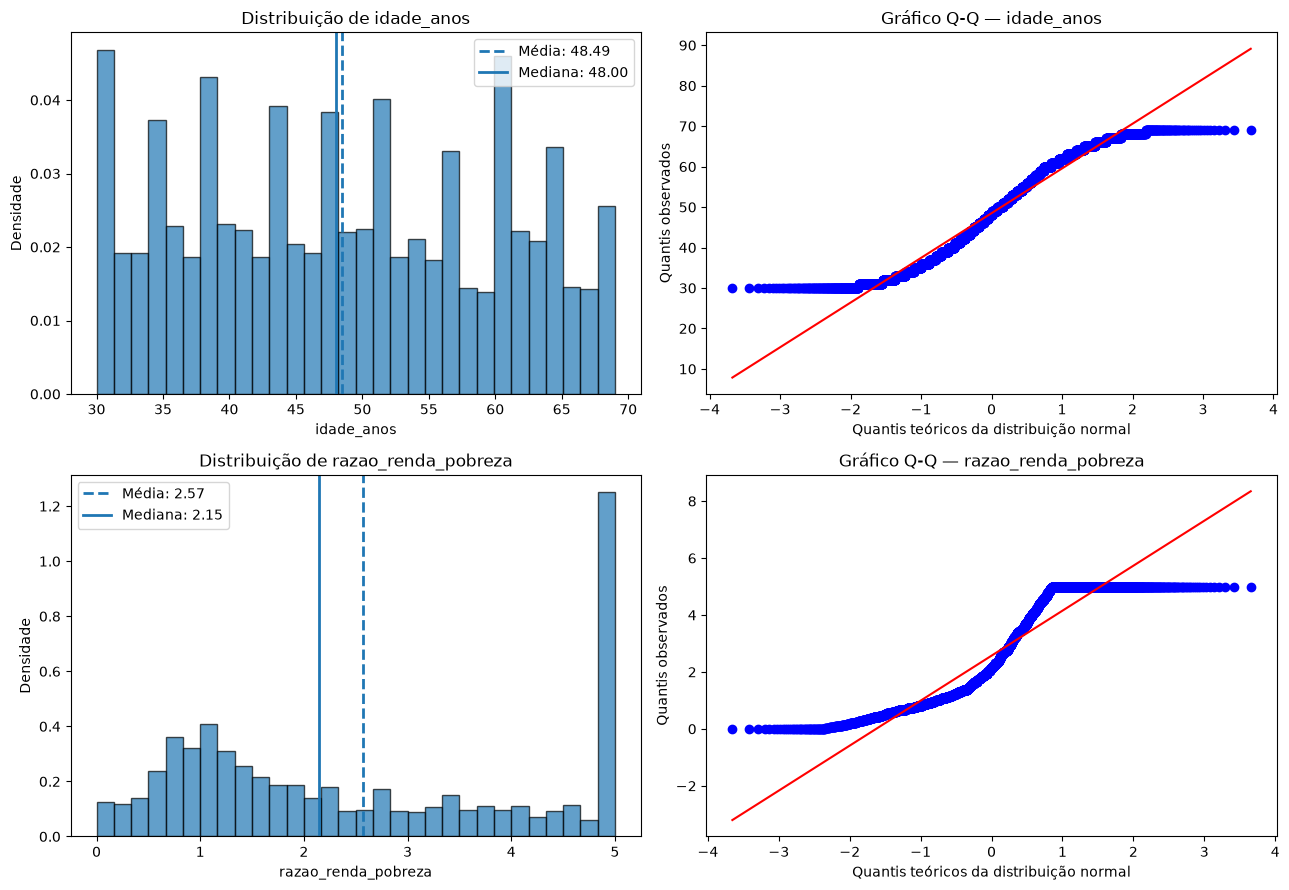

In [20]:
# exploração das estatísticas descritivas das covariáveis numéricas
covariaveis_numericas = [
    "idade_anos",
    "razao_renda_pobreza"
]

resumo_numericas = (
    df_model[covariaveis_numericas]
    .describe()
    .T
)

resumo_numericas["N ausentes"] = (
    df_model[covariaveis_numericas]
    .isna()
    .sum()
)

resumo_numericas["Ausentes (%)"] = (
    100
    * resumo_numericas["N ausentes"]
    / len(df_model)
)

display(resumo_numericas.round(2))
# Criar uma figura com duas linhas e duas colunas.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for i, variavel in enumerate(covariaveis_numericas):

    # Remover valores ausentes apenas para a visualização.
    dados = df_model[variavel].dropna()

    # ------------------------------------------
    # 1. Histograma
    # ------------------------------------------
    ax_hist = axes[i, 0]

    ax_hist.hist(
        dados,
        bins=30,
        density=True,
        edgecolor="black",
        alpha=0.7
    )

    # Marcar média e mediana.
    ax_hist.axvline(
        dados.mean(),
        linestyle="--",
        linewidth=2,
        label=f"Média: {dados.mean():.2f}"
    )

    ax_hist.axvline(
        dados.median(),
        linestyle="-",
        linewidth=2,
        label=f"Mediana: {dados.median():.2f}"
    )

    ax_hist.set_title(f"Distribuição de {variavel}")
    ax_hist.set_xlabel(variavel)
    ax_hist.set_ylabel("Densidade")
    ax_hist.legend()

    # ------------------------------------------
    # 2. Gráfico Q-Q
    # ------------------------------------------
    ax_qq = axes[i, 1]

    stats.probplot(
        dados,
        dist="norm",
        plot=ax_qq
    )

    ax_qq.set_title(f"Gráfico Q-Q — {variavel}")
    ax_qq.set_xlabel("Quantis teóricos da distribuição normal")
    ax_qq.set_ylabel("Quantis observados")

plt.tight_layout()
plt.show()

### 4.3 Distribuição das classes periodontais após a integração

Antes da modelagem, é importante verificar quantos participantes pertencem a cada categoria. A distribuição das quatro categorias de gravidade é mantida apenas como caracterização clínica descritiva; a distribuição binária apresenta os grupos efetivamente utilizados no treinamento e na avaliação dos Modelos A e B.


,Número de participantes
periodontite_classe,
Sem periodontite,2984
Leve,379
Moderada,1804
Grave,709


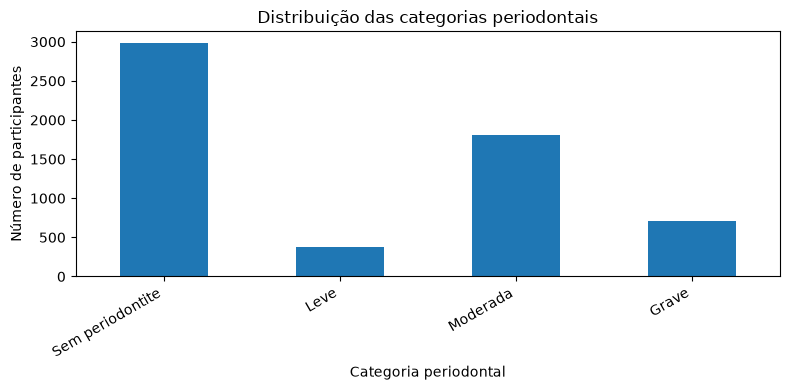

,Número de participantes
periodontite_binaria,
Sem periodontite,2984
Com periodontite,2892


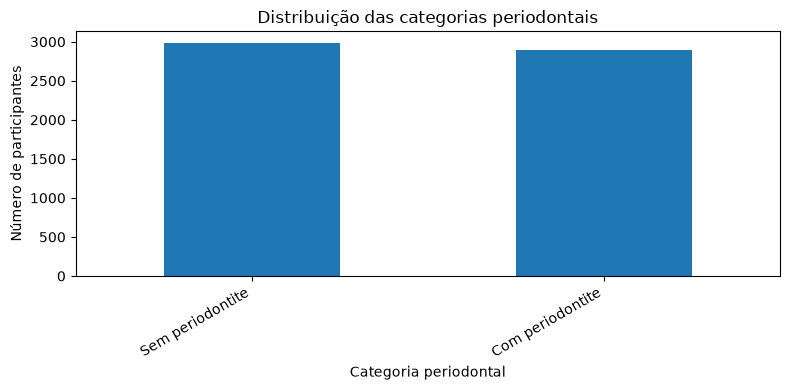

In [21]:
class_order_multi = [
    "Sem periodontite",
    "Leve",
    "Moderada",
    "Grave"
]

class_counts_multi = (
    df_model["periodontite_classe"]
    .value_counts()
    .reindex(class_order_multi, fill_value=0)
)

display(class_counts_multi.rename("Número de participantes").to_frame())

class_counts_multi.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

class_order_bin = [
    "Sem periodontite",
    "Com periodontite"
]

class_counts_bin = (
    df_model["periodontite_binaria"]
    .value_counts()
    .reindex(class_order_bin, fill_value=0)
)

display(class_counts_bin.rename("Número de participantes").to_frame())

class_counts_bin.plot(kind="bar", figsize=(8, 4))
plt.title("Distribuição das categorias periodontais")
plt.xlabel("Categoria periodontal")
plt.ylabel("Número de participantes")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### 4.4 Configuração das covariáveis que serão incluídas no Modelo B


In [22]:
# ============================================================
# Seleção das covariáveis que serão utilizadas no Modelo B
# ============================================================
# True  = incluir a covariável no Modelo B.
# False = excluir a covariável do Modelo B.
# O Modelo A continua utilizando somente os táxons.

CONFIGURACAO_COVARIAVEIS = {
    "idade_anos": True,                  # Idade (anos)
    "sexo": True,                        # Sexo registrado
    "raca_etnia": True,                  # Raça/etnia
    "escolaridade": True,                # Escolaridade
    "estado_civil": True,                # Estado civil
    "razao_renda_pobreza": True,         # Razão renda/pobreza
    "consumo_alcool_categoria": True,    # Categoria de consumo de álcool
    "atividade_fisica_categoria": True,  # Categoria de atividade física
    "hipertensao": True,                 # Hipertensão autorreferida
    "diabetes": True,                    # Diabetes autorreferido
    "doenca_cardiovascular": True,       # Histórico cardiovascular composto
    "historico_cancer": True             # Histórico de câncer
}

# Verificações para evitar erros ao editar a configuração.
if set(CONFIGURACAO_COVARIAVEIS) != set(covariaveis_modelo):
    raise ValueError(
        "As chaves de CONFIGURACAO_COVARIAVEIS devem corresponder "
        "exatamente às covariáveis disponíveis em covariaveis_modelo."
    )

if not all(isinstance(valor, bool) for valor in CONFIGURACAO_COVARIAVEIS.values()):
    raise TypeError("Use somente True ou False na configuração das covariáveis.")

covariaveis_modelo_selecionadas = [
    coluna for coluna in covariaveis_modelo
    if CONFIGURACAO_COVARIAVEIS[coluna]
]

if not covariaveis_modelo_selecionadas:
    raise ValueError(
        "Ative pelo menos uma covariável para executar o Modelo B. "
        "A configuração sem covariáveis corresponde ao Modelo A."
    )

# Separar as covariáveis selecionadas por tipo para o pré-processamento.
COLUNAS_TAXONOMICAS = microbial_cols.copy()
COLUNAS_NUMERICAS_BASE = ["idade_anos", "razao_renda_pobreza"]
COLUNAS_NUMERICAS = [
    coluna for coluna in COLUNAS_NUMERICAS_BASE
    if coluna in covariaveis_modelo_selecionadas
]
COLUNAS_CATEGORICAS = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in COLUNAS_NUMERICAS_BASE
]

rotulos_covariaveis = {
    "idade_anos": "Idade (anos)",
    "sexo": "Sexo",
    "raca_etnia": "Raça/etnia",
    "escolaridade": "Escolaridade",
    "estado_civil": "Estado civil",
    "razao_renda_pobreza": "Razão renda/pobreza",
    "consumo_alcool_categoria": "Consumo de álcool",
    "atividade_fisica_categoria": "Atividade física",
    "hipertensao": "Hipertensão",
    "diabetes": "Diabetes",
    "doenca_cardiovascular": "Doença cardiovascular",
    "historico_cancer": "Histórico de câncer"
}

tabela_configuracao_covariaveis = pd.DataFrame({
    "Covariável": [rotulos_covariaveis[c] for c in covariaveis_modelo],
    "Nome no código": covariaveis_modelo,
    "Incluir no Modelo B": [
        "Sim" if CONFIGURACAO_COVARIAVEIS[c] else "Não"
        for c in covariaveis_modelo
    ]
})

print(
    f"Covariáveis selecionadas para o Modelo B: "
    f"{len(covariaveis_modelo_selecionadas)} de {len(covariaveis_modelo)}"
)
print("Covariáveis numéricas:", COLUNAS_NUMERICAS)
print("Covariáveis categóricas:", COLUNAS_CATEGORICAS)
display(tabela_configuracao_covariaveis)


Covariáveis selecionadas para o Modelo B: 12 de 12
Covariáveis numéricas: ['idade_anos', 'razao_renda_pobreza']
Covariáveis categóricas: ['sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']


,Covariável,Nome no código,Incluir no Modelo B
0,Idade (anos),idade_anos,Sim
1,Sexo,sexo,Sim
2,Raça/etnia,raca_etnia,Sim
3,Escolaridade,escolaridade,Sim
4,Estado civil,estado_civil,Sim
5,Razão renda/pobreza,razao_renda_pobreza,Sim
6,Consumo de álcool,consumo_alcool_categoria,Sim
7,Atividade física,atividade_fisica_categoria,Sim
8,Hipertensão,hipertensao,Sim
9,Diabetes,diabetes,Sim


## 5. Análises exploratórias do microbioma e da integração com covariáveis


### 5.1 PCA exploratória do microbioma após transformação CLR


Participantes utilizados: 5876
Variáveis microbianas inicialmente disponíveis: 107
Valores zero substituídos: 271890
Pseudovalor utilizado: 2.185e-06
Variáveis após remoção das constantes: 107


Variância explicada pela PC1: 10.37%
Variância explicada pela PC2: 9.63%
Variância acumulada: 19.99%


,Táxon,PC1,PC2,Selecionado por
85,Neisseria,0.635,-0.233,PC1
93,Haemophilus,0.608,-0.072,PC1
103,Fretibacterium,-0.601,-0.340,PC1
13,Bacteroidales (ordem),-0.587,-0.255,PC1
33,Lactobacillus,-0.363,0.646,PC2
3,Bifidobacterium,-0.309,0.534,PC2
54,Peptococcus,-0.173,-0.530,PC2
57,Peptostreptococcus,0.164,-0.523,PC2


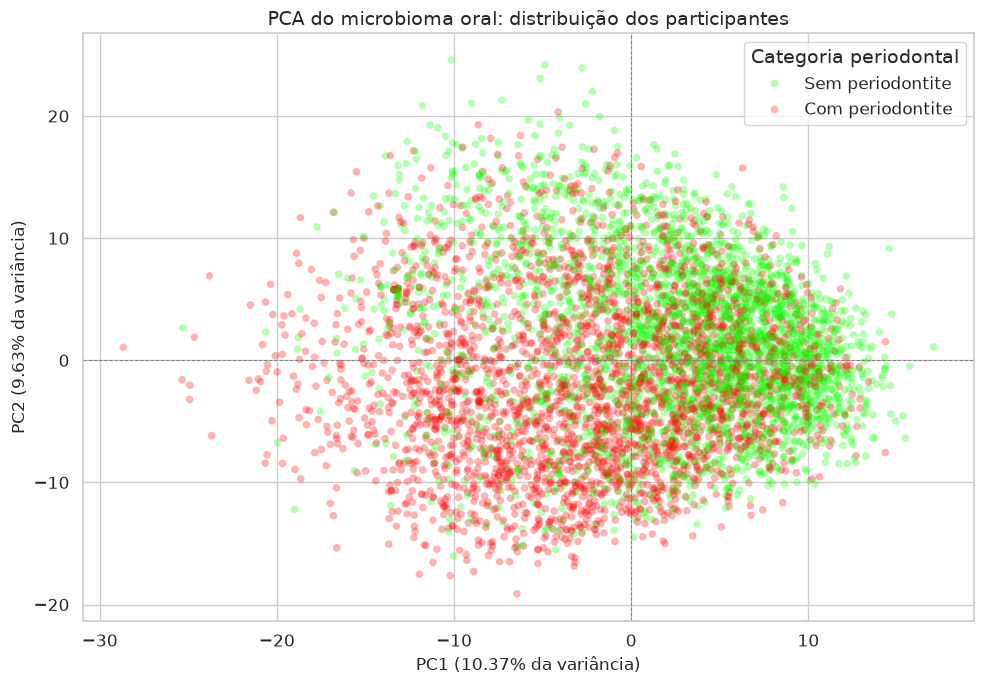

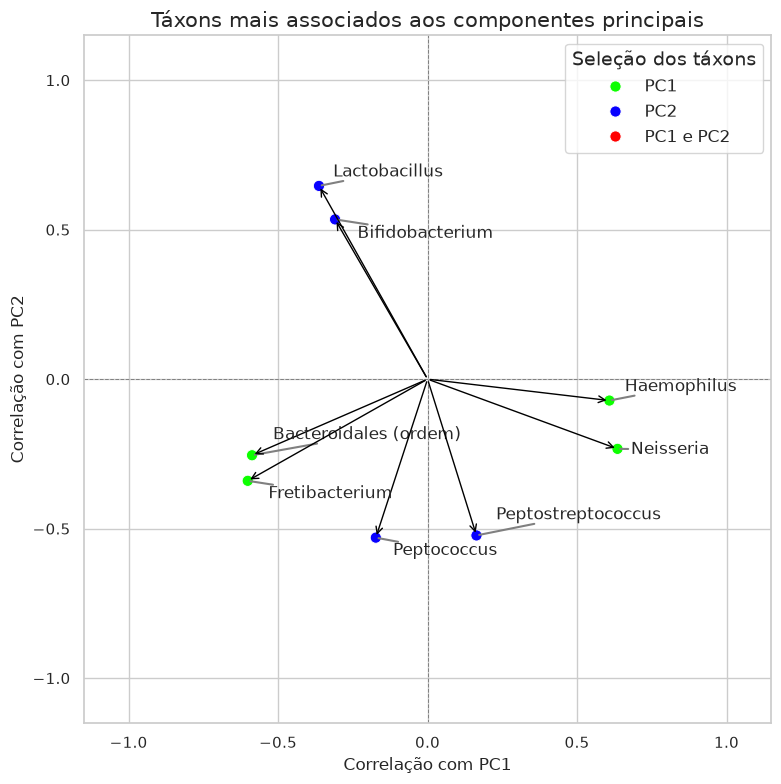


Abundância relativa média dos táxons apresentados como vetores:


,Táxon,PC1,PC2,Selecionado por,Abundância relativa média (%),Ranking de abundância
6,Haemophilus,0.6081,-0.0716,PC1,5.4806,5
5,Neisseria,0.6352,-0.2331,PC1,2.6726,9
2,Lactobacillus,-0.3632,0.6464,PC2,0.5556,17
4,Peptostreptococcus,0.1635,-0.5227,PC2,0.3361,27
0,Bifidobacterium,-0.3094,0.5343,PC2,0.0890,56
3,Peptococcus,-0.1731,-0.5301,PC2,0.0661,64
7,Fretibacterium,-0.6015,-0.3400,PC1,0.0615,67
1,Bacteroidales (ordem),-0.5872,-0.2545,PC1,0.0283,82



15 táxons com maior abundância relativa média:


,Táxon,Abundância relativa média (%),Ranking de abundância
34,Streptococcus,32.2861,1
7,Rothia,11.8711,2
22,Prevotella 7,8.0100,3
70,Veillonella,6.0050,4
93,Haemophilus,5.4806,5
30,Gemella,4.5270,6
71,Fusobacterium,2.7436,7
0,Actinomyces,2.6750,8
85,Neisseria,2.6726,9
19,Prevotella,2.4007,10


Associação de Spearman entre abundância relativa média e maior correlação absoluta com PC1/PC2: rho = 0.082; p = 0.403


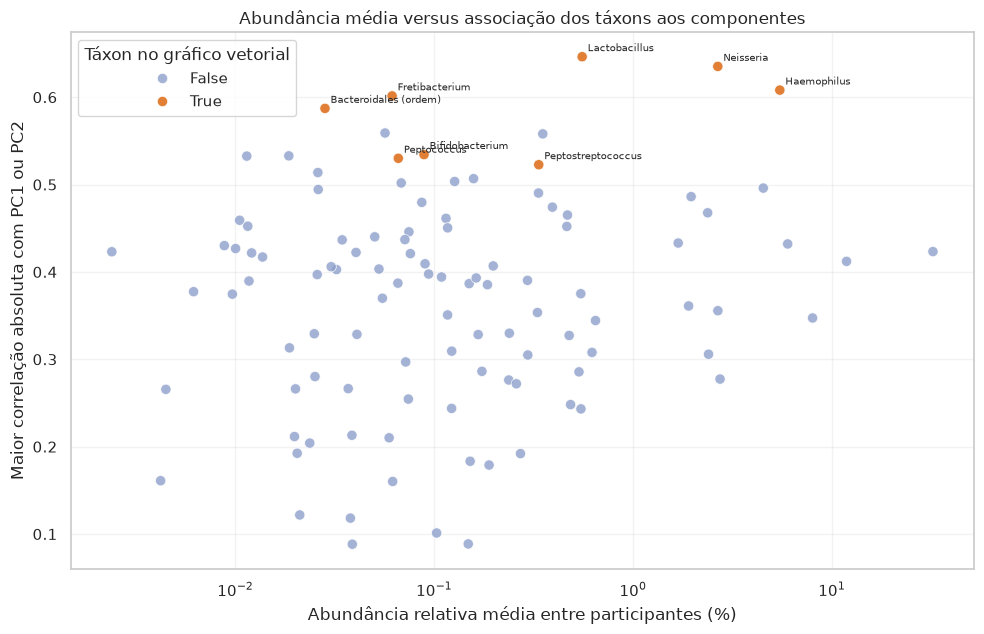

In [23]:
# --------------------------------------------------
# 1. Preparar as categorias periodontais binárias
# --------------------------------------------------

classes_binarias = class_order_bin.copy()

df_pca = df_model.copy()

df_pca["Classe_binaria"] = (
    df_pca["periodontite_binaria"]
    .astype("string")
    .str.strip()
)
df_pca["Classe_multiclasse"] = (
    df_pca["periodontite_classe"]
    .astype("string")
    .str.strip()
)

df_pca = df_pca[
    df_pca["Classe_binaria"].isin(classes_binarias)
    & df_pca["Classe_multiclasse"].isin(class_order_multi)
].copy()

# Extrair as variáveis microbianas
X_df = df_pca[microbial_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

X_original = X_df.to_numpy(dtype=float)

# Remover linhas com valores inválidos ou soma zero
linhas_validas = (
    np.isfinite(X_original).all(axis=1)
    & (X_original >= 0).all(axis=1)
    & (X_original.sum(axis=1) > 0)
)

X_original = X_original[linhas_validas]
df_pca = df_pca.iloc[np.flatnonzero(linhas_validas)].copy()

print("Participantes utilizados:", len(df_pca))
print("Variáveis microbianas inicialmente disponíveis:", X_original.shape[1])

if len(df_pca) < 3:
    raise ValueError("Participantes insuficientes para realizar a PCA.")

if df_pca["Classe_binaria"].nunique() < 2:
    raise ValueError("É necessário haver participantes das duas classes.")

# --------------------------------------------------
# 2. Preparar abundâncias relativas e tratar os zeros
# --------------------------------------------------

# Garantir que as abundâncias de cada participante somem 1
X_rel = X_original / X_original.sum(axis=1, keepdims=True)

# Usar metade da menor abundância positiva como pseudovalor
valores_positivos = X_rel[X_rel > 0]

if len(valores_positivos) == 0:
    raise ValueError("Não foram encontradas abundâncias positivas.")

pseudovalor = valores_positivos.min() / 2
quantidade_zeros = np.count_nonzero(X_rel == 0)

X_rel[X_rel == 0] = pseudovalor

# Reajustar as abundâncias após a substituição dos zeros
X_rel = X_rel / X_rel.sum(axis=1, keepdims=True)

print("Valores zero substituídos:", quantidade_zeros)
print("Pseudovalor utilizado:", f"{pseudovalor:.3e}")

# --------------------------------------------------
# 3. Aplicar a transformação CLR
# --------------------------------------------------

log_rel = np.log(X_rel)

# CLR: log(abundância) menos a média dos logaritmos por participante
X_clr = log_rel - log_rel.mean(axis=1, keepdims=True)

# Remover variáveis microbianas sem variação
desvio_padrao = X_clr.std(axis=0, ddof=1)
colunas_variaveis = desvio_padrao > 1e-12

X_clr = X_clr[:, colunas_variaveis]
generos_clr = np.asarray(microbial_cols)[colunas_variaveis]

print("Variáveis após remoção das constantes:", len(generos_clr))

# --------------------------------------------------
# 4. Calcular os dois primeiros componentes principais
# --------------------------------------------------

pca = PCA(
    n_components=2,
    svd_solver="randomized",
    random_state=42
)

coordenadas = pca.fit_transform(X_clr)

variancia_pc1 = pca.explained_variance_ratio_[0] * 100
variancia_pc2 = pca.explained_variance_ratio_[1] * 100

print(f"Variância explicada pela PC1: {variancia_pc1:.2f}%")
print(f"Variância explicada pela PC2: {variancia_pc2:.2f}%")
print(
    f"Variância acumulada: "
    f"{variancia_pc1 + variancia_pc2:.2f}%"
)

df_scores = pd.DataFrame(
    coordenadas,
    columns=["PC1", "PC2"],
    index=df_pca.index
)

df_scores["Classe_binaria"] = (
    df_pca["Classe_binaria"].to_numpy()
)
df_scores["Classe_multiclasse"] = (
    df_pca["Classe_multiclasse"].to_numpy()
)

# --------------------------------------------------
# 5. Calcular a correlação das variáveis taxonômicas com PC1 e PC2
# --------------------------------------------------

X_centralizado = X_clr - X_clr.mean(axis=0)
scores_centralizados = coordenadas - coordenadas.mean(axis=0)

covariancias = (
    X_centralizado.T @ scores_centralizados
) / (len(X_clr) - 1)

desvio_generos = X_centralizado.std(axis=0, ddof=1)
desvio_scores = scores_centralizados.std(axis=0, ddof=1)

correlacoes = covariancias / (
    desvio_generos[:, None] * desvio_scores[None, :]
)

correlacoes = np.clip(correlacoes, -1, 1)

df_correlacoes = pd.DataFrame({
    "Codigo": generos_clr,
    "PC1": correlacoes[:, 0],
    "PC2": correlacoes[:, 1]
})

# Selecionar os 4 táxons com maior correlação absoluta
# com cada componente. Um táxon pode aparecer nos dois grupos.
n_por_componente = min(4, len(df_correlacoes))

top_pc1 = (
    df_correlacoes
    .assign(Abs_PC1=lambda d: d["PC1"].abs())
    .nlargest(n_por_componente, "Abs_PC1")
)

top_pc2 = (
    df_correlacoes
    .assign(Abs_PC2=lambda d: d["PC2"].abs())
    .nlargest(n_por_componente, "Abs_PC2")
)

codigos_pc1 = set(top_pc1["Codigo"])
codigos_pc2 = set(top_pc2["Codigo"])

# Combinar os resultados sem duplicar táxons
codigos_selecionados = list(
    dict.fromkeys(
        top_pc1["Codigo"].tolist()
        + top_pc2["Codigo"].tolist()
    )
)

df_taxa = df_correlacoes[
    df_correlacoes["Codigo"].isin(codigos_selecionados)
].copy()

df_taxa["Selecionado por"] = df_taxa["Codigo"].apply(
    lambda codigo: (
        "PC1 e PC2"
        if codigo in codigos_pc1 and codigo in codigos_pc2
        else "PC1"
        if codigo in codigos_pc1
        else "PC2"
    )
)

# --------------------------------------------------
# 6. Recuperar nomes pela função de anotação definida na seção 2.2
# --------------------------------------------------

df_taxa["Rótulo"] = rotular_taxons(df_taxa["Codigo"].tolist())

display(
    df_taxa[
        ["Rótulo", "PC1", "PC2", "Selecionado por"]
    ]
    .rename(columns={"Rótulo": "Táxon"})
    .sort_values("PC1", key=lambda s: s.abs(), ascending=False)
    .round(3)
)

# --------------------------------------------------
# 7. Gráfico 1: distribuição dos participantes
# --------------------------------------------------

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=df_scores,
    x="PC1",
    y="PC2",
    hue="Classe_binaria",
    hue_order=classes_binarias,
    palette={
        "Sem periodontite": "#0dff00",
        "Com periodontite": "#ff0000"
    },
    s=30,
    alpha=0.30,
    linewidth=0,
    ax=ax
)

ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

ax.set_xlabel(f"PC1 ({variancia_pc1:.2f}% da variância)", fontsize=12)
ax.set_ylabel(f"PC2 ({variancia_pc2:.2f}% da variância)", fontsize=12)
ax.set_title("PCA do microbioma oral: distribuição dos participantes", fontsize=14)

ax.tick_params(axis="both", labelsize=12)

ax.legend(
    title="Categoria periodontal",
    loc="best",
    fontsize=12,
    title_fontsize=14
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Gráfico 2: os mesmos participantes coloridos pelas quatro categorias
# --------------------------------------------------

# fig, ax = plt.subplots(figsize=(10, 7))

# sns.scatterplot(
#     data=df_scores,
#     x="PC1",
#     y="PC2",
#     hue="Classe_multiclasse",
#     hue_order=[c for c in class_order_multi if c in df_scores["Classe_multiclasse"].unique()],
#     s=30,
#     alpha=0.35,
#     linewidth=0,
#     ax=ax
# )

# ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
# ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
# ax.set_xlabel(f"PC1 ({variancia_pc1:.2f}% da variância)", fontsize=12)
# ax.set_ylabel(f"PC2 ({variancia_pc2:.2f}% da variância)", fontsize=12)
# ax.set_title("PCA do microbioma oral: quatro categorias periodontais", fontsize=14)
# ax.legend(title="Categoria periodontal", loc="best", fontsize=11)
# fig.tight_layout()
# plt.show()

# --------------------------------------------------
# 9. Gráfico 3: táxons associados aos componentes
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

sns.scatterplot(
    data=df_taxa,
    x="PC1",
    y="PC2",
    hue="Selecionado por",
    hue_order=["PC1", "PC2", "PC1 e PC2"],
    palette={
        "PC1": "#0dff00",
        "PC2": "#0800ff",
        "PC1 e PC2": "#ff0000"
    },
    s=65,
    ax=ax
)

# Desenhar os vetores e criar os rótulos que serão reposicionados
textos = []

for _, linha in df_taxa.iterrows():
    x = float(linha["PC1"])
    y = float(linha["PC2"])
    rotulo = str(linha["Rótulo"])

    # Desenhar o vetor do táxon a partir da origem
    ax.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops={
            "arrowstyle": "->",
            "color": "#000000",
            "linewidth": 1,
            "alpha": 1
        }
    )

    # Criar apenas um rótulo por táxon. Sem adjustText, aplicar deslocamentos
    # fixos em pontos para reduzir sobreposições, inclusive em coordenadas idênticas.
    if adjust_text is not None:
        texto = ax.text(x, y, rotulo, fontsize=12)
        textos.append(texto)
    else:
        deslocamentos = [(8, 8), (8, -10), (-8, 12), (10, 14), (10, -14), (-10, -12)]
        dx, dy = deslocamentos[len(textos) % len(deslocamentos)]
        ax.annotate(
            rotulo,
            xy=(x, y),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=12,
            ha="left" if dx >= 0 else "right",
            va="center",
            arrowprops={"arrowstyle": "-", "color": "gray", "linewidth": 0.8, "alpha": 0.8}
        )
        textos.append(rotulo)

ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("Correlação com PC1")
ax.set_ylabel("Correlação com PC2")
ax.set_title("Táxons mais associados aos componentes principais", fontsize=15)

ax.legend(
    title="Seleção dos táxons",
    loc="best",
    fontsize=12,
    title_fontsize=14
)

# Reposicionar os rótulos para reduzir sobreposições, quando disponível.
if adjust_text is not None:
    adjust_text(
        textos,
        x=df_taxa["PC1"].to_numpy(),
        y=df_taxa["PC2"].to_numpy(),
        target_x=df_taxa["PC1"].to_numpy(),
        target_y=df_taxa["PC2"].to_numpy(),
        ax=ax,
        force_text=(0.5, 0.8),
        force_static=(0.3, 0.5),
        expand=(1.2, 1.4),
        ensure_inside_axes=True,
        iter_lim=300,
        arrowprops={
            "arrowstyle": "-",
            "color": "gray",
            "linewidth": 1.5,
            "alpha": 1
        }
    )
else:
    print(
        "A biblioteca opcional 'adjustText' não está instalada. "
        "Foram aplicados deslocamentos fixos aos rótulos para reduzir sobreposições. "
        "Para reposicionamento automático, instale com: pip install adjustText."
    )

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 10. Verificar se os táxons vetoriais também estão entre os mais abundantes
# --------------------------------------------------

# Recuperar as abundâncias relativas observadas ANTES da substituição dos zeros.
# Assim, a média inclui zeros reais de não detecção e não incorpora o pseudovalor.
X_rel_observada = X_original / X_original.sum(axis=1, keepdims=True)
media_abundancia_taxons = X_rel_observada.mean(axis=0)

df_abundancia_taxons = pd.DataFrame({
    "Codigo": microbial_cols,
    "Abundância relativa média (%)": media_abundancia_taxons * 100
})
df_abundancia_taxons["Ranking de abundância"] = (
    df_abundancia_taxons["Abundância relativa média (%)"]
    .rank(method="min", ascending=False)
    .astype(int)
)
# Associar a abundância média aos coeficientes dos táxons usados no gráfico vetorial.
df_correlacoes_abundancia = df_correlacoes.merge(
    df_abundancia_taxons,
    on="Codigo",
    how="left",
    validate="one_to_one"
)
df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"] = (
    df_correlacoes_abundancia[["PC1", "PC2"]].abs().max(axis=1)
)
df_correlacoes_abundancia["Ranking de associação com PC1/PC2"] = (
    df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Tabela específica dos táxons apresentados como vetores no gráfico.
df_taxa_abundancia = df_taxa.merge(
    df_abundancia_taxons,
    on="Codigo",
    how="left",
    validate="one_to_one"
)
print("\nAbundância relativa média dos táxons apresentados como vetores:")
display(
    df_taxa_abundancia[[
        "Rótulo", "PC1", "PC2", "Selecionado por",
        "Abundância relativa média (%)", "Ranking de abundância"
    ]]
    .rename(columns={"Rótulo": "Táxon"})
    .sort_values("Ranking de abundância")
    .round(4)
)

print("\n15 táxons com maior abundância relativa média:")
df_top_abundantes = df_abundancia_taxons.nlargest(
    15, "Abundância relativa média (%)"
).copy()
df_top_abundantes["Táxon"] = rotular_taxons(df_top_abundantes["Codigo"].tolist())
display(
    df_top_abundantes[[
        "Táxon", "Abundância relativa média (%)", "Ranking de abundância"
    ]].round(4)
)

# Avaliar, de forma exploratória, se abundância média e associação com os PCs
# apresentam uma relação monotônica entre todos os táxons com variância no CLR.
if (
    len(df_correlacoes_abundancia) >= 3
    and df_correlacoes_abundancia["Abundância relativa média (%)"].nunique() > 1
    and df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"].nunique() > 1
):
    rho_abundancia_pca, p_abundancia_pca = stats.spearmanr(
        df_correlacoes_abundancia["Abundância relativa média (%)"],
        df_correlacoes_abundancia["Maior |correlação| com PC1/PC2"]
    )
    print(
        "Associação de Spearman entre abundância relativa média e maior "
        "correlação absoluta com PC1/PC2: "
        f"rho = {rho_abundancia_pca:.3f}; p = {p_abundancia_pca:.3g}"
    )
else:
    rho_abundancia_pca = np.nan
    p_abundancia_pca = np.nan
    print("Não foi possível calcular a associação de Spearman entre abundância e associação aos PCs.")

# Dispersão de todos os táxons; destaque para os táxons exibidos como vetores.
codigos_vetoriais = set(df_taxa["Codigo"])
df_correlacoes_abundancia["Exibido como vetor"] = (
    df_correlacoes_abundancia["Codigo"].isin(codigos_vetoriais)
)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(
    data=df_correlacoes_abundancia,
    x="Abundância relativa média (%)",
    y="Maior |correlação| com PC1/PC2",
    hue="Exibido como vetor",
    palette={True: "#d95f02", False: "#8da0cb"},
    alpha=0.8,
    s=55,
    ax=ax
)

for _, linha in df_taxa_abundancia.iterrows():
    ax.annotate(
        linha["Rótulo"],
        (
            linha["Abundância relativa média (%)"],
            max(abs(linha["PC1"]), abs(linha["PC2"]))
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7
    )

if (df_correlacoes_abundancia["Abundância relativa média (%)"] > 0).all():
    ax.set_xscale("log")
ax.set_xlabel("Abundância relativa média entre participantes (%)")
ax.set_ylabel("Maior correlação absoluta com PC1 ou PC2")
ax.set_title("Abundância média versus associação dos táxons aos componentes")
ax.grid(alpha=0.25)
ax.legend(title="Táxon no gráfico vetorial")
fig.tight_layout()
plt.show()


### 5.2 PCA integrada: microbioma + covariáveis selecionadas



Participantes na PCA integrada: 5876
Covariáveis selecionadas na configuração 4.4: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Covariáveis efetivamente utilizadas: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Atributos após imputação/codificação: 37
Contribuição do bloco microbioma: 50.0%
Contribuição do bloco covariáveis: 50.0%


Variância explicada pela PC1 integrada: 6.04%
Variância explicada pela PC2 integrada: 5.85%
Variância acumulada integrada: 11.88%


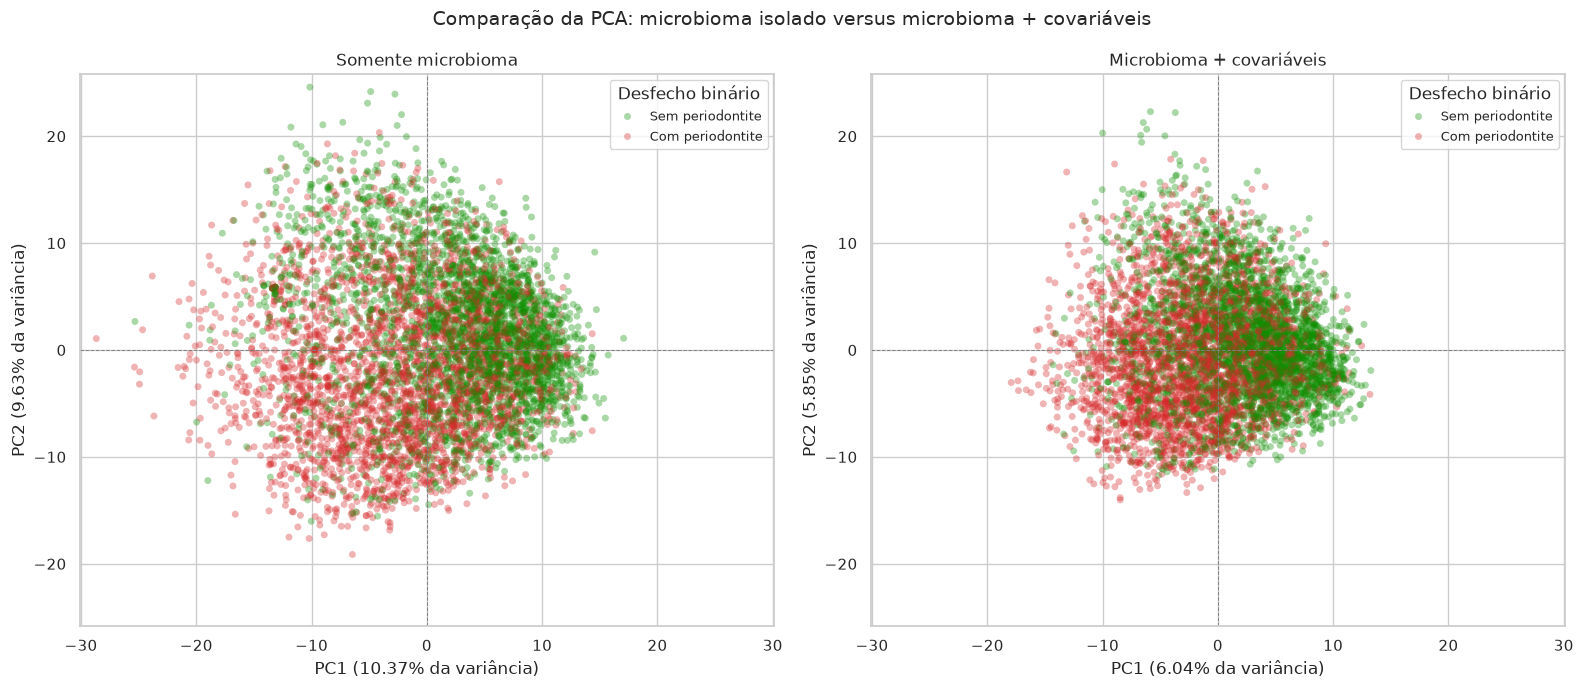

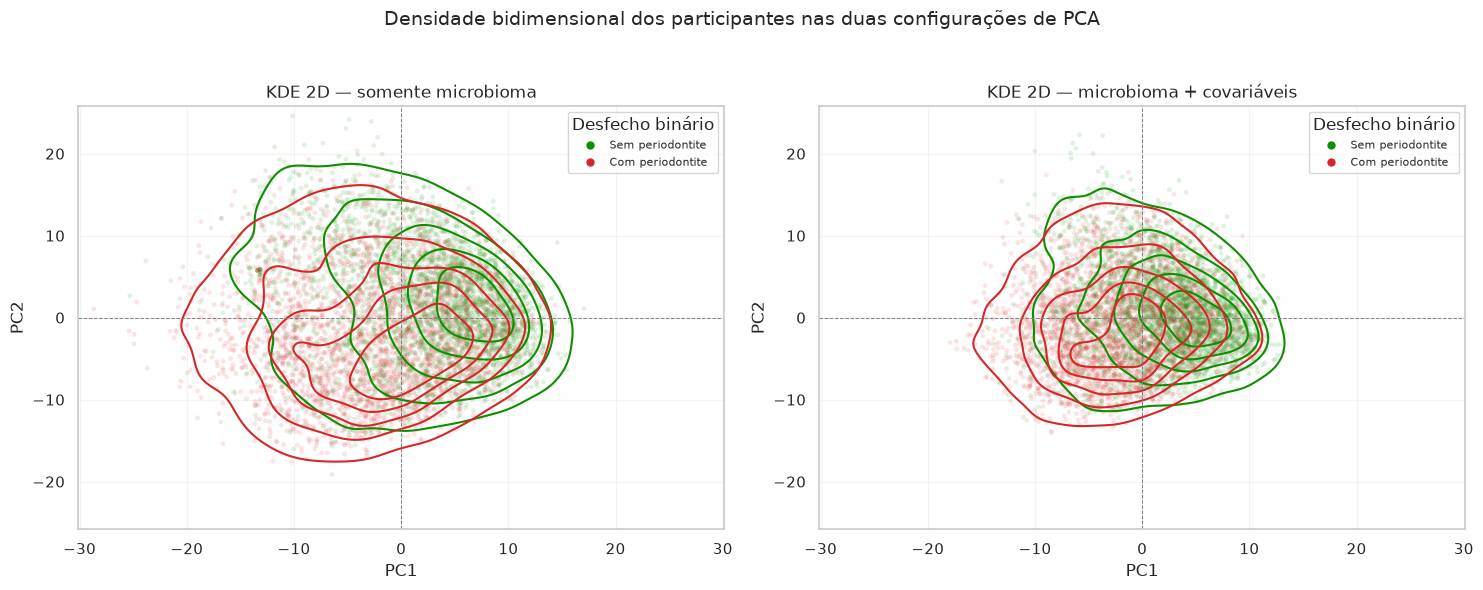


Dispersão de cada categoria no plano dos dois primeiros componentes:


,PCA,Desfecho,Categoria,n,Distância média ao centróide (PC1-PC2),Mediana da distância ao centróide
0,Somente microbioma,Binário,Sem periodontite,2984,8.3498,7.8172
1,Somente microbioma,Binário,Com periodontite,2892,9.0948,8.9497
2,Microbioma + covariáveis,Binário,Sem periodontite,2984,6.4088,6.0257
3,Microbioma + covariáveis,Binário,Com periodontite,2892,6.9498,6.7438



Comparação da dispersão média entre as duas configurações de PCA:


PCA,Desfecho,Categoria,Microbioma + covariáveis,Somente microbioma,Variação relativa da dispersão (%)
0,Binário,Com periodontite,6.950,9.095,-23.585
1,Binário,Sem periodontite,6.409,8.350,-23.246



Atributos de covariáveis mais correlacionados com os componentes da PCA integrada:


,Atributo de covariável,Correlação com PC1,Correlação com PC2,Maior correlação absoluta
0,razao_renda_pobreza,0.461,0.020,0.461
1,hipertensao_Não,0.124,-0.461,0.461
2,hipertensao_Sim,-0.124,0.461,0.461
3,idade_anos,0.022,0.458,0.458
4,escolaridade_Graduação ou superior,0.451,-0.079,0.451
5,doenca_cardiovascular_Sim,-0.146,0.392,0.392
6,doenca_cardiovascular_Não,0.146,-0.392,0.392
7,estado_civil_Casado,0.341,-0.083,0.341
8,diabetes_Não,0.083,-0.327,0.327
9,historico_cancer_Sim,0.060,0.310,0.310


In [24]:
# ============================================================
# PCA integrada: matriz CLR + covariáveis selecionadas
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------
# 1. Preparar as covariáveis selecionadas
# --------------------------------------------------

covariaveis_ausentes_df = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in df_pca.columns
]
if covariaveis_ausentes_df:
    raise KeyError(
        "Covariáveis selecionadas não encontradas em df_pca: "
        f"{covariaveis_ausentes_df}"
    )

# Manter a mesma amostra utilizada na PCA de referência.
X_covariaveis_pca = df_pca[covariaveis_modelo_selecionadas].copy()

# Variáveis numéricas e categóricas seguem a mesma classificação definida
# na configuração 4.4, mas o pré-processamento abaixo é específico da PCA.
colunas_numericas_pca = [
    coluna for coluna in COLUNAS_NUMERICAS
    if coluna in covariaveis_modelo_selecionadas
]
colunas_categoricas_pca = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in colunas_numericas_pca
]

for coluna in colunas_numericas_pca:
    X_covariaveis_pca[coluna] = pd.to_numeric(
        X_covariaveis_pca[coluna], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

for coluna in colunas_categoricas_pca:
    # Converte níveis categóricos para texto e preserva ausências como NaN.
    X_covariaveis_pca[coluna] = X_covariaveis_pca[coluna].map(
        lambda valor: str(valor) if pd.notna(valor) else np.nan
    )

# Covariáveis inteiramente ausentes não podem ser imputadas de forma útil.
covariaveis_sem_observacoes = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if X_covariaveis_pca[coluna].notna().sum() == 0
]
if covariaveis_sem_observacoes:
    print(
        "Covariáveis excluídas da PCA integrada por estarem totalmente ausentes:",
        covariaveis_sem_observacoes
    )

covariaveis_pca_utilizadas = [
    coluna for coluna in covariaveis_modelo_selecionadas
    if coluna not in covariaveis_sem_observacoes
]
if not covariaveis_pca_utilizadas:
    raise ValueError(
        "Nenhuma covariável selecionada possui observações disponíveis para a PCA."
    )

colunas_numericas_pca = [
    coluna for coluna in colunas_numericas_pca
    if coluna in covariaveis_pca_utilizadas
]
colunas_categoricas_pca = [
    coluna for coluna in colunas_categoricas_pca
    if coluna in covariaveis_pca_utilizadas
]

transformadores_covariaveis_pca = []

if colunas_numericas_pca:
    pipeline_numerico_pca = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler())
    ])
    transformadores_covariaveis_pca.append((
        "numericas", pipeline_numerico_pca, colunas_numericas_pca
    ))

if colunas_categoricas_pca:
    # Compatibilidade com versões do scikit-learn que usam 'sparse' em vez
    # de 'sparse_output'.
    try:
        codificador_pca = OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        )
    except TypeError:
        codificador_pca = OneHotEncoder(
            handle_unknown="ignore", sparse=False
        )

    pipeline_categorico_pca = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="most_frequent")),
        ("onehot", codificador_pca),
        ("padronizacao", StandardScaler())
    ])
    transformadores_covariaveis_pca.append((
        "categoricas", pipeline_categorico_pca, colunas_categoricas_pca
    ))

preprocessador_covariaveis_pca = ColumnTransformer(
    transformers=transformadores_covariaveis_pca,
    remainder="drop",
    verbose_feature_names_out=False
)

X_covariaveis_codificadas = preprocessador_covariaveis_pca.fit_transform(
    X_covariaveis_pca[covariaveis_pca_utilizadas]
)
X_covariaveis_codificadas = np.asarray(
    X_covariaveis_codificadas, dtype=float
)
nomes_covariaveis_codificadas = np.asarray(
    preprocessador_covariaveis_pca.get_feature_names_out(), dtype=object
)

# Remover indicadores constantes (por exemplo, níveis categóricos ausentes
# ou covariáveis sem variação na amostra efetivamente analisada).
desvios_covariaveis_pca = X_covariaveis_codificadas.std(axis=0, ddof=1)
colunas_covariaveis_variaveis = desvios_covariaveis_pca > 1e-12
X_covariaveis_codificadas = X_covariaveis_codificadas[
    :, colunas_covariaveis_variaveis
]
nomes_covariaveis_codificadas = nomes_covariaveis_codificadas[
    colunas_covariaveis_variaveis
]

if X_covariaveis_codificadas.shape[1] == 0:
    raise ValueError(
        "As covariáveis selecionadas não produziram atributos variáveis após "
        "imputação e codificação. Verifique a configuração 4.4."
    )

if X_covariaveis_codificadas.shape[0] != X_clr.shape[0]:
    raise ValueError(
        "A matriz de covariáveis e a matriz CLR não possuem o mesmo número de participantes."
    )

print("Participantes na PCA integrada:", len(df_pca))
print("Covariáveis selecionadas na configuração 4.4:", covariaveis_modelo_selecionadas)
print("Covariáveis efetivamente utilizadas:", covariaveis_pca_utilizadas)
print("Atributos após imputação/codificação:", X_covariaveis_codificadas.shape[1])

# --------------------------------------------------
# 2. Igualar a contribuição total dos dois blocos
# --------------------------------------------------

# Centralizar os blocos antes de calcular a contribuição total.
X_clr_centralizado = X_clr - X_clr.mean(axis=0, keepdims=True)
X_covariaveis_centralizadas = (
    X_covariaveis_codificadas
    - X_covariaveis_codificadas.mean(axis=0, keepdims=True)
)

soma_quadrados_microbioma = float(np.square(X_clr_centralizado).sum())
soma_quadrados_covariaveis = float(
    np.square(X_covariaveis_centralizadas).sum()
)

if soma_quadrados_microbioma <= 0 or soma_quadrados_covariaveis <= 0:
    raise ValueError(
        "Não foi possível ponderar os blocos: um deles não apresenta variância."
    )

# Cada bloco passa a responder por metade da variância total da matriz integrada.
peso_microbioma = 1 / np.sqrt(2)
peso_covariaveis = np.sqrt(
    soma_quadrados_microbioma / (2 * soma_quadrados_covariaveis)
)

X_clr_ponderado = X_clr_centralizado * peso_microbioma
X_covariaveis_ponderadas = (
    X_covariaveis_centralizadas * peso_covariaveis
)

X_pca_integrada = np.column_stack([
    X_clr_ponderado,
    X_covariaveis_ponderadas
])

print(
    "Contribuição do bloco microbioma:",
    f"{np.square(X_clr_ponderado).sum() / np.square(X_pca_integrada).sum():.1%}"
)
print(
    "Contribuição do bloco covariáveis:",
    f"{np.square(X_covariaveis_ponderadas).sum() / np.square(X_pca_integrada).sum():.1%}"
)

# --------------------------------------------------
# 3. Ajustar a PCA integrada
# --------------------------------------------------

pca_integrada = PCA(
    n_components=2,
    svd_solver="randomized",
    random_state=42
)
coordenadas_integradas = pca_integrada.fit_transform(X_pca_integrada)

variancia_pc1_integrada = pca_integrada.explained_variance_ratio_[0] * 100
variancia_pc2_integrada = pca_integrada.explained_variance_ratio_[1] * 100
variancia_acumulada_integrada = (
    variancia_pc1_integrada + variancia_pc2_integrada
)

print(f"Variância explicada pela PC1 integrada: {variancia_pc1_integrada:.2f}%")
print(f"Variância explicada pela PC2 integrada: {variancia_pc2_integrada:.2f}%")
print(f"Variância acumulada integrada: {variancia_acumulada_integrada:.2f}%")

# Manter os mesmos participantes e os mesmos rótulos da PCA de referência.
df_scores_integrada = pd.DataFrame(
    coordenadas_integradas,
    columns=["PC1", "PC2"],
    index=df_pca.index
)
df_scores_integrada["Classe_binaria"] = df_pca["Classe_binaria"].to_numpy()
df_scores_integrada["Classe_multiclasse"] = df_pca["Classe_multiclasse"].to_numpy()

# --------------------------------------------------
# 4. Comparar graficamente a PCA de referência e a PCA integrada
#    (somente desfecho binário)
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.set_theme(style="whitegrid")

cores_binarias_pca = {
    "Sem periodontite": "#0d8f00",
    "Com periodontite": "#d62728"
}

configuracoes_graficos_pca = [
    (
        df_scores,
        "Somente microbioma",
        variancia_pc1,
        variancia_pc2
    ),
    (
        df_scores_integrada,
        "Microbioma + covariáveis",
        variancia_pc1_integrada,
        variancia_pc2_integrada
    )
]

for ax, (dados, titulo, var1, var2) in zip(
    axes, configuracoes_graficos_pca
):

    sns.scatterplot(
        data=dados,
        x="PC1",
        y="PC2",
        hue="Classe_binaria",
        hue_order=classes_binarias,
        palette=cores_binarias_pca,
        s=25,
        alpha=0.35,
        linewidth=0,
        ax=ax
    )

    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")

    ax.set_title(titulo, fontsize=12)
    ax.set_xlabel(f"PC1 ({var1:.2f}% da variância)")
    ax.set_ylabel(f"PC2 ({var2:.2f}% da variância)")
    ax.legend(title="Desfecho binário", fontsize=9)

# Utilizar os mesmos limites nos dois painéis
coordenadas_para_limites = np.vstack([
    df_scores[["PC1", "PC2"]].to_numpy(),
    df_scores_integrada[["PC1", "PC2"]].to_numpy()
])

limite_x = np.max(np.abs(coordenadas_para_limites[:, 0])) * 1.05
limite_y = np.max(np.abs(coordenadas_para_limites[:, 1])) * 1.05

for ax in axes:
    ax.set_xlim(-limite_x, limite_x)
    ax.set_ylim(-limite_y, limite_y)

fig.suptitle(
    "Comparação da PCA: microbioma isolado versus microbioma + covariáveis",
    fontsize=14
)

fig.tight_layout()
plt.show()

# --------------------------------------------------
# 4.1 KDE bidimensional: densidade dos participantes por desfecho binário
# --------------------------------------------------

# Os contornos KDE mostram regiões de maior concentração dos participantes.
# A análise é feita para a PCA de referência e para a PCA integrada.
def adicionar_contornos_kde_2d(ax, dados, titulo, paleta, limite_x, limite_y):
    sns.scatterplot(
        data=dados,
        x="PC1",
        y="PC2",
        hue="Classe_binaria",
        hue_order=classes_binarias,
        palette=paleta,
        s=12,
        alpha=0.12,
        linewidth=0,
        legend=False,
        ax=ax
    )

    curvas_adicionadas = 0
    for classe in classes_binarias:
        grupo = dados.loc[dados["Classe_binaria"].eq(classe), ["PC1", "PC2"]].dropna()
        pontos = grupo.to_numpy(dtype=float)

        # KDE bivariada requer número suficiente de observações e variação em
        # duas dimensões; grupos degenerados são ignorados com aviso explícito.
        if len(pontos) < 5 or np.linalg.matrix_rank(np.cov(pontos, rowvar=False)) < 2:
            print(f"KDE não calculada para '{classe}' em '{titulo}': dados insuficientes ou degenerados.")
            continue

        try:
            sns.kdeplot(
                x=grupo["PC1"],
                y=grupo["PC2"],
                levels=6,
                thresh=0.05,
                fill=False,
                color=paleta[classe],
                linewidths=1.5,
                ax=ax
            )
            curvas_adicionadas += 1
        except (ValueError, np.linalg.LinAlgError) as erro:
            print(f"KDE não calculada para '{classe}' em '{titulo}': {erro}")

    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.set_xlim(-limite_x, limite_x)
    ax.set_ylim(-limite_y, limite_y)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(titulo)
    ax.grid(alpha=0.2)

    # Legenda manual para não duplicar entradas dos contornos.
    elementos_legenda = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor=paleta[classe],
               markersize=7, label=classe)
        for classe in classes_binarias
    ]
    ax.legend(handles=elementos_legenda, title="Desfecho binário", fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
adicionar_contornos_kde_2d(
    axes[0], df_scores, "KDE 2D — somente microbioma",
    cores_binarias_pca, limite_x, limite_y
)
adicionar_contornos_kde_2d(
    axes[1], df_scores_integrada, "KDE 2D — microbioma + covariáveis",
    cores_binarias_pca, limite_x, limite_y
)
fig.suptitle("Densidade bidimensional dos participantes nas duas configurações de PCA", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# --------------------------------------------------
# 5. Quantificar a dispersão das categorias no plano PC1-PC2
# --------------------------------------------------

registros_dispersao_pca = []

configuracoes_desfechos_dispersao = [
    ("Binário", "Classe_binaria", classes_binarias)
]
configuracoes_modelos_pca = [
    ("Somente microbioma", df_scores),
    ("Microbioma + covariáveis", df_scores_integrada)
]

for nome_pca, dados_scores in configuracoes_modelos_pca:
    for nome_desfecho, coluna_grupo, ordem_grupos in configuracoes_desfechos_dispersao:
        for grupo in ordem_grupos:
            mascara_grupo = dados_scores[coluna_grupo].eq(grupo).to_numpy()
            pontos = dados_scores.loc[mascara_grupo, ["PC1", "PC2"]].to_numpy()
            if len(pontos) == 0:
                continue
            centroide = pontos.mean(axis=0)
            distancias = np.linalg.norm(pontos - centroide, axis=1)
            registros_dispersao_pca.append({
                "PCA": nome_pca,
                "Desfecho": nome_desfecho,
                "Categoria": grupo,
                "n": len(pontos),
                "Distância média ao centróide (PC1-PC2)": float(distancias.mean()),
                "Mediana da distância ao centróide": float(np.median(distancias))
            })

tabela_dispersao_pca_integrada = pd.DataFrame(registros_dispersao_pca)
print("\nDispersão de cada categoria no plano dos dois primeiros componentes:")
display(
    tabela_dispersao_pca_integrada.round(4)
)

# Comparação direta da distância média ao centróide entre as duas PCAs.
tabela_comparacao_dispersao_pca = tabela_dispersao_pca_integrada.pivot_table(
    index=["Desfecho", "Categoria"],
    columns="PCA",
    values="Distância média ao centróide (PC1-PC2)"
).reset_index()

if {
    "Somente microbioma", "Microbioma + covariáveis"
}.issubset(tabela_comparacao_dispersao_pca.columns):
    denominador = tabela_comparacao_dispersao_pca["Somente microbioma"].replace(0, np.nan)
    tabela_comparacao_dispersao_pca["Variação relativa da dispersão (%)"] = (
        (tabela_comparacao_dispersao_pca["Microbioma + covariáveis"] / denominador) - 1
    ) * 100

print("\nComparação da dispersão média entre as duas configurações de PCA:")
display(tabela_comparacao_dispersao_pca.round(3))

# --------------------------------------------------
# 6. Identificar covariáveis codificadas mais correlacionadas com PC1 e PC2
# --------------------------------------------------

X_cov_ponderadas_centralizadas = X_covariaveis_ponderadas - X_covariaveis_ponderadas.mean(axis=0)
scores_integrados_centralizados = (
    coordenadas_integradas - coordenadas_integradas.mean(axis=0)
)

covariancias_cov_pca = (
    X_cov_ponderadas_centralizadas.T @ scores_integrados_centralizados
) / (len(X_cov_ponderadas_centralizadas) - 1)

desvios_cov_pca = X_cov_ponderadas_centralizadas.std(axis=0, ddof=1)
desvios_scores_integrados = scores_integrados_centralizados.std(axis=0, ddof=1)

correlacoes_cov_pca = covariancias_cov_pca / (
    desvios_cov_pca[:, None] * desvios_scores_integrados[None, :]
)
correlacoes_cov_pca = np.clip(correlacoes_cov_pca, -1, 1)

df_correlacoes_cov_pca = pd.DataFrame({
    "Atributo de covariável": nomes_covariaveis_codificadas,
    "Correlação com PC1": correlacoes_cov_pca[:, 0],
    "Correlação com PC2": correlacoes_cov_pca[:, 1]
})
df_correlacoes_cov_pca["Maior correlação absoluta"] = df_correlacoes_cov_pca[
    ["Correlação com PC1", "Correlação com PC2"]
].abs().max(axis=1)

df_correlacoes_cov_pca = df_correlacoes_cov_pca.sort_values(
    "Maior correlação absoluta", ascending=False
).reset_index(drop=True)

print("\nAtributos de covariáveis mais correlacionados com os componentes da PCA integrada:")
display(df_correlacoes_cov_pca.head(15).round(3))


## 6. Preparação dos dados para classificação binária

Serão comparadas duas configurações preditivas para o mesmo desfecho binário:

- **Modelo A — apenas táxons (referência):** utiliza exclusivamente as abundâncias relativas microbianas após a filtragem da seção 2.
- **Modelo B — táxons + covariáveis:** utiliza os mesmos táxons e acrescenta somente as covariáveis selecionadas na subseção 4.4. Não será treinado um modelo contendo apenas covariáveis clínicas.

In [25]:
# ============================================================
# 1. Definir as matrizes preditoras e o desfecho binário
# ============================================================
# Modelo A: somente táxons.
X_modelo = df_model[microbial_cols].copy()

# Modelo B: os mesmos táxons + covariáveis NHANES selecionadas na seção 4.4.
X_modelo_integrado = pd.concat(
    [X_modelo, df_model[covariaveis_modelo_selecionadas].copy()],
    axis=1
)

# Matriz sem filtragem, alinhada exatamente à mesma amostra de df_model,
# reservada para a análise de sensibilidade da filtragem taxonômica.
df_model_sem_filtro_indexado = df_model_sem_filtro.set_index("SEQN")
X_modelo_sem_filtro = df_model_sem_filtro_indexado.reindex(
    df_model["SEQN"].to_numpy()
)[microbial_cols_sem_filtro].copy()
X_modelo_sem_filtro.index = df_model.index

# A matriz sem filtragem também recebe as mesmas covariáveis selecionadas.
X_modelo_sem_filtro_integrado = pd.concat(
    [X_modelo_sem_filtro, df_model[covariaveis_modelo_selecionadas].copy()],
    axis=1
)

if X_modelo_sem_filtro.isna().any().any():
    raise ValueError("A matriz sem filtro não pôde ser alinhada integralmente por SEQN.")

# Único desfecho de classificação mantido: sem/com periodontite.
y_bin = df_model["periodontite_binaria"].copy()

# ============================================================
# 2. Divisão treino/teste compartilhada (75% / 25%)
# ============================================================

# Utilizada exclusivamente para preservar a estratificação original.
estratos_divisao = df_model["periodontite_classe"]

X_train, X_test, y_train_bin, y_test_bin = train_test_split(
    X_modelo,
    y_bin,
    test_size=0.25,
    random_state=42,
    stratify=estratos_divisao
)

# Recuperar as mesmas linhas para o Modelo B e para a sensibilidade sem filtro.
X_train_integrado = X_modelo_integrado.loc[X_train.index].copy()
X_test_integrado = X_modelo_integrado.loc[X_test.index].copy()
X_train_sem_filtro = X_modelo_sem_filtro.loc[X_train.index].copy()
X_test_sem_filtro = X_modelo_sem_filtro.loc[X_test.index].copy()
X_train_sem_filtro_integrado = X_modelo_sem_filtro_integrado.loc[X_train.index].copy()
X_test_sem_filtro_integrado = X_modelo_sem_filtro_integrado.loc[X_test.index].copy()

print("Distribuição no treino — desfecho binário:")
display(y_train_bin.value_counts().reindex(class_order_bin).to_frame("n"))
print("\nDistribuição no teste — desfecho binário:")
display(y_test_bin.value_counts().reindex(class_order_bin).to_frame("n"))

print("\nDimensões do Modelo A — treino/teste:", X_train.shape, X_test.shape)
print("Covariáveis utilizadas no Modelo B:", covariaveis_modelo_selecionadas)
print("Dimensões do Modelo B — treino/teste:", X_train_integrado.shape, X_test_integrado.shape)
print("\nDimensões sem filtro — treino/teste:", X_train_sem_filtro.shape, X_test_sem_filtro.shape)
print("Dimensões sem filtro + covariáveis — treino/teste:", X_train_sem_filtro_integrado.shape, X_test_sem_filtro_integrado.shape)
print(f"\nProporção reservada para teste: {len(X_test) / len(X_modelo):.1%}")

# ============================================================
# 3. Função de pontuação para seleção estatística de atributos
# ============================================================
def pontuacao_mannwhitney(X, y):
    """Mann–Whitney vetorizado para seleção no desfecho binário."""
    y = np.asarray(y)
    classes = np.unique(y)
    if len(classes) != 2:
        raise ValueError("Mann–Whitney requer exatamente duas classes.")
    mascara_a = y == classes[0]
    mascara_b = y == classes[1]
    resultado = mannwhitneyu(
        X[mascara_a], X[mascara_b], axis=0,
        alternative="two-sided", method="asymptotic"
    )
    p_valores = np.nan_to_num(
        np.asarray(resultado.pvalue, dtype=float),
        nan=1.0, posinf=1.0, neginf=1.0
    )
    p_valores = np.clip(p_valores, np.finfo(float).tiny, 1.0)
    return -np.log10(p_valores), p_valores

# ============================================================
# 4. Definir referência e valores candidatos de k
# ============================================================
K_ATRIBUTOS_REFERENCIA = 50
K_ATRIBUTOS_CANDIDATOS_BASE = [50, 10, 25, 100, 150]
K_ATRIBUTOS_CANDIDATOS = [
    k for k in K_ATRIBUTOS_CANDIDATOS_BASE
    if k <= X_train.shape[1]
]

if K_ATRIBUTOS_REFERENCIA not in K_ATRIBUTOS_CANDIDATOS:
    raise ValueError(
        "A matriz filtrada possui menos de 50 atributos; não é possível manter k=50 como referência."
    )

print("Valores de k comuns aos Modelos A e B:", sorted(K_ATRIBUTOS_CANDIDATOS))
print("Configuração de referência: k =", K_ATRIBUTOS_REFERENCIA)
if 150 not in K_ATRIBUTOS_CANDIDATOS:
    print("Nota: k=150 foi excluído porque a matriz filtrada não possui 150 táxons.")

# ============================================================
# 5. Validação cruzada estratificada em cinco folds
# ============================================================
N_SPLITS_BIN = 5
if y_train_bin.value_counts().min() < N_SPLITS_BIN:
    raise ValueError("A menor classe binária possui menos de cinco participantes no treino.")

cv_bin = StratifiedKFold(n_splits=N_SPLITS_BIN, shuffle=True, random_state=42)
print(f"\nValidação cruzada binária: {N_SPLITS_BIN} folds estratificados.")
print("As mesmas partições serão utilizadas nos Modelos A e B.")

Distribuição no treino — desfecho binário:


,n
periodontite_binaria,
Sem periodontite,2238
Com periodontite,2169



Distribuição no teste — desfecho binário:


,n
periodontite_binaria,
Sem periodontite,746
Com periodontite,723



Dimensões do Modelo A — treino/teste: (4407, 107) (1469, 107)
Covariáveis utilizadas no Modelo B: ['idade_anos', 'sexo', 'raca_etnia', 'escolaridade', 'estado_civil', 'razao_renda_pobreza', 'consumo_alcool_categoria', 'atividade_fisica_categoria', 'hipertensao', 'diabetes', 'doenca_cardiovascular', 'historico_cancer']
Dimensões do Modelo B — treino/teste: (4407, 119) (1469, 119)

Dimensões sem filtro — treino/teste: (4407, 1349) (1469, 1349)
Dimensões sem filtro + covariáveis — treino/teste: (4407, 1361) (1469, 1361)

Proporção reservada para teste: 25.0%
Valores de k comuns aos Modelos A e B: [10, 25, 50, 100]
Configuração de referência: k = 50
Nota: k=150 foi excluído porque a matriz filtrada não possui 150 táxons.

Validação cruzada binária: 5 folds estratificados.
As mesmas partições serão utilizadas nos Modelos A e B.


## 7. Comparação dos algoritmos e otimização do número de atributos (S6)

São comparados seis algoritmos de classificação para o **desfecho binário** e para as duas configurações preditivas: Regressão Logística, Árvore de Decisão, Random Forest, SVM, KNN e XGBoost. Para cada algoritmo, o `GridSearchCV` testa os valores candidatos de `k` usando cinco folds estratificados. A acurácia balanceada é a métrica principal para selecionar a combinação algoritmo + número de atributos; também são resumidas acurácia, F1-macro, sensibilidade, especificidade e ROC-AUC.


GridSearchCV — binário — Modelo A (apenas táxons) — Regressão Logística


Melhor k: 50 | Acurácia balanceada média: 0.6926

GridSearchCV — binário — Modelo A (apenas táxons) — Árvore de Decisão


Melhor k: 10 | Acurácia balanceada média: 0.6855

GridSearchCV — binário — Modelo A (apenas táxons) — Random Forest


Melhor k: 100 | Acurácia balanceada média: 0.7161

GridSearchCV — binário — Modelo A (apenas táxons) — SVM (kernel RBF)


Melhor k: 10 | Acurácia balanceada média: 0.6989

GridSearchCV — binário — Modelo A (apenas táxons) — KNN (15 vizinhos, cosseno)


Melhor k: 25 | Acurácia balanceada média: 0.6476

GridSearchCV — binário — Modelo A (apenas táxons) — XGBoost


... (8 outputs left out)

Melhor k: 100 | Acurácia balanceada média: 0.7450

Resultados — Modelo B, desfecho binário:


,Modelo,k escolhido,Acurácia balanceada média,DP da acurácia balanceada,Acurácia balanceada média (k=50),F1-macro médio,Acurácia média,Recall médio (com periodontite),Recall médio (sem periodontite),ROC-AUC média
0,XGBoost,100,0.745,0.011,0.744,0.745,0.746,0.705,0.785,0.832
1,Random Forest,100,0.740,0.007,0.740,0.740,0.740,0.704,0.775,0.820
2,Regressão Logística,100,0.724,0.005,0.721,0.724,0.725,0.696,0.752,0.798
3,Árvore de Decisão,50,0.710,0.012,0.710,0.710,0.710,0.685,0.735,0.768
4,SVM (kernel RBF),10,0.699,0.004,0.670,0.697,0.700,0.614,0.784,0.743
5,"KNN (15 vizinhos, cosseno)",25,0.648,0.009,0.623,0.648,0.648,0.632,0.663,0.693



Melhor combinação algoritmo + k na validação cruzada:


,Desfecho,Configuração,Algoritmo,k escolhido,Acurácia balanceada média
0,Binário,Modelo A — apenas táxons,XGBoost,100,0.7204
1,Binário,Modelo B — táxons + covariáveis,XGBoost,100,0.7450


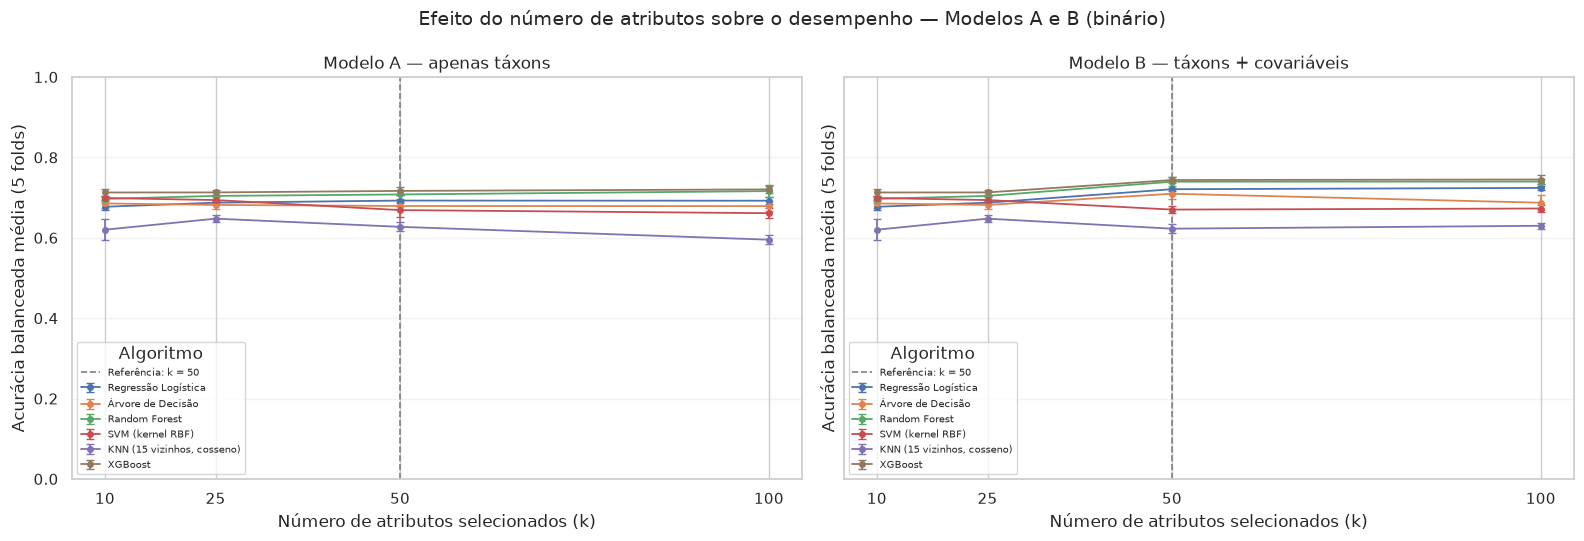

In [26]:
# ============================================================
# 1. Adaptador do XGBoost para rótulos textuais binários
# ============================================================

class XGBoostRotulosTexto(ClassifierMixin, BaseEstimator):
    """Adapta rótulos textuais binários à implementação do XGBoost."""

    def __init__(self, random_state=42):
        self.random_state = random_state

    def fit(self, X, y):
        self.codificador_ = LabelEncoder()
        y_codificado = self.codificador_.fit_transform(np.asarray(y))
        if len(self.codificador_.classes_) != 2:
            raise ValueError("Este adaptador foi configurado apenas para classificação binária.")

        self.modelo_ = XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=self.random_state,
            n_jobs=2
        )
        self.modelo_.fit(X, y_codificado)
        self.classes_ = self.codificador_.classes_
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        previsoes_codificadas = self.modelo_.predict(X).astype(int)
        return self.codificador_.inverse_transform(previsoes_codificadas)

    def predict_proba(self, X):
        return self.modelo_.predict_proba(X)

    @property
    def feature_importances_(self):
        return self.modelo_.feature_importances_


# ============================================================
# 2. Construir os seis algoritmos com SelectKBest
# ============================================================
def construir_modelos(score_func, k_atributos=K_ATRIBUTOS_REFERENCIA):
    """Cria pipelines; SelectKBest será ajustado dentro de cada fold."""
    def novo_seletor():
        return SelectKBest(score_func=score_func, k=k_atributos)

    return {
        "Regressão Logística": Pipeline([
            ("selecao", novo_seletor()),
            ("padronizacao", StandardScaler()),
            ("modelo", LogisticRegression(
                max_iter=3000, class_weight="balanced", random_state=42
            ))
        ]),
        "Árvore de Decisão": Pipeline([
            ("selecao", novo_seletor()),
            ("modelo", DecisionTreeClassifier(
                max_depth=6, class_weight="balanced", random_state=42
            ))
        ]),
        "Random Forest": Pipeline([
            ("selecao", novo_seletor()),
            ("modelo", RandomForestClassifier(
                n_estimators=60, max_depth=12, min_samples_leaf=3,
                max_features="sqrt", class_weight="balanced",
                random_state=42, n_jobs=2
            ))
        ]),
        "SVM (kernel RBF)": Pipeline([
            ("selecao", novo_seletor()),
            ("modelo", CalibratedClassifierCV(
                estimator=SVC(
                    kernel="rbf", C=1.0, gamma="scale",
                    class_weight="balanced", random_state=42,
                    cache_size=512
                ),
                method="sigmoid", cv=5, ensemble=False
            ))
        ]),
        "KNN (15 vizinhos, cosseno)": Pipeline([
            ("selecao", novo_seletor()),
            ("modelo", KNeighborsClassifier(
                n_neighbors=15, weights="distance", metric="cosine", n_jobs=2
            ))
        ]),
        "XGBoost": Pipeline([
            ("selecao", novo_seletor()),
            ("modelo", XGBoostRotulosTexto(random_state=42))
        ])
    }


# ============================================================
# 2.1 Pré-processamento misto e construção dos modelos B
# ============================================================
def construir_preprocessador_integrado(colunas_taxonomicas=None):
    """Preserva táxons e pré-processa covariáveis dentro de cada fold."""
    if colunas_taxonomicas is None:
        colunas_taxonomicas = COLUNAS_TAXONOMICAS

    pipeline_numerico = Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("escala", StandardScaler())
    ])
    try:
        codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        codificador = OneHotEncoder(handle_unknown="ignore", sparse=False)

    pipeline_categorico = Pipeline([
        ("imputacao", SimpleImputer(strategy="most_frequent")),
        ("onehot", codificador)
    ])

    transformadores = [("taxons", "passthrough", colunas_taxonomicas)]
    if COLUNAS_NUMERICAS:
        transformadores.append(("numericas", pipeline_numerico, COLUNAS_NUMERICAS))
    if COLUNAS_CATEGORICAS:
        transformadores.append(("categoricas", pipeline_categorico, COLUNAS_CATEGORICAS))

    return ColumnTransformer(
        transformers=transformadores,
        remainder="drop",
        sparse_threshold=0.0
    )


def construir_modelos_integrados(score_func, colunas_taxonomicas=None):
    """Pré-processa covariáveis e preserva táxons antes do SelectKBest."""
    modelos_base = construir_modelos(score_func)
    modelos_integrados = {}
    for nome, pipeline_base in modelos_base.items():
        etapas = [("preprocessamento", construir_preprocessador_integrado(colunas_taxonomicas))]
        etapas.extend(pipeline_base.steps)
        modelos_integrados[nome] = Pipeline(etapas)
    return modelos_integrados


# ============================================================
# 3. Métricas para a busca binária
# ============================================================
metricas_cv_bin = {
    "acuracia": "accuracy",
    "acuracia_balanceada": "balanced_accuracy",
    "f1_macro": "f1_macro",
    "recall_com_periodontite": make_scorer(
        recall_score, pos_label=class_order_bin[1]
    ),
    "recall_sem_periodontite": make_scorer(
        recall_score, pos_label=class_order_bin[0]
    ),
    "roc_auc": "roc_auc"
}


# ============================================================
# 4. Função comum para executar GridSearchCV por algoritmo
# ============================================================
def executar_buscas_k(modelos, X, y, cv, scoring, nome_desfecho):
    """Testa os valores de k para cada modelo usando as mesmas partições."""
    buscas = {}
    resumo_modelos = []
    resultados_por_k = []

    for nome, pipeline in modelos.items():
        print(f"\nGridSearchCV — {nome_desfecho} — {nome}")
        busca = GridSearchCV(
            estimator=pipeline,
            param_grid={"selecao__k": K_ATRIBUTOS_CANDIDATOS},
            scoring=scoring,
            refit="acuracia_balanceada",
            cv=cv,
            n_jobs=1,
            return_train_score=False,
            error_score="raise",
            verbose=0,
            pre_dispatch=1
        )
        busca.fit(X, y)
        buscas[nome] = busca

        cv_resultados = busca.cv_results_
        indice_melhor = busca.best_index_
        indice_referencia = next(
            i for i, parametros in enumerate(cv_resultados["params"])
            if parametros["selecao__k"] == K_ATRIBUTOS_REFERENCIA
        )
        resumo_modelos.append({
            "Modelo": nome,
            "k escolhido": int(busca.best_params_["selecao__k"]),
            "Acurácia balanceada média": cv_resultados["mean_test_acuracia_balanceada"][indice_melhor],
            "DP da acurácia balanceada": cv_resultados["std_test_acuracia_balanceada"][indice_melhor],
            "Acurácia balanceada média (k=50)": cv_resultados["mean_test_acuracia_balanceada"][indice_referencia],
            "F1-macro médio": cv_resultados["mean_test_f1_macro"][indice_melhor],
            "Acurácia média": cv_resultados["mean_test_acuracia"][indice_melhor],
            "Recall médio (com periodontite)": cv_resultados["mean_test_recall_com_periodontite"][indice_melhor],
            "Recall médio (sem periodontite)": cv_resultados["mean_test_recall_sem_periodontite"][indice_melhor],
            "ROC-AUC média": cv_resultados["mean_test_roc_auc"][indice_melhor]
        })

        for indice, parametros in enumerate(cv_resultados["params"]):
            resultados_por_k.append({
                "Modelo": nome,
                "k": int(parametros["selecao__k"]),
                "Acurácia balanceada média": cv_resultados["mean_test_acuracia_balanceada"][indice],
                "DP da acurácia balanceada": cv_resultados["std_test_acuracia_balanceada"][indice],
                "F1-macro médio": cv_resultados["mean_test_f1_macro"][indice]
            })

        print(
            f"Melhor k: {busca.best_params_['selecao__k']} | "
            f"Acurácia balanceada média: {busca.best_score_:.4f}"
        )

    tabela_resumo = (
        pd.DataFrame(resumo_modelos)
        .sort_values("Acurácia balanceada média", ascending=False)
        .reset_index(drop=True)
    )
    tabela_por_k = pd.DataFrame(resultados_por_k)
    melhores_estimadores = {
        nome: busca.best_estimator_ for nome, busca in buscas.items()
    }
    return buscas, melhores_estimadores, tabela_resumo, tabela_por_k


# ============================================================
# 5. Busca do Modelo A — apenas táxons
# ============================================================
modelos_binarios_base = construir_modelos(pontuacao_mannwhitney)
(
    gridsearch_binarios,
    modelos_binarios,
    resultados_cv_bin,
    resultados_k_bin
) = executar_buscas_k(
    modelos=modelos_binarios_base,
    X=X_train,
    y=y_train_bin,
    cv=cv_bin,
    scoring=metricas_cv_bin,
    nome_desfecho="binário — Modelo A (apenas táxons)"
)
print("\nResultados — Modelo A, desfecho binário:")
display(resultados_cv_bin.round(3))


# ============================================================
# 6. Busca do Modelo B — táxons + covariáveis
# ============================================================
modelos_binarios_integrados_base = construir_modelos_integrados(pontuacao_mannwhitney)
(
    gridsearch_binarios_integrados,
    modelos_binarios_integrados,
    resultados_cv_bin_integrado,
    resultados_k_bin_integrado
) = executar_buscas_k(
    modelos=modelos_binarios_integrados_base,
    X=X_train_integrado,
    y=y_train_bin,
    cv=cv_bin,
    scoring=metricas_cv_bin,
    nome_desfecho="binário — Modelo B (táxons + covariáveis)"
)
print("\nResultados — Modelo B, desfecho binário:")
display(resultados_cv_bin_integrado.round(3))


# ============================================================
# 7. Comparar as melhores combinações algoritmo + k entre A e B
# ============================================================
comparacao_cv_modelos = pd.DataFrame([
    {
        "Desfecho": "Binário",
        "Configuração": "Modelo A — apenas táxons",
        "Algoritmo": resultados_cv_bin.iloc[0]["Modelo"],
        "k escolhido": resultados_cv_bin.iloc[0]["k escolhido"],
        "Acurácia balanceada média": resultados_cv_bin.iloc[0]["Acurácia balanceada média"]
    },
    {
        "Desfecho": "Binário",
        "Configuração": "Modelo B — táxons + covariáveis",
        "Algoritmo": resultados_cv_bin_integrado.iloc[0]["Modelo"],
        "k escolhido": resultados_cv_bin_integrado.iloc[0]["k escolhido"],
        "Acurácia balanceada média": resultados_cv_bin_integrado.iloc[0]["Acurácia balanceada média"]
    }
])
print("\nMelhor combinação algoritmo + k na validação cruzada:")
display(comparacao_cv_modelos.round(4))


# ============================================================
# 8. Visualizar a relação entre k e acurácia balanceada
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
configuracoes_grafico = [
    (axes[0], resultados_k_bin, "Modelo A — apenas táxons"),
    (axes[1], resultados_k_bin_integrado, "Modelo B — táxons + covariáveis")
]

for ax, tabela, titulo in configuracoes_grafico:
    for nome_modelo, grupo in tabela.groupby("Modelo", sort=False):
        grupo = grupo.sort_values("k")
        ax.errorbar(
            grupo["k"],
            grupo["Acurácia balanceada média"],
            yerr=grupo["DP da acurácia balanceada"],
            marker="o",
            markersize=4,
            capsize=3,
            linewidth=1.3,
            label=nome_modelo
        )
    ax.axvline(
        K_ATRIBUTOS_REFERENCIA,
        color="gray",
        linestyle="--",
        linewidth=1.2,
        label="Referência: k = 50"
    )
    ax.set_xticks(sorted(K_ATRIBUTOS_CANDIDATOS))
    ax.set_xlabel("Número de atributos selecionados (k)")
    ax.set_ylabel("Acurácia balanceada média (5 folds)")
    ax.set_title(titulo)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=7, title="Algoritmo")

fig.suptitle(
    "Efeito do número de atributos sobre o desempenho — Modelos A e B (binário)",
    fontsize=14
)
fig.tight_layout()
plt.show()

### 7.2 Análise de sensibilidade à filtragem taxonômica — Modelos A e B


In [27]:
# --------------------------------------------------
# 1. Modelo A — matriz sem filtragem (desfecho binário)
# --------------------------------------------------
modelos_base_sensibilidade_A = construir_modelos(pontuacao_mannwhitney)
modelo_sensibilidade_A_base = modelos_base_sensibilidade_A[
    resultados_cv_bin.iloc[0]["Modelo"]
]
busca_sensibilidade_sem_filtro_bin = GridSearchCV(
    estimator=modelo_sensibilidade_A_base,
    param_grid={"selecao__k": K_ATRIBUTOS_CANDIDATOS},
    scoring=metricas_cv_bin,
    refit="acuracia_balanceada",
    cv=cv_bin,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)
busca_sensibilidade_sem_filtro_bin.fit(X_train_sem_filtro, y_train_bin)

# --------------------------------------------------
# 2. Modelo B — matriz sem filtragem + covariáveis selecionadas
# --------------------------------------------------
modelos_sensibilidade_B = construir_modelos_integrados(
    pontuacao_mannwhitney,
    colunas_taxonomicas=microbial_cols_sem_filtro
)
modelo_sensibilidade_B_base = modelos_sensibilidade_B[
    resultados_cv_bin_integrado.iloc[0]["Modelo"]
]
busca_sensibilidade_B_sem_filtro_bin = GridSearchCV(
    estimator=modelo_sensibilidade_B_base,
    param_grid={"selecao__k": K_ATRIBUTOS_CANDIDATOS},
    scoring=metricas_cv_bin,
    refit="acuracia_balanceada",
    cv=cv_bin,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)
busca_sensibilidade_B_sem_filtro_bin.fit(
    X_train_sem_filtro_integrado, y_train_bin
)

# --------------------------------------------------
# 3. Comparar a validação cruzada nas duas configurações
# --------------------------------------------------
configuracoes_sensibilidade = [
    (
        "Modelo A — apenas táxons",
        resultados_cv_bin.iloc[0]["Modelo"],
        gridsearch_binarios[resultados_cv_bin.iloc[0]["Modelo"]],
        busca_sensibilidade_sem_filtro_bin
    ),
    (
        "Modelo B — táxons + covariáveis",
        resultados_cv_bin_integrado.iloc[0]["Modelo"],
        gridsearch_binarios_integrados[resultados_cv_bin_integrado.iloc[0]["Modelo"]],
        busca_sensibilidade_B_sem_filtro_bin
    )
]

linhas_sensibilidade = []
for identificacao, nome_algoritmo, busca_filtrada, busca_sem_filtro in configuracoes_sensibilidade:
    linhas_sensibilidade.append({
        "Configuração": identificacao,
        "Algoritmo fixado": nome_algoritmo,
        "k — filtrado": int(busca_filtrada.best_params_["selecao__k"]),
        "CV balanceada — filtrado": float(busca_filtrada.best_score_),
        "k — sem filtro": int(busca_sem_filtro.best_params_["selecao__k"]),
        "CV balanceada — sem filtro": float(busca_sem_filtro.best_score_),
        "Diferença CV (sem filtro − filtrado)": float(
            busca_sem_filtro.best_score_ - busca_filtrada.best_score_
        )
    })

comparacao_sensibilidade_filtro = pd.DataFrame(linhas_sensibilidade)
print("Comparação da validação cruzada — matrizes filtrada e sem filtragem (binário):")
display(comparacao_sensibilidade_filtro.round(4))

Comparação da validação cruzada — matrizes filtrada e sem filtragem (binário):


,Configuração,Algoritmo fixado,k — filtrado,CV balanceada — filtrado,k — sem filtro,CV balanceada — sem filtro,Diferença CV (sem filtro − filtrado)
0,Modelo A — apenas táxons,XGBoost,100,0.7204,50,0.7222,0.0018
1,Modelo B — táxons + covariáveis,XGBoost,100,0.7450,100,0.7493,0.0043


## 8. Avaliação final e interpretação do desempenho dos modelos binários (S7)



### 8.1 Avaliação final do Modelo A — apenas táxons


Modelo selecionado para o desfecho binário: XGBoost

Métricas no conjunto de teste — Modelo A — binário:


,Valor
Modelo,XGBoost
Acurácia,0.718176
Acurácia balanceada,0.717275
F1-macro,0.716837
Sensibilidade (com periodontite),0.659751
Especificidade (sem periodontite),0.774799
ROC-AUC,0.776165
PR-AUC (Average Precision),0.77315
Brier score,0.191844



Relatório de classificação — Modelo A — binário:
                  precision    recall  f1-score   support

Sem periodontite       0.70      0.77      0.74       746
Com periodontite       0.74      0.66      0.70       723

        accuracy                           0.72      1469
       macro avg       0.72      0.72      0.72      1469
    weighted avg       0.72      0.72      0.72      1469



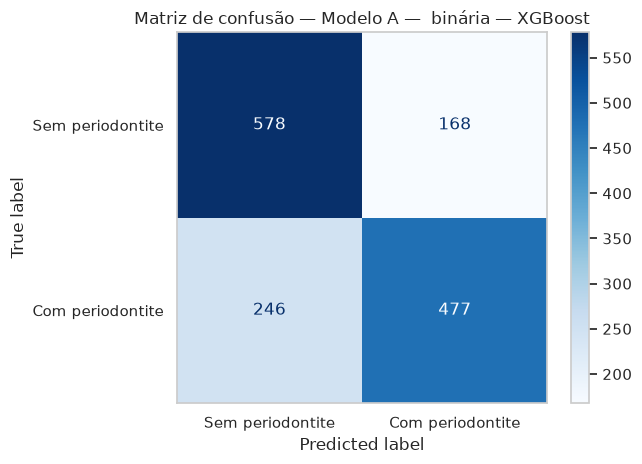

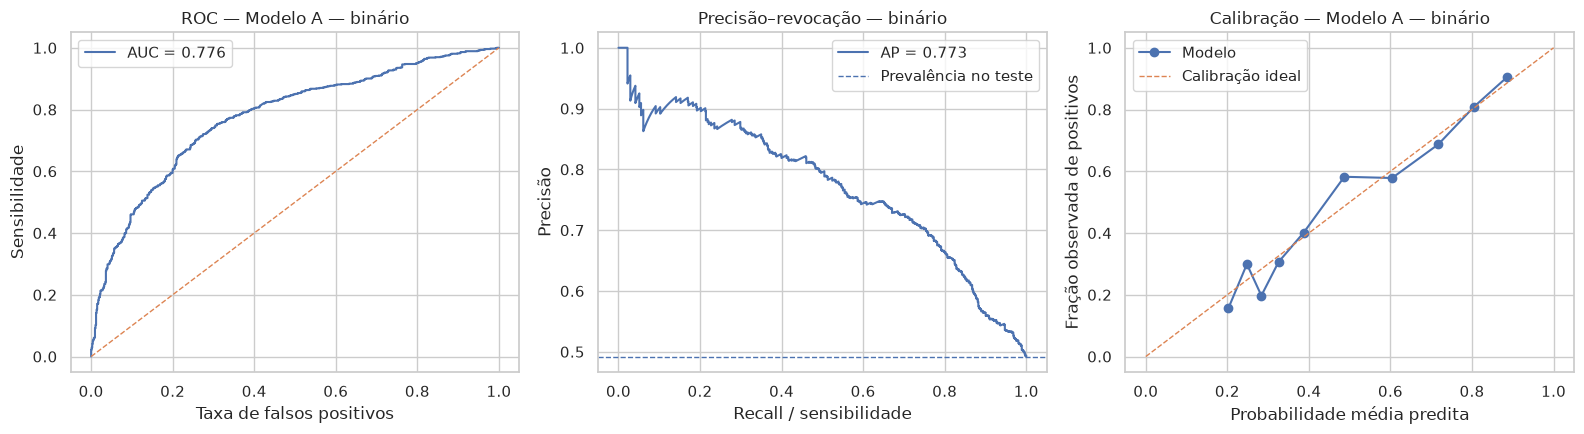

In [28]:
# --------------------------------------------------
# 1. Selecionar, treinar e avaliar o melhor modelo binário
# --------------------------------------------------

melhor_nome_bin = resultados_cv_bin.iloc[0]["Modelo"]
melhor_modelo_bin = modelos_binarios[melhor_nome_bin]
melhor_modelo_bin.fit(X_train, y_train_bin)

y_pred_bin = melhor_modelo_bin.predict(X_test)
probabilidades_bin = melhor_modelo_bin.predict_proba(X_test)
classes_bin_modelo = list(melhor_modelo_bin.classes_)

classe_positiva = class_order_bin[1]
classe_negativa = class_order_bin[0]
indice_positivo = classes_bin_modelo.index(classe_positiva)
y_score_bin = probabilidades_bin[:, indice_positivo]
y_test_01 = (y_test_bin == classe_positiva).astype(int)

matriz_bin = confusion_matrix(
    y_test_bin,
    y_pred_bin,
    labels=[classe_negativa, classe_positiva]
)
tn, fp, fn, tp = matriz_bin.ravel()
especificidade = tn / (tn + fp) if (tn + fp) > 0 else np.nan
sensibilidade = tp / (tp + fn) if (tp + fn) > 0 else np.nan

metricas_teste_bin = pd.DataFrame([{
    "Modelo": melhor_nome_bin,
    "Acurácia": accuracy_score(y_test_bin, y_pred_bin),
    "Acurácia balanceada": balanced_accuracy_score(y_test_bin, y_pred_bin),
    "F1-macro": f1_score(y_test_bin, y_pred_bin, average="macro"),
    "Sensibilidade (com periodontite)": sensibilidade,
    "Especificidade (sem periodontite)": especificidade,
    "ROC-AUC": roc_auc_score(y_test_01, y_score_bin),
    "PR-AUC (Average Precision)": average_precision_score(y_test_01, y_score_bin),
    "Brier score": brier_score_loss(y_test_01, y_score_bin)
}])

print("Modelo selecionado para o desfecho binário:", melhor_nome_bin)
print("\nMétricas no conjunto de teste — Modelo A — binário:")
display(metricas_teste_bin.T.rename(columns={0: "Valor"}).round(4))

# print("\nRelatório de classificação — Modelo A — binário:")
# display(pd.DataFrame(classification_report(
#     y_test_bin,
#     y_pred_bin,
#     labels=[classe_negativa, classe_positiva],
#     target_names=[classe_negativa, classe_positiva],
#     zero_division=0,
#     output_dict=True
# )).T.round(3))


print("\nRelatório de classificação — Modelo A — binário:")
print(classification_report(
    y_test_bin,
    y_pred_bin,
    labels=[classe_negativa, classe_positiva],
    target_names=[classe_negativa, classe_positiva],
    zero_division=0,
))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_bin,
    display_labels=[classe_negativa, classe_positiva]
).plot(values_format="d", cmap="Blues")
plt.title(f"Matriz de confusão — Modelo A —  binária — {melhor_nome_bin}")
plt.grid(False)
plt.tight_layout()
plt.show()

# Curvas binárias: ROC, precisão–revocação e calibração.
fpr, tpr, _ = roc_curve(y_test_01, y_score_bin)
precisao, recall, _ = precision_recall_curve(y_test_01, y_score_bin)
frac_positivos, media_predita = calibration_curve(
    y_test_01,
    y_score_bin,
    n_bins=10,
    strategy="quantile"
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].plot(
    fpr, tpr,
    label=f"AUC = {roc_auc_score(y_test_01, y_score_bin):.3f}"
)
axes[0].plot([0, 1], [0, 1], linestyle="--", linewidth=1)
axes[0].set_title("ROC — Modelo A — binário")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Sensibilidade")
axes[0].legend()

axes[1].plot(
    recall, precisao,
    label=f"AP = {average_precision_score(y_test_01, y_score_bin):.3f}"
)
axes[1].axhline(
    y_test_01.mean(),
    linestyle="--",
    linewidth=1,
    label="Prevalência no teste"
)
axes[1].set_title("Precisão–revocação — binário")
axes[1].set_xlabel("Recall / sensibilidade")
axes[1].set_ylabel("Precisão")
axes[1].legend()

axes[2].plot(
    media_predita, frac_positivos,
    marker="o",
    label="Modelo"
)
axes[2].plot(
    [0, 1], [0, 1],
    linestyle="--",
    linewidth=1,
    label="Calibração ideal"
)
axes[2].set_title("Calibração — Modelo A — binário")
axes[2].set_xlabel("Probabilidade média predita")
axes[2].set_ylabel("Fração observada de positivos")
axes[2].legend()

fig.tight_layout()
plt.show()

### 8.2 Avaliação final do Modelo B — táxons + covariáveis


Modelo B selecionado — desfecho binário: XGBoost
Métricas de teste — Modelo B binário:


,Valor
Modelo,XGBoost
Acurácia,0.757658
Acurácia balanceada,0.756981
F1-macro,0.756919
Sensibilidade (com periodontite),0.713693
Especificidade (sem periodontite),0.800268
ROC-AUC,0.834186
PR-AUC (Average Precision),0.824034
Brier score,0.167779


Relatório de classificação — Modelo B binário:
                  precision    recall  f1-score   support

Sem periodontite       0.74      0.80      0.77       746
Com periodontite       0.78      0.71      0.74       723

        accuracy                           0.76      1469
       macro avg       0.76      0.76      0.76      1469
    weighted avg       0.76      0.76      0.76      1469



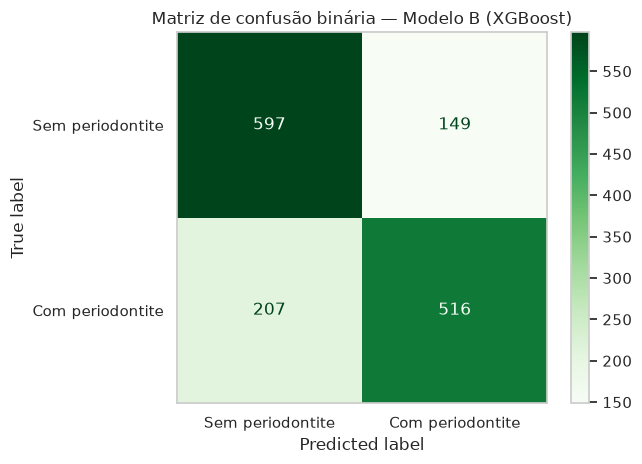


Comparação final dos Modelos A e B no mesmo conjunto de teste — desfecho binário:


,Configuração,Algoritmo,Acurácia balanceada,F1-macro,Sensibilidade,Especificidade,ROC-AUC
0,Modelo A — apenas táxons,XGBoost,0.7173,0.7168,0.6598,0.7748,0.7762
1,Modelo B — táxons + covariáveis,XGBoost,0.7570,0.7569,0.7137,0.8003,0.8342


In [29]:
# --------------------------------------------------
# 1. Modelo B — melhor algoritmo para o desfecho binário
# --------------------------------------------------
melhor_nome_bin_integrado = resultados_cv_bin_integrado.iloc[0]["Modelo"]
melhor_modelo_bin_integrado = modelos_binarios_integrados[melhor_nome_bin_integrado]
melhor_modelo_bin_integrado.fit(X_train_integrado, y_train_bin)

y_pred_bin_integrado = melhor_modelo_bin_integrado.predict(X_test_integrado)
probabilidades_bin_integrado = melhor_modelo_bin_integrado.predict_proba(X_test_integrado)
classes_bin_integrado = list(melhor_modelo_bin_integrado.classes_)

classe_negativa = class_order_bin[0]
classe_positiva = class_order_bin[1]
indice_positivo_integrado = classes_bin_integrado.index(classe_positiva)
y_score_bin_integrado = probabilidades_bin_integrado[:, indice_positivo_integrado]
y_test_01 = (y_test_bin == classe_positiva).astype(int)

matriz_bin_integrado = confusion_matrix(
    y_test_bin, y_pred_bin_integrado,
    labels=[classe_negativa, classe_positiva]
)
tn_b, fp_b, fn_b, tp_b = matriz_bin_integrado.ravel()

metricas_teste_bin_integrado = pd.DataFrame([{
    "Modelo": melhor_nome_bin_integrado,
    "Acurácia": accuracy_score(y_test_bin, y_pred_bin_integrado),
    "Acurácia balanceada": balanced_accuracy_score(y_test_bin, y_pred_bin_integrado),
    "F1-macro": f1_score(y_test_bin, y_pred_bin_integrado, average="macro"),
    "Sensibilidade (com periodontite)": tp_b / (tp_b + fn_b) if (tp_b + fn_b) else np.nan,
    "Especificidade (sem periodontite)": tn_b / (tn_b + fp_b) if (tn_b + fp_b) else np.nan,
    "ROC-AUC": roc_auc_score(y_test_01, y_score_bin_integrado),
    "PR-AUC (Average Precision)": average_precision_score(y_test_01, y_score_bin_integrado),
    "Brier score": brier_score_loss(y_test_01, y_score_bin_integrado)
}])

print("Modelo B selecionado — desfecho binário:", melhor_nome_bin_integrado)
print("Métricas de teste — Modelo B binário:")
display(metricas_teste_bin_integrado.T.rename(columns={0: "Valor"}).round(4))
print("Relatório de classificação — Modelo B binário:")

# display(pd.DataFrame(classification_report(
#     y_test_bin, y_pred_bin_integrado,
#     labels=class_order_bin,
#     target_names=class_order_bin,
#     zero_division=0,
#     output_dict=True
# )).T.round(3))

print(classification_report(
    y_test_bin, y_pred_bin_integrado,
    labels=class_order_bin,
    target_names=class_order_bin,
    zero_division=0,
))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_bin_integrado,
    display_labels=class_order_bin
).plot(values_format="d", cmap="Greens")
plt.title(f"Matriz de confusão binária — Modelo B ({melhor_nome_bin_integrado})")
plt.grid(False)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. Comparação das métricas finais dos Modelos A e B
# --------------------------------------------------
comparacao_teste_modelos = pd.DataFrame([
    {
        "Configuração": "Modelo A — apenas táxons",
        "Algoritmo": melhor_nome_bin,
        "Acurácia balanceada": metricas_teste_bin.loc[0, "Acurácia balanceada"],
        "F1-macro": metricas_teste_bin.loc[0, "F1-macro"],
        "Sensibilidade": metricas_teste_bin.loc[0, "Sensibilidade (com periodontite)"],
        "Especificidade": metricas_teste_bin.loc[0, "Especificidade (sem periodontite)"],
        "ROC-AUC": metricas_teste_bin.loc[0, "ROC-AUC"]
    },
    {
        "Configuração": "Modelo B — táxons + covariáveis",
        "Algoritmo": melhor_nome_bin_integrado,
        "Acurácia balanceada": metricas_teste_bin_integrado.loc[0, "Acurácia balanceada"],
        "F1-macro": metricas_teste_bin_integrado.loc[0, "F1-macro"],
        "Sensibilidade": metricas_teste_bin_integrado.loc[0, "Sensibilidade (com periodontite)"],
        "Especificidade": metricas_teste_bin_integrado.loc[0, "Especificidade (sem periodontite)"],
        "ROC-AUC": metricas_teste_bin_integrado.loc[0, "ROC-AUC"]
    }
])
print("\nComparação final dos Modelos A e B no mesmo conjunto de teste — desfecho binário:")
display(comparacao_teste_modelos.round(4))

#### 8.2.1 Curvas de desempenho e calibração — Modelo B



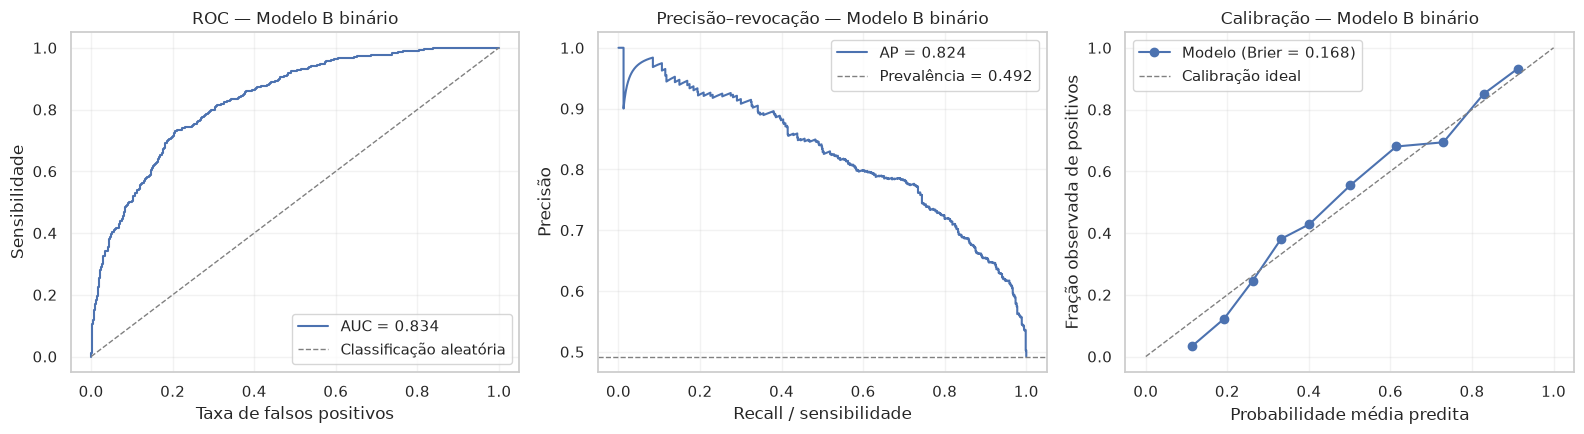

In [30]:
# ============================================================
# Curvas ROC, precisão–revocação e calibração — Modelo B
# ============================================================

# --------------------------------------------------
# 1. Curvas do desfecho binário
# --------------------------------------------------

# Reconstituir explicitamente o vetor binário da classe positiva.
y_test_bin_01_integrado = (y_test_bin == classe_positiva).astype(int)

fpr_bin_integrado, tpr_bin_integrado, _ = roc_curve(
    y_test_bin_01_integrado,
    y_score_bin_integrado
)
precisao_bin_integrado, recall_bin_integrado, _ = precision_recall_curve(
    y_test_bin_01_integrado,
    y_score_bin_integrado
)
fracao_positivos_bin_integrado, media_predita_bin_integrado = calibration_curve(
    y_test_bin_01_integrado,
    y_score_bin_integrado,
    n_bins=10,
    strategy="quantile"
)

auc_bin_integrado = roc_auc_score(
    y_test_bin_01_integrado,
    y_score_bin_integrado
)
ap_bin_integrado = average_precision_score(
    y_test_bin_01_integrado,
    y_score_bin_integrado
)
brier_bin_integrado = brier_score_loss(
    y_test_bin_01_integrado,
    y_score_bin_integrado
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# ROC binária.
axes[0].plot(
    fpr_bin_integrado,
    tpr_bin_integrado,
    label=f"AUC = {auc_bin_integrado:.3f}"
)
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
    label="Classificação aleatória"
)
axes[0].set_title("ROC — Modelo B binário")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Sensibilidade")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Precisão–revocação binária.
axes[1].plot(
    recall_bin_integrado,
    precisao_bin_integrado,
    label=f"AP = {ap_bin_integrado:.3f}"
)
axes[1].axhline(
    y_test_bin_01_integrado.mean(),
    linestyle="--",
    color="gray",
    linewidth=1,
    label=f"Prevalência = {y_test_bin_01_integrado.mean():.3f}"
)
axes[1].set_title("Precisão–revocação — Modelo B binário")
axes[1].set_xlabel("Recall / sensibilidade")
axes[1].set_ylabel("Precisão")
axes[1].legend()
axes[1].grid(alpha=0.25)

# Calibração binária.
axes[2].plot(
    media_predita_bin_integrado,
    fracao_positivos_bin_integrado,
    marker="o",
    label=f"Modelo (Brier = {brier_bin_integrado:.3f})"
)
axes[2].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
    label="Calibração ideal"
)
axes[2].set_title("Calibração — Modelo B binário")
axes[2].set_xlabel("Probabilidade média predita")
axes[2].set_ylabel("Fração observada de positivos")
axes[2].legend()
axes[2].grid(alpha=0.25)

fig.tight_layout()
plt.show()

### 8.3 Avaliação final da sensibilidade à filtragem taxonômica — Modelos A e B


In [31]:
# --------------------------------------------------
# 1. Previsões nos mesmos participantes do teste
# --------------------------------------------------
modelo_A_sem_filtro_bin = busca_sensibilidade_sem_filtro_bin.best_estimator_
modelo_B_sem_filtro_bin = busca_sensibilidade_B_sem_filtro_bin.best_estimator_

y_pred_bin_A_sem_filtro = modelo_A_sem_filtro_bin.predict(X_test_sem_filtro)
y_pred_bin_B_sem_filtro = modelo_B_sem_filtro_bin.predict(X_test_sem_filtro_integrado)

# --------------------------------------------------
# 2. Consolidar validação cruzada e métricas de teste para A e B
# --------------------------------------------------
linhas_comparacao_teste_filtro = []

# Modelo A — apenas táxons
for representacao, busca, previsoes in [
    ("Filtrada", gridsearch_binarios[melhor_nome_bin], y_pred_bin),
    ("Sem filtragem", busca_sensibilidade_sem_filtro_bin, y_pred_bin_A_sem_filtro)
]:
    linhas_comparacao_teste_filtro.append({
        "Modelo": "A — apenas táxons",
        "Desfecho": "Binário",
        "Representação": representacao,
        "Algoritmo": melhor_nome_bin,
        "k selecionado": int(busca.best_params_["selecao__k"]),
        "CV — acurácia balanceada": float(busca.best_score_),
        "Teste — acurácia balanceada": balanced_accuracy_score(y_test_bin, previsoes),
        "Teste — F1-macro": f1_score(y_test_bin, previsoes, average="macro")
    })

# Modelo B — táxons + covariáveis
for representacao, busca, previsoes in [
    ("Filtrada", gridsearch_binarios_integrados[melhor_nome_bin_integrado], y_pred_bin_integrado),
    ("Sem filtragem", busca_sensibilidade_B_sem_filtro_bin, y_pred_bin_B_sem_filtro)
]:
    linhas_comparacao_teste_filtro.append({
        "Modelo": "B — táxons + covariáveis",
        "Desfecho": "Binário",
        "Representação": representacao,
        "Algoritmo": melhor_nome_bin_integrado,
        "k selecionado": int(busca.best_params_["selecao__k"]),
        "CV — acurácia balanceada": float(busca.best_score_),
        "Teste — acurácia balanceada": balanced_accuracy_score(y_test_bin, previsoes),
        "Teste — F1-macro": f1_score(y_test_bin, previsoes, average="macro")
    })

comparacao_sensibilidade_teste = pd.DataFrame(linhas_comparacao_teste_filtro)
print("Comparação da filtragem no mesmo conjunto de teste — Modelos A e B (binário):")
display(comparacao_sensibilidade_teste.round(4))

Comparação da filtragem no mesmo conjunto de teste — Modelos A e B (binário):


,Modelo,Desfecho,Representação,Algoritmo,k selecionado,CV — acurácia balanceada,Teste — acurácia balanceada,Teste — F1-macro
0,A — apenas táxons,Binário,Filtrada,XGBoost,100,0.7204,0.7173,0.7168
1,A — apenas táxons,Binário,Sem filtragem,XGBoost,50,0.7222,0.7020,0.7009
2,B — táxons + covariáveis,Binário,Filtrada,XGBoost,100,0.7450,0.7570,0.7569
3,B — táxons + covariáveis,Binário,Sem filtragem,XGBoost,100,0.7493,0.7535,0.7533


## 9. Associação entre covariáveis e avaliação de redundância

### 9.1 Matriz de associação e identificação de pares altamente associados



Covariáveis incluídas na análise: ['Idade (anos)', 'Sexo', 'Raça/etnia', 'Escolaridade', 'Estado civil', 'Razão renda/pobreza', 'Consumo de álcool', 'Atividade física', 'Hipertensão', 'Diabetes', 'Doença cardiovascular', 'Histórico de câncer']
Limiar de alta associação: ≥ 0.80


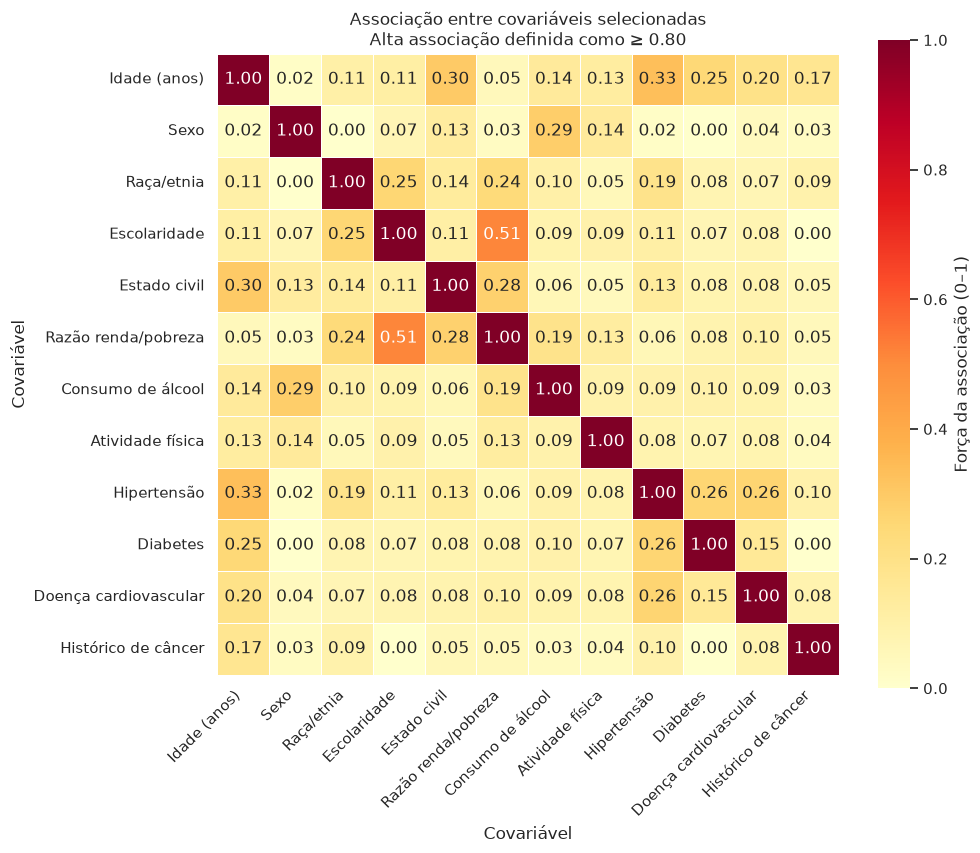


Pares de covariáveis com alta associação:
Nenhum par atingiu o limiar definido.

Número de observações válidas em cada par:


,Idade (anos),Sexo,Raça/etnia,Escolaridade,Estado civil,Razão renda/pobreza,Consumo de álcool,Atividade física,Hipertensão,Diabetes,Doença cardiovascular,Histórico de câncer
Idade (anos),4407,4407,4407,4401,4403,4046,3998,4396,4401,4404,4387,4399
Sexo,4407,4407,4407,4401,4403,4046,3998,4396,4401,4404,4387,4399
Raça/etnia,4407,4407,4407,4401,4403,4046,3998,4396,4401,4404,4387,4399
Escolaridade,4401,4401,4401,4401,4397,4042,3992,4390,4395,4398,4381,4394
Estado civil,4403,4403,4403,4397,4403,4044,3994,4392,4397,4400,4384,4395
Razão renda/pobreza,4046,4046,4046,4042,4044,4046,3690,4035,4041,4044,4030,4042
Consumo de álcool,3998,3998,3998,3992,3994,3690,3998,3989,3993,3995,3980,3990
Atividade física,4396,4396,4396,4390,4392,4035,3989,4396,4390,4393,4376,4389
Hipertensão,4401,4401,4401,4395,4397,4041,3993,4390,4401,4398,4381,4393
Diabetes,4404,4404,4404,4398,4400,4044,3995,4393,4398,4404,4385,4397


In [32]:
# ============================================================
# Associação entre covariáveis: Pearson, V de Cramér e eta
# ============================================================

LIMIAR_ASSOCIACAO_ALTA = 0.80

# Utilizar somente os preditores selecionados e apenas o conjunto de treino.
# Isso mantém a análise alinhada às variáveis efetivamente usadas no Modelo B
# e não consulta o conjunto reservado para avaliação final.
X_covariaveis_associacao = X_train_integrado[
    covariaveis_modelo_selecionadas
].copy()

rotulos_covariaveis_associacao = {
    coluna: rotulos_covariaveis.get(coluna, coluna)
    for coluna in covariaveis_modelo_selecionadas
}
conjunto_numericas_associacao = set(COLUNAS_NUMERICAS_BASE)


def calcular_cramers_v_corrigido(x, y):
    """V de Cramér com correção de viés para duas variáveis categóricas."""
    tabela = pd.crosstab(x, y)
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        return np.nan

    valores = tabela.to_numpy(dtype=float)
    n = valores.sum()
    if n <= 1:
        return np.nan

    qui_quadrado = stats.chi2_contingency(valores, correction=False)[0]
    phi2 = qui_quadrado / n
    n_linhas, n_colunas = valores.shape

    phi2_corrigido = max(
        0.0,
        phi2 - ((n_colunas - 1) * (n_linhas - 1)) / (n - 1)
    )
    linhas_corrigidas = n_linhas - ((n_linhas - 1) ** 2) / (n - 1)
    colunas_corrigidas = n_colunas - ((n_colunas - 1) ** 2) / (n - 1)
    denominador = min(colunas_corrigidas - 1, linhas_corrigidas - 1)

    if denominador <= 0:
        return np.nan
    return float(np.sqrt(phi2_corrigido / denominador))


def calcular_eta(numerica, categorica):
    """Razão de correlação eta para associação entre variável numérica e categórica."""
    dados = pd.DataFrame({
        "numerica": pd.to_numeric(numerica, errors="coerce"),
        "categorica": categorica
    }).replace([np.inf, -np.inf], np.nan).dropna()

    if len(dados) < 2 or dados["categorica"].nunique() < 2:
        return np.nan

    media_geral = dados["numerica"].mean()
    soma_quadrados_total = ((dados["numerica"] - media_geral) ** 2).sum()
    if soma_quadrados_total <= 0:
        return np.nan

    soma_quadrados_entre = 0.0
    for _, grupo in dados.groupby("categorica", observed=True):
        soma_quadrados_entre += len(grupo) * (grupo["numerica"].mean() - media_geral) ** 2

    return float(np.sqrt(max(0.0, soma_quadrados_entre / soma_quadrados_total)))


def calcular_associacao_par(coluna_a, coluna_b, dados):
    """Seleciona uma medida de associação adequada ao tipo de cada par."""
    serie_a = dados[coluna_a]
    serie_b = dados[coluna_b]
    a_numerica = coluna_a in conjunto_numericas_associacao
    b_numerica = coluna_b in conjunto_numericas_associacao

    if a_numerica and b_numerica:
        par = pd.DataFrame({
            "a": pd.to_numeric(serie_a, errors="coerce"),
            "b": pd.to_numeric(serie_b, errors="coerce")
        }).replace([np.inf, -np.inf], np.nan).dropna()
        if len(par) < 3:
            return np.nan, "Pearson |r|", len(par)
        coeficiente = par["a"].corr(par["b"], method="pearson")
        valor = abs(coeficiente) if pd.notna(coeficiente) else np.nan
        return valor, "Pearson |r|", len(par)

    if a_numerica != b_numerica:
        if a_numerica:
            numerica, categorica = serie_a, serie_b
        else:
            numerica, categorica = serie_b, serie_a
        par = pd.DataFrame({
            "numerica": pd.to_numeric(numerica, errors="coerce"),
            "categorica": categorica
        }).replace([np.inf, -np.inf], np.nan).dropna()
        return calcular_eta(par["numerica"], par["categorica"]), "Razão de correlação (η)", len(par)

    par = pd.DataFrame({"a": serie_a, "b": serie_b}).dropna()
    return calcular_cramers_v_corrigido(par["a"], par["b"]), "V de Cramér corrigido", len(par)


covariaveis_ativas_associacao = list(covariaveis_modelo_selecionadas)
rotulos_heatmap = [rotulos_covariaveis_associacao[c] for c in covariaveis_ativas_associacao]
matriz_associacao = pd.DataFrame(
    np.eye(len(covariaveis_ativas_associacao)),
    index=rotulos_heatmap,
    columns=rotulos_heatmap
)
matriz_n_pares = pd.DataFrame(
    np.zeros((len(covariaveis_ativas_associacao), len(covariaveis_ativas_associacao)), dtype=int),
    index=rotulos_heatmap,
    columns=rotulos_heatmap
)
registros_associacao = []

for i, coluna_a in enumerate(covariaveis_ativas_associacao):
    matriz_n_pares.iloc[i, i] = X_covariaveis_associacao[coluna_a].notna().sum()
    for j in range(i + 1, len(covariaveis_ativas_associacao)):
        coluna_b = covariaveis_ativas_associacao[j]
        valor, metodo, n_par = calcular_associacao_par(
            coluna_a, coluna_b, X_covariaveis_associacao
        )
        rotulo_a = rotulos_covariaveis_associacao[coluna_a]
        rotulo_b = rotulos_covariaveis_associacao[coluna_b]
        matriz_associacao.loc[rotulo_a, rotulo_b] = valor
        matriz_associacao.loc[rotulo_b, rotulo_a] = valor
        matriz_n_pares.loc[rotulo_a, rotulo_b] = n_par
        matriz_n_pares.loc[rotulo_b, rotulo_a] = n_par
        registros_associacao.append({
            "Covariável 1": rotulo_a,
            "Covariável 2": rotulo_b,
            "Força da associação": valor,
            "Medida": metodo,
            "n válido": n_par
        })

print("Covariáveis incluídas na análise:", rotulos_heatmap)
print("Limiar de alta associação:", f"≥ {LIMIAR_ASSOCIACAO_ALTA:.2f}")

fig, ax = plt.subplots(
    figsize=(max(9, 0.85 * len(rotulos_heatmap)), max(7, 0.72 * len(rotulos_heatmap)))
)
sns.heatmap(
    matriz_associacao.astype(float),
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Força da associação (0–1)"},
    ax=ax
)
ax.set_title(
    "Associação entre covariáveis selecionadas\n"
    f"Alta associação definida como ≥ {LIMIAR_ASSOCIACAO_ALTA:.2f}"
)
ax.set_xlabel("Covariável")
ax.set_ylabel("Covariável")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
fig.tight_layout()
plt.show()

# Listar apenas pares não redundantes com associação igual ou superior a 0,80.
df_pares_associacao = pd.DataFrame(
    registros_associacao,
    columns=["Covariável 1", "Covariável 2", "Força da associação", "Medida", "n válido"]
)
df_pares_altamente_associados = (
    df_pares_associacao.loc[
        df_pares_associacao["Força da associação"] >= LIMIAR_ASSOCIACAO_ALTA
    ]
    .sort_values("Força da associação", ascending=False)
    .reset_index(drop=True)
)

print("\nPares de covariáveis com alta associação:")
if df_pares_altamente_associados.empty:
    print("Nenhum par atingiu o limiar definido.")
else:
    display(df_pares_altamente_associados.round(3))

print("\nNúmero de observações válidas em cada par:")
display(matriz_n_pares)

## 10. Interpretação dos modelos e caracterização dos táxons por importância de permutação (S4)

Esta seção compara a importância por permutação nas duas configurações preditivas para o **desfecho binário**:

- **Modelo A — apenas táxons:** estima a dependência preditiva em relação aos atributos microbiológicos.
- **Modelo B — táxons + covariáveis:** estima a dependência preditiva considerando os táxons e somente as covariáveis ativadas na subseção 4.4.


### 10.1 Cálculo da importância por permutação



In [33]:
# ============================================================
# 10.1 Cálculo da importância por permutação — Modelos A e B (binário)
# ============================================================

N_REPETICOES_PERMUTACAO = 30

mapa_rotulos_taxonomicos_pfi = dict(zip(microbial_cols, rotular_taxons(microbial_cols)))
mapa_rotulos_covariaveis_pfi = rotulos_covariaveis.copy()
CONJUNTO_TAXONS_PFI = set(COLUNAS_TAXONOMICAS)
CONJUNTO_COVARIAVEIS_PFI = set(covariaveis_modelo_selecionadas)


def descrever_variavel_pfi(codigo):
    if codigo in CONJUNTO_TAXONS_PFI:
        return "Táxon", mapa_rotulos_taxonomicos_pfi.get(codigo, codigo)
    if codigo in CONJUNTO_COVARIAVEIS_PFI:
        return "Covariável", mapa_rotulos_covariaveis_pfi.get(codigo, codigo)
    return "Outra", str(codigo)


def calcular_importancia_permutacao_completa(
    modelo, X_teste, y_teste, identificacao_modelo,
    nome_algoritmo, k_selecionado, random_state=42
):
    """Permuta cada coluna original; categóricas permanecem como uma unidade."""
    if not isinstance(X_teste, pd.DataFrame):
        raise TypeError("X_teste precisa ser DataFrame para preservar os nomes das variáveis.")
    if not X_teste.columns.is_unique:
        raise ValueError("Há nomes de colunas duplicados na matriz de teste.")
    if len(X_teste) != len(y_teste):
        raise ValueError("X_teste e y_teste possuem números de participantes diferentes.")

    score_base = balanced_accuracy_score(y_teste, modelo.predict(X_teste))
    rng = np.random.default_rng(random_state)
    registros = []
    print(
        f"\n{identificacao_modelo}: {len(X_teste.columns)} variáveis; "
        f"{N_REPETICOES_PERMUTACAO} permutações/variável."
    )
    print(f"Acurácia balanceada basal: {score_base:.4f}")

    for indice, variavel in enumerate(X_teste.columns, start=1):
        valores_originais = X_teste[variavel].to_numpy(copy=True)
        quedas = np.empty(N_REPETICOES_PERMUTACAO, dtype=float)
        for repeticao in range(N_REPETICOES_PERMUTACAO):
            X_permutado = X_teste.copy(deep=True)
            X_permutado[variavel] = rng.permutation(valores_originais)
            score_permutado = balanced_accuracy_score(
                y_teste, modelo.predict(X_permutado)
            )
            quedas[repeticao] = score_base - score_permutado

        tipo, rotulo = descrever_variavel_pfi(variavel)
        registros.append({
            "Modelo": identificacao_modelo,
            "Desfecho": "Binário",
            "Algoritmo": nome_algoritmo,
            "k selecionado": int(k_selecionado),
            "Código": variavel,
            "Variável": rotulo,
            "Tipo de variável": tipo,
            "Queda média da acurácia balanceada": float(np.mean(quedas)),
            "Desvio-padrão": float(np.std(quedas, ddof=1)),
            "Acurácia balanceada basal": float(score_base),
            "N repetições": int(N_REPETICOES_PERMUTACAO)
        })
        if indice % 25 == 0 or indice == len(X_teste.columns):
            print(f"  Variáveis avaliadas: {indice}/{len(X_teste.columns)}")

    tabela = pd.DataFrame(registros).sort_values(
        "Queda média da acurácia balanceada", ascending=False
    ).reset_index(drop=True)
    tabela["Ranking geral"] = np.arange(1, len(tabela) + 1)
    tabela["Táxon"] = np.where(
        tabela["Tipo de variável"].eq("Táxon"), tabela["Variável"], np.nan
    )
    return tabela


# MODELO A — APENAS TÁXONS
importancia_modelo_A_binaria = calcular_importancia_permutacao_completa(
    melhor_modelo_bin, X_test, y_test_bin,
    "Modelo A — apenas táxons", melhor_nome_bin,
    melhor_modelo_bin.named_steps["selecao"].k, random_state=42
)

# MODELO B — TÁXONS + COVARIÁVEIS SELECIONADAS
importancia_modelo_B_binaria = calcular_importancia_permutacao_completa(
    melhor_modelo_bin_integrado, X_test_integrado, y_test_bin,
    "Modelo B — táxons + covariáveis", melhor_nome_bin_integrado,
    melhor_modelo_bin_integrado.named_steps["selecao"].k, random_state=242
)

colunas_exibicao_pfi = [
    "Ranking geral", "Tipo de variável", "Variável", "Código",
    "Queda média da acurácia balanceada", "Desvio-padrão",
    "Acurácia balanceada basal", "Algoritmo", "k selecionado"
]
for titulo, tabela in [
    ("MODELO A — APENAS TÁXONS | DESFECHO BINÁRIO", importancia_modelo_A_binaria),
    ("MODELO B — TÁXONS + COVARIÁVEIS | DESFECHO BINÁRIO", importancia_modelo_B_binaria)
]:
    print("\n" + "=" * 85 + "\n" + titulo + "\n" + "=" * 85)
    display(tabela[colunas_exibicao_pfi].round(5))


def comparar_ranking_taxons_pfi(tabela_A, tabela_B):
    """Compara os mesmos táxons, distinguindo ranking taxonômico e global B."""
    A = tabela_A.loc[tabela_A["Tipo de variável"].eq("Táxon"), [
        "Código", "Variável", "Queda média da acurácia balanceada", "Ranking geral"
    ]].copy()
    B = tabela_B.loc[tabela_B["Tipo de variável"].eq("Táxon"), [
        "Código", "Variável", "Queda média da acurácia balanceada", "Ranking geral"
    ]].copy()
    B_todos = tabela_B[["Código", "Ranking geral"]].copy()

    A = A.rename(columns={
        "Variável": "Táxon",
        "Queda média da acurácia balanceada": "Importância no Modelo A",
        "Ranking geral": "Ranking no Modelo A"
    })
    B["Ranking entre táxons no Modelo B"] = B[
        "Queda média da acurácia balanceada"
    ].rank(method="min", ascending=False).astype(int)
    B = B.rename(columns={
        "Variável": "Táxon B",
        "Queda média da acurácia balanceada": "Importância no Modelo B"
    })
    B = B.merge(
        B_todos.rename(columns={
            "Ranking geral": "Ranking global no Modelo B (táxons + covariáveis)"
        }),
        on="Código", how="left", validate="one_to_one"
    )

    comparacao = A.merge(B, on="Código", how="inner", validate="one_to_one")
    comparacao["Táxon"] = comparacao["Táxon"].fillna(comparacao["Táxon B"])
    comparacao["Mudança no ranking entre táxons (B - A)"] = (
        comparacao["Ranking entre táxons no Modelo B"] - comparacao["Ranking no Modelo A"]
    )
    comparacao["Ranking médio A/B"] = comparacao[[
        "Ranking no Modelo A", "Ranking entre táxons no Modelo B"
    ]].mean(axis=1)
    return comparacao.sort_values("Ranking médio A/B").reset_index(drop=True)


comparacao_taxons_pfi_binaria = comparar_ranking_taxons_pfi(
    importancia_modelo_A_binaria, importancia_modelo_B_binaria
)
colunas_comparacao_pfi = [
    "Táxon", "Código", "Importância no Modelo A", "Importância no Modelo B",
    "Ranking no Modelo A", "Ranking entre táxons no Modelo B",
    "Mudança no ranking entre táxons (B - A)",
    "Ranking global no Modelo B (táxons + covariáveis)"
]
print("\nCOMPARAÇÃO DOS RANKINGS TAXONÔMICOS — MODELOS A E B — BINÁRIO")
display(comparacao_taxons_pfi_binaria[colunas_comparacao_pfi].round(5))


Modelo A — apenas táxons: 107 variáveis; 30 permutações/variável.
Acurácia balanceada basal: 0.7173


  Variáveis avaliadas: 25/107


  Variáveis avaliadas: 50/107


  Variáveis avaliadas: 75/107


  Variáveis avaliadas: 100/107


  Variáveis avaliadas: 107/107

Modelo B — táxons + covariáveis: 119 variáveis; 30 permutações/variável.
Acurácia balanceada basal: 0.7570


... (6 outputs left out)


MODELO B — TÁXONS + COVARIÁVEIS | DESFECHO BINÁRIO


,Ranking geral,Tipo de variável,Variável,Código,Queda média da acurácia balanceada,Desvio-padrão,Acurácia balanceada basal,Algoritmo,k selecionado
0,1,Covariável,Idade (anos),idade_anos,0.05974,0.00686,0.75698,XGBoost,100
1,2,Táxon,Treponema 2,RSV_genus1307,0.02392,0.00795,0.75698,XGBoost,100
2,3,Covariável,Sexo,sexo,0.01507,0.00480,0.75698,XGBoost,100
3,4,Táxon,Desulfobulbus,RSV_genus1090,0.00912,0.00369,0.75698,XGBoost,100
4,5,Covariável,Razão renda/pobreza,razao_renda_pobreza,0.00818,0.00363,0.75698,XGBoost,100
...,...,...,...,...,...,...,...,...,...
114,115,Táxon,Tannerella,RSV_genus255,-0.00139,0.00077,0.75698,XGBoost,100
115,116,Táxon,Anaeroglobus,RSV_genus726,-0.00208,0.00137,0.75698,XGBoost,100
116,117,Táxon,Actinomycetaceae (família),RSV_genus39,-0.00211,0.00100,0.75698,XGBoost,100
117,118,Táxon,Corynebacterium,RSV_genus52,-0.00290,0.00116,0.75698,XGBoost,100



COMPARAÇÃO DOS RANKINGS TAXONÔMICOS — MODELOS A E B — BINÁRIO


,Táxon,Código,Importância no Modelo A,Importância no Modelo B,Ranking no Modelo A,Ranking entre táxons no Modelo B,Mudança no ranking entre táxons (B - A),Ranking global no Modelo B (táxons + covariáveis)
0,Desulfobulbus,RSV_genus1090,0.01591,0.00912,1,2,1,4
1,Treponema 2,RSV_genus1307,0.01053,0.02392,2,1,-1,2
2,Defluviitaleaceae UCG-011,RSV_genus555,0.00615,0.00605,3,3,0,6
3,Phocaeicola,RSV_genus233,0.00260,0.00325,7,8,1,11
4,Porphyromonas,RSV_genus253,0.00442,0.00121,5,13,8,18
...,...,...,...,...,...,...,...,...
102,[Eubacterium] nodatum group,RSV_genus583,-0.00025,-0.00023,89,91,2,103
103,Acholeplasma,RSV_genus1314,-0.00039,-0.00012,97,84,-13,95
104,Streptococcus,RSV_genus530,-0.00041,-0.00012,98,85,-13,96
105,Atopobium,RSV_genus193,-0.00058,-0.00037,102,94,-8,106


### 10.2 Comparação e visualização da importância por permutação


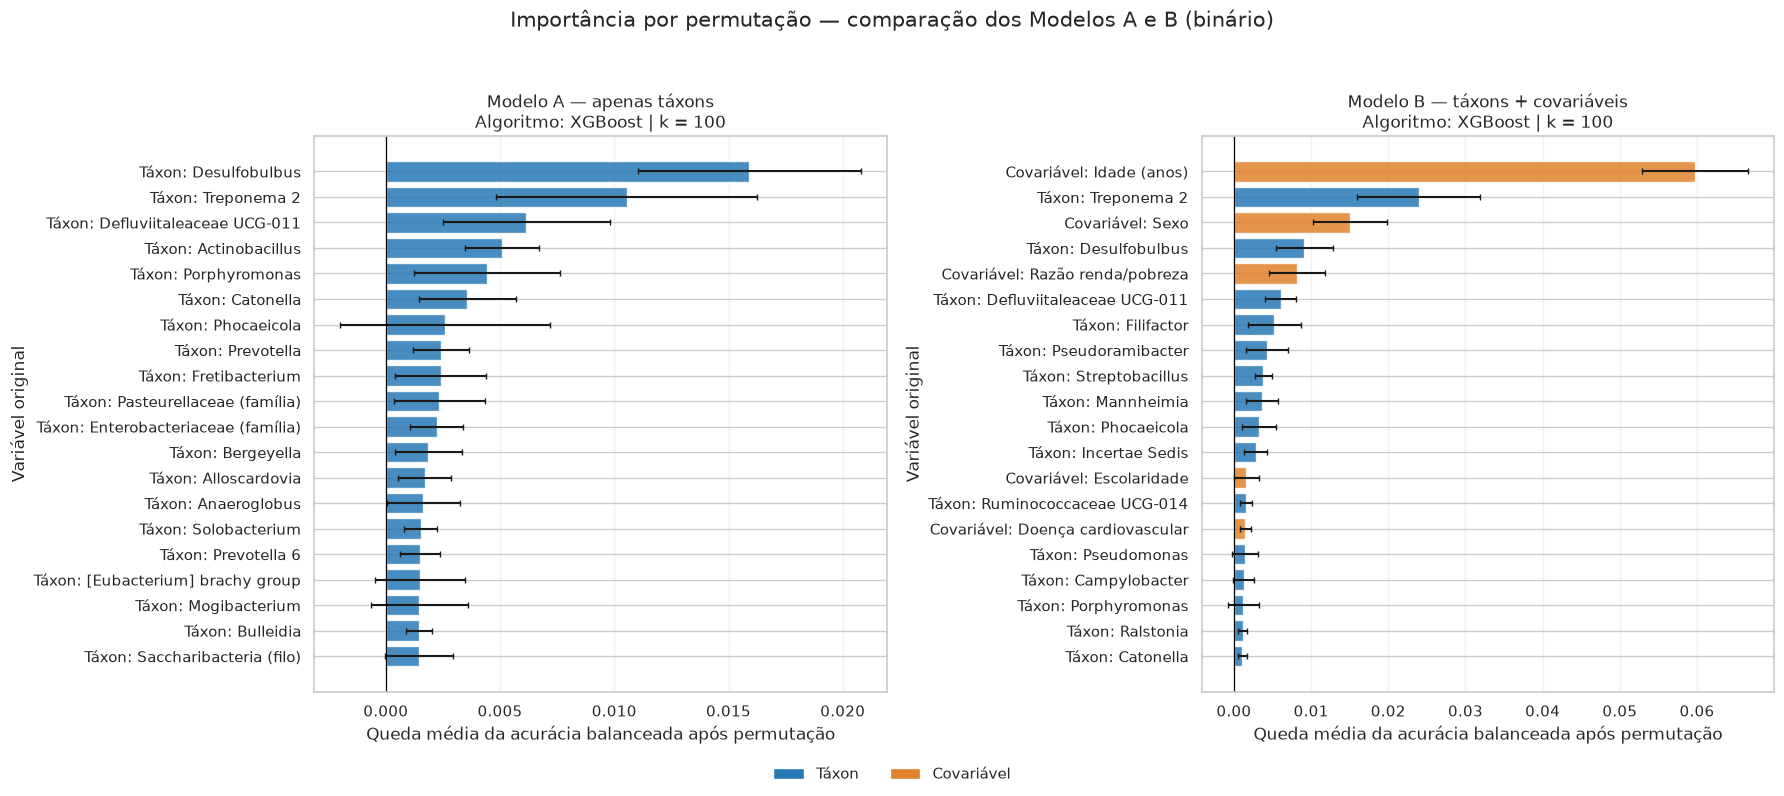

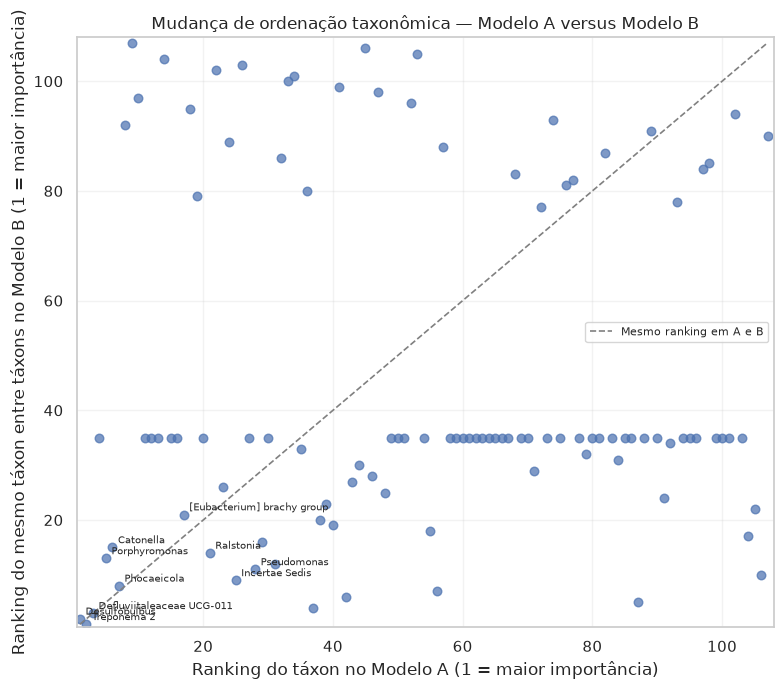

In [34]:
# ============================================================
# 10.2 Visualização da importância por permutação — Modelos A e B
# ============================================================

# ------------------------------------------------------------
# 1. Gráficos de barras: top 20 atributos em cada configuração
# ------------------------------------------------------------
configuracoes_pfi = [
    (importancia_modelo_A_binaria, "Modelo A — apenas táxons"),
    (importancia_modelo_B_binaria, "Modelo B — táxons + covariáveis")
]

cores_tipo_pfi = {"Táxon": "#2878B5", "Covariável": "#E1812C", "Outra": "#777777"}
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, (tabela, nome_modelo) in zip(axes, configuracoes_pfi):
    top = tabela.head(20).copy().sort_values(
        "Queda média da acurácia balanceada", ascending=True
    )
    cores = [cores_tipo_pfi.get(tipo, "#777777") for tipo in top["Tipo de variável"]]
    rotulos = [
        f"{tipo}: {variavel}"
        for tipo, variavel in zip(top["Tipo de variável"], top["Variável"])
    ]
    ax.barh(
        rotulos,
        top["Queda média da acurácia balanceada"],
        xerr=top["Desvio-padrão"],
        color=cores,
        alpha=0.85,
        capsize=2
    )
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_xlabel("Queda média da acurácia balanceada após permutação")
    ax.set_ylabel("Variável original")
    algoritmo = tabela["Algoritmo"].iloc[0]
    k = tabela["k selecionado"].iloc[0]
    ax.set_title(f"{nome_modelo}\nAlgoritmo: {algoritmo} | k = {k}")
    ax.grid(axis="x", alpha=0.25)

from matplotlib.patches import Patch
legenda_pfi = [
    Patch(facecolor=cores_tipo_pfi["Táxon"], label="Táxon"),
    Patch(facecolor=cores_tipo_pfi["Covariável"], label="Covariável")
]
fig.legend(handles=legenda_pfi, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Importância por permutação — comparação dos Modelos A e B (binário)", fontsize=15)
fig.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()


# ------------------------------------------------------------
# 2. Comparar a ordem relativa dos mesmos táxons entre A e B
# ------------------------------------------------------------
comparacao = comparacao_taxons_pfi_binaria
fig, ax = plt.subplots(figsize=(8, 7))
x = comparacao["Ranking no Modelo A"].to_numpy(dtype=float)
y = comparacao["Ranking entre táxons no Modelo B"].to_numpy(dtype=float)
ax.scatter(x, y, alpha=0.72, s=38)
limite = max(
    comparacao["Ranking no Modelo A"].max(),
    comparacao["Ranking entre táxons no Modelo B"].max()
)
ax.plot(
    [1, limite], [1, limite], linestyle="--", color="gray", linewidth=1.2,
    label="Mesmo ranking em A e B"
)

rotulos = comparacao.nsmallest(10, "Ranking médio A/B")
for _, linha in rotulos.iterrows():
    ax.annotate(
        linha["Táxon"],
        (linha["Ranking no Modelo A"], linha["Ranking entre táxons no Modelo B"]),
        xytext=(4, 3), textcoords="offset points", fontsize=7
    )

ax.set_xlim(0.5, limite + 1)
ax.set_ylim(0.5, limite + 1)
ax.set_xlabel("Ranking do táxon no Modelo A (1 = maior importância)")
ax.set_ylabel("Ranking do mesmo táxon entre táxons no Modelo B (1 = maior importância)")
ax.set_title("Mudança de ordenação taxonômica — Modelo A versus Modelo B")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()